# DS 5007 — Natural Language Processing · Assignment 2
## Neural NLP Pipeline — continuation of the BBC Urdu NLP Pipeline

| | |
|---|---|
| **Name** | Rafiullah |
| **Roll No.** | i24-7806 |
| **GitHub** | https://github.com/rafiullahkakaredu/i24-7806-NLP-Assignment2 |

**Restrictions honoured:** no pretrained models, no Gensim, no HuggingFace. Every model (Skip-gram,
BiLSTM-CRF, Transformer encoder) is written from scratch in PyTorch. `nn.Transformer`,
`nn.MultiheadAttention` and `nn.TransformerEncoder` are **not** used anywhere.

**How to run on Google Colab**
1. `Runtime → Change runtime type → GPU` (T4 is enough).
2. Upload `cleaned.txt`, `raw.txt` and `Metadata.json` (from Assignment 1) to `/content`
   (the left *Files* panel), or let the upload cell below ask for them.
3. `Runtime → Run all`. Every cell prints output. The last cell writes `report.pdf` and a zip
   with the required submission layout.

In [1]:
# ===================== 0. Setup: packages, fonts, imports =====================
import os, sys, subprocess, re, json, math, time, random, collections, unicodedata, shutil, glob, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for mod, pkg in [("arabic_reshaper", "arabic-reshaper"), ("bidi", "python-bidi"), ("reportlab", "reportlab")]:
    try:
        __import__(mod)
    except ImportError:
        _pip(pkg)

import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
import arabic_reshaper
from bidi.algorithm import get_display

try:
    display
except NameError:          # running as a plain .py script
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

# ---- Urdu-capable font for matplotlib (labels in t-SNE / heatmaps) ----
def _find_urdu_font():
    cands = glob.glob("/usr/share/fonts/**/NotoNaskhArabic-Regular.ttf", recursive=True) + \
            glob.glob("/usr/share/fonts/**/NotoNastaliqUrdu-Regular.ttf", recursive=True) + \
            glob.glob("./fonts/*.ttf")
    return cands[0] if cands else None

URDU_FONT = _find_urdu_font()
if URDU_FONT is None and IN_COLAB:
    subprocess.run("apt-get -qq install -y fonts-noto-core > /dev/null 2>&1", shell=True)
    URDU_FONT = _find_urdu_font()
if URDU_FONT is None:
    try:
        import urllib.request
        os.makedirs("fonts", exist_ok=True)
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/notofonts/notofonts.github.io/main/fonts/NotoNaskhArabic/hinted/ttf/NotoNaskhArabic-Regular.ttf",
            "fonts/NotoNaskhArabic-Regular.ttf")
        URDU_FONT = "fonts/NotoNaskhArabic-Regular.ttf"
    except Exception as e:
        print("Could not fetch an Urdu font (labels may show as boxes):", e)
if URDU_FONT:
    fm.fontManager.addfont(URDU_FONT)
    _fname = fm.FontProperties(fname=URDU_FONT).get_name()
    plt.rcParams["font.family"] = ["DejaVu Sans", _fname]
UR_FP = fm.FontProperties(fname=URDU_FONT) if URDU_FONT else None

_MPL_NATIVE_RTL = tuple(int(x) for x in re.findall(r"\d+", matplotlib.__version__)[:2]) >= (3, 11)   # mpl>=3.11 shapes RTL itself
def ur(s):
    """Shape + reorder Urdu text so matplotlib draws it correctly (right-to-left, joined letters)."""
    if _MPL_NATIVE_RTL:
        return str(s)
    try:
        return get_display(arabic_reshaper.reshape(str(s)))
    except Exception:
        return str(s)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| device:", DEVICE)
print("Colab:", IN_COLAB, "| Urdu font:", URDU_FONT)

Python 3.13.16 | torch 2.14.1+cu130 | device: cuda
Colab: True | Urdu font: /usr/share/fonts/truetype/noto/NotoNaskhArabic-Regular.ttf


In [2]:
# ===================== 0.1 Configuration =====================
STUDENT_NAME = "Rafiullah"
ROLL_NO      = "i24-7806"
SECTION      = "X"                  # <-- put your section letter here (e.g. "A")
GITHUB_URL   = f"https://github.com/rafiullahkakaredu/{ROLL_NO}-NLP-Assignment2"

FAST = os.environ.get("A2_FAST", "0") == "1"      # quick smoke-test mode (never used for submission)

DATA_DIR = os.environ.get("A2_DATA_DIR", "/content" if IN_COLAB else ".")
SUB_NAME = f"{ROLL_NO}_Assignment2_DS-{SECTION}"
OUT_DIR  = os.environ.get("A2_OUT_DIR", os.path.join("/content" if IN_COLAB else ".", SUB_NAME))
EMB_DIR, MODEL_DIR, DATA_OUT, FIG_DIR = [os.path.join(OUT_DIR, d) for d in ("embeddings", "models", "data", "figures")]
for d in (EMB_DIR, MODEL_DIR, DATA_OUT, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Hyper-parameters fixed by the assignment
VOCAB_SIZE   = 10_000      # most frequent tokens kept; rest -> <UNK>
WINDOW       = 5           # k
NEG_K        = 10          # K noise samples
W2V_DIM      = 100         # d
W2V_LR       = 1e-3        # Adam
W2V_BATCH    = 1024        # >= 512
W2V_EPOCHS   = 2 if FAST else 10      # >= 5
SEQ_MAX_EPOCHS = 4 if FAST else 60    # early stopping (patience 5) decides the real stop
TR_EPOCHS    = 3 if FAST else 20
MAX_LEN      = 256

RESULTS = {"student": STUDENT_NAME, "roll": ROLL_NO, "github": GITHUB_URL}   # everything for the report
def savefig(name):
    p = os.path.join(FIG_DIR, name); plt.savefig(p, bbox_inches="tight", dpi=150); return p
print("Output folder:", OUT_DIR, "| FAST mode:", FAST)

Output folder: /content/i24-7806_Assignment2_DS-X | FAST mode: False


In [3]:
# ===================== 0.2 Locate / upload the Assignment-1 files =====================
REQUIRED = ["cleaned.txt", "raw.txt", "Metadata.json"]

def find_file(name):
    roots = [DATA_DIR, ".", "/content", "/content/drive/MyDrive", "/content/data"]
    for r in roots:
        if not os.path.isdir(r):
            continue
        for f in os.listdir(r):
            if f.lower() == name.lower():
                return os.path.join(r, f)
    hits = [p for p in glob.glob(f"/content/**/{name}", recursive=True)] if IN_COLAB else []
    return hits[0] if hits else None

paths = {n: find_file(n) for n in REQUIRED}
if IN_COLAB and any(v is None for v in paths.values()):
    from google.colab import files
    print("Please upload:", [n for n, v in paths.items() if v is None])
    files.upload()               # files land in the current folder (/content)
    paths = {n: find_file(n) for n in REQUIRED}
for n, p in paths.items():
    print(f"{n:15s} -> {p}  ({os.path.getsize(p)/1e6:.2f} MB)" if p else f"{n:15s} -> MISSING")
assert paths["cleaned.txt"] and paths["Metadata.json"], "cleaned.txt and Metadata.json are required"
if not paths["raw.txt"]:
    print("WARNING: raw.txt missing – condition C2 will reuse cleaned.txt without cleaning-normalisation.")

cleaned.txt     -> /content/cleaned.txt  (1.25 MB)
raw.txt         -> /content/raw.txt  (1.34 MB)
Metadata.json   -> /content/Metadata.json  (0.06 MB)


In [4]:
# ===================== 0.3 Urdu text utilities (normaliser, tokeniser, stemmer/lemmatiser from A1) =====================
_DIAC = re.compile(r"[ؐ-ًؚ-ٰٟۖ-ۭ]")
_CHAR_MAP = str.maketrans({
    "\u064A": "\u06CC", "\u0649": "\u06CC",   # Arabic yeh / alef maksura -> Farsi yeh
    "\u0643": "\u06A9",                                               # Arabic kaf -> keheh
    "\u0647": "\u06C1", "\u06D5": "\u06C1", "\u0629": "\u06C1",       # Arabic heh / teh marbuta -> gol heh
    "\u200c": " ", "\u200b": "", "\u200d": "", "\u00a0": " ", "\ufeff": "",
    **{chr(0x06F0 + i): str(i) for i in range(10)}, **{chr(0x0660 + i): str(i) for i in range(10)},
})
PUNCT_CHARS = set("۔،؟!؛٪\"'()[]{}<>:;,.?«»…-–—/\\|*+=#@&%^~`’‘“”•·")

def normalize(text):
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("آ", "آ")      # alef + madda -> آ
    text = text.translate(_CHAR_MAP)
    text = _DIAC.sub("", text)
    return re.sub(r"[ \t]+", " ", text)

_TOK = re.compile(r"<NUM>|\w+|[^\w\s]", re.UNICODE)      # <NUM> = number placeholder used by the A1 cleaner
def tokenize(text, norm=True):
    return _TOK.findall(normalize(text) if norm else text)

def is_punct(t): return all((c in PUNCT_CHARS) or unicodedata.category(c).startswith("P") or unicodedata.category(c).startswith("S") for c in t)
def is_num(t):   return t == "<NUM>" or bool(re.fullmatch(r"\d+([.,]\d+)?", t))
def is_latin(t): return bool(re.search(r"[A-Za-z]", t))
def is_word(t):  return any(c.isalpha() for c in t) or is_num(t)

# ---- Rule-based Urdu stemmer + lemmatiser (Assignment 1 style: longest-suffix stripping + exceptions) ----
SUFFIXES = sorted(["یاں", "یوں", "وں", "یں", "ات", "یات", "ئیں", "ئے", "ئی", "یا", "تا", "تی", "تے", "نا", "نے", "نی",
                   "گا", "گی", "گے", "ے", "ی", "ا", "و"], key=len, reverse=True)
LEMMA_EXCEPTIONS = {"گیا": "جا", "گئی": "جا", "گئے": "جا", "گئیں": "جا", "کیا": "کر", "کی": "کر", "کیے": "کر", "کئے": "کر",
                    "دیا": "دے", "دی": "دے", "دیے": "دے", "دئیے": "دے", "لیا": "لے", "لی": "لے", "لیے": "لے",
                    "ہوا": "ہو", "ہوئی": "ہو", "ہوئے": "ہو", "ہوئیں": "ہو", "تھا": "ہے", "تھی": "ہے", "تھے": "ہے", "ہیں": "ہے"}
def stem(w, min_len=2):
    for s in SUFFIXES:
        if w.endswith(s) and len(w) - len(s) >= min_len:
            return w[: -len(s)]
    return w
def lemmatize(w):
    return LEMMA_EXCEPTIONS.get(w, stem(w))

_demo = "پاکستان کی حکومت نے بدھ کو نئے بجٹ کا اعلان کیا۔ وزیراعظم نے کہا کہ معیشت بہتر ہو رہی ہے!"
print(tokenize(_demo))
print([(w, stem(w), lemmatize(w)) for w in ["حکومتوں", "کھلاڑیوں", "کرتے", "گئی", "انتخابات", "ممالک"]])

['پاکستان', 'کی', 'حکومت', 'نے', 'بدھ', 'کو', 'نئے', 'بجٹ', 'کا', 'اعلان', 'کیا', '۔', 'وزیراعظم', 'نے', 'کہا', 'کہ', 'معیشت', 'بہتر', 'ہو', 'رہی', 'ہے', '!']
[('حکومتوں', 'حکومت', 'حکومت'), ('کھلاڑیوں', 'کھلاڑ', 'کھلاڑ'), ('کرتے', 'کر', 'کر'), ('گئی', 'گئ', 'جا'), ('انتخابات', 'انتخاب', 'انتخاب'), ('ممالک', 'ممالک', 'ممالک')]


In [5]:
# ===================== 0.4 Load corpus + metadata (format auto-detection) =====================
def read_text(p):
    with open(p, encoding="utf-8-sig", errors="replace") as f:
        return f.read()

_MARKERS = [
    r"^\s*=+\s*ARTICLE\s+(\d+)\s*=+\s*()$",                                    # ===== ARTICLE 12 =====  (A1 format)
    r"^\s*\[\s*(\d+)\s*\]\s*(.*)$",                                         # [12] ...
    r"^\s*(?:article|doc|document|id|مضمون)\s*[#:\-]?\s*(\d+)\s*[:\-\)]?\s*(.*)$",  # Article 12: ...
    r"^\s*<doc[^>]*?(?:id\s*=\s*\"?(\d+)\"?)?[^>]*>\s*(.*)$",                # <doc id="12">
    r"^\s*#{1,6}\s*(\d+)\s*(.*)$",                                          # ## 12
    r"^\s*(\d+)\s*[\.\):]\s*$",                                             # 12.
]
_SEP = re.compile(r"^\s*(?:={3,}|-{3,}|\*{3,}|_{3,}|#{3,}|~{3,}|</doc>|=+\s*END\s+ARTICLE\s*\d*\s*=+)\s*$", re.I)

def candidate_splits(text):
    lines = text.splitlines()
    cands = []
    for pat in _MARKERS:
        rx = re.compile(pat, re.I)
        hits = [(i, rx.match(l)) for i, l in enumerate(lines) if rx.match(l)]
        if len(hits) >= 3:
            ids, docs = [], []
            for j, (i, m) in enumerate(hits):
                end = hits[j + 1][0] if j + 1 < len(hits) else len(lines)
                body = "\n".join(([m.group(2)] if m.lastindex and m.lastindex >= 2 and m.group(2) else []) + lines[i + 1:end])
                body = "\n".join(l for l in body.splitlines() if not _SEP.match(l)).strip()
                ids.append(m.group(1) if m.group(1) else str(j + 1)); docs.append(body)
            cands.append(("marker:" + pat[:18], ids, docs))
    if sum(bool(_SEP.match(l)) for l in lines) >= 3:
        blocks, cur = [], []
        for l in lines:
            if _SEP.match(l):
                if "\n".join(cur).strip(): blocks.append("\n".join(cur).strip())
                cur = []
            else:
                cur.append(l)
        if "\n".join(cur).strip(): blocks.append("\n".join(cur).strip())
        cands.append(("separator", [str(i + 1) for i in range(len(blocks))], blocks))
    blocks = [b.strip() for b in re.split(r"\n\s*\n", text) if b.strip()]
    cands.append(("blank-line", [str(i + 1) for i in range(len(blocks))], blocks))
    ls = [l.strip() for l in lines if l.strip()]
    cands.append(("line", [str(i + 1) for i in range(len(ls))], ls))
    return cands

def split_documents(text, n_expected=None, force=None):
    cands = candidate_splits(text)
    if force:
        cands = [c for c in cands if c[0].startswith(force)] or cands
    if n_expected:
        best = min(cands, key=lambda c: abs(len(c[2]) - n_expected))
    else:
        best = cands[0]
    return best

def load_metadata(p):
    m = json.load(open(p, encoding="utf-8-sig"))
    if isinstance(m, dict):
        for key in ("articles", "data", "items", "records", "docs", "documents"):
            if key in m and isinstance(m[key], (list, dict)):
                m = m[key]; break
    out = []
    if isinstance(m, dict):
        for k, v in m.items():
            v = v if isinstance(v, dict) else {"value": v}
            out.append({"_id": str(k), **v})
    else:
        for i, v in enumerate(m):
            v = v if isinstance(v, dict) else {"value": v}
            vid = next((v[k] for k in ("id", "article_id", "doc_id", "article_number", "number", "index") if k in v), i + 1)
            out.append({"_id": str(vid), **v})
    return out

def meta_text(entry):
    parts = []
    for k, v in entry.items():
        if k == "_id": continue
        if isinstance(v, str): parts.append(v)
        elif isinstance(v, list): parts.extend(str(x) for x in v if isinstance(x, (str, int)))
    return " ".join(parts)

META = load_metadata(paths["Metadata.json"])
DOC_SPLIT = None          # set to "marker" / "separator" / "blank-line" / "line" to force a format
how, doc_ids, clean_docs = split_documents(read_text(paths["cleaned.txt"]), len(META), DOC_SPLIT)
print(f"Metadata entries: {len(META)} | cleaned.txt split by '{how}' -> {len(clean_docs)} documents")
print("Metadata keys of first entry:", list(META[0].keys()))

# align documents with metadata: by id when ids overlap, else by order
meta_by_id = {e["_id"]: e for e in META}
overlap = sum(i in meta_by_id for i in doc_ids)
ARTICLES = []
if overlap >= 0.5 * len(doc_ids):
    for i, d in zip(doc_ids, clean_docs):
        ARTICLES.append({"id": i, "meta": meta_by_id.get(i, {}), "text": d})
    print(f"Aligned by id ({overlap}/{len(doc_ids)} ids matched)")
else:
    for j, d in enumerate(clean_docs):
        ARTICLES.append({"id": doc_ids[j], "meta": META[j] if j < len(META) else {}, "text": d})
    print("Aligned by order")
# ---- remove boilerplate: lines repeated in >= 5% of articles (BBC footer, "playback not supported", ...) ----
_line_df = collections.Counter(l for a in ARTICLES for l in {x.strip() for x in a["text"].splitlines() if x.strip()})
BOILER = {l for l, n in _line_df.items() if n >= max(3, 0.05 * len(ARTICLES))}
for a in ARTICLES:
    a["text"] = "\n".join(x for x in a["text"].splitlines() if x.strip() and x.strip() not in BOILER)
print(f"Removed {len(BOILER)} boilerplate line types (e.g. {next(iter(BOILER), '')[:70]!r})")
# ---- drop exact duplicate articles ----
_seen, _dedup = set(), []
for a in ARTICLES:
    key = a["text"].strip()
    if key and key not in _seen: _seen.add(key); _dedup.append(a)
print(f"Duplicate articles removed: {len(ARTICLES) - len(_dedup)}")
ARTICLES = [a for a in _dedup if len(tokenize(a["text"])) >= 5]
for a in ARTICLES:
    a["tokens"] = tokenize(a["text"])                 # with punctuation (Part 2)
    a["words"] = [t for t in a["tokens"] if is_word(t)]  # word tokens (Parts 1 & 3)

if paths["raw.txt"]:
    _, raw_ids, raw_docs = split_documents(read_text(paths["raw.txt"]), len(META), DOC_SPLIT)
else:
    raw_ids, raw_docs = [a["id"] for a in ARTICLES], [a["text"] for a in ARTICLES]
RAW_DOCS_TOK = [d.split() for d in raw_docs if d.strip()]   # raw = whitespace split only, no normalisation

# ---- raw word -> cleaned (A1-stemmed) form map, learned by aligning raw.txt with cleaned.txt per article ----
import difflib
def _raw_tokens(s):
    s = re.sub(r"\d+([.,]\d+)?", "<NUM>", normalize(s))
    return [t for t in tokenize(s, norm=False) if not is_punct(t) or t in "۔،؟"]
_pairs = collections.defaultdict(collections.Counter)
_raw_by_id = dict(zip(raw_ids, raw_docs))
for a in ARTICLES:
    if a["id"] not in _raw_by_id: continue
    r_, c_ = _raw_tokens(_raw_by_id[a["id"]]), a["tokens"]
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, r_, c_, autojunk=False).get_opcodes():
        if op == "equal" or (op == "replace" and i2 - i1 == j2 - j1):
            for x, y in zip(r_[i1:i2], c_[j1:j2]): _pairs[x][y] += 1
A1_MAP = {w: c.most_common(1)[0][0] for w, c in _pairs.items()}
def cf(w):
    """Map a dictionary (raw-script) word to the form it takes in cleaned.txt (A1 normalisation + stemming)."""
    w = normalize(w); return A1_MAP.get(w, w)
_changed = {w: c for w, c in A1_MAP.items() if w != c}
print(f"A1 form map: {len(A1_MAP):,} raw words aligned, {len(_changed):,} change form in cleaned.txt, e.g.",
      [(w, cf(w)) for w in ["پاکستان", "امریکہ", "کھلاڑیوں", "گیا", "گئی", "کراچی", "حکومت"]])

n_tok = sum(len(a["words"]) for a in ARTICLES)
print(f"Usable articles: {len(ARTICLES)} | word tokens (cleaned): {n_tok:,} | unique: {len(set(w for a in ARTICLES for w in a['words'])):,}")
print(f"raw.txt documents: {len(RAW_DOCS_TOK)} | raw tokens: {sum(map(len, RAW_DOCS_TOK)):,}")
print("Sample:", " ".join(ARTICLES[0]["tokens"][:25]))
RESULTS["corpus"] = {"articles": len(ARTICLES), "tokens": n_tok, "split": how}

Metadata entries: 223 | cleaned.txt split by 'marker:^\s*=+\s*ARTICLE\s' -> 223 documents
Metadata keys of first entry: ['_id', 'article_number', 'title', 'url', 'date']
Aligned by id (223/223 ids matched)
Removed 2 boilerplate line types (e.g. 'اپ کی ڈیوایس پر پلے بیک سپورٹ دستیاب نہیں <NUM> بی بی سی بی بی سی بیرو')
Duplicate articles removed: 0
A1 form map: 9,188 raw words aligned, 4,119 change form in cleaned.txt, e.g. [('پاکستان', 'پاکست'), ('امریکہ', 'امریکہ'), ('کھلاڑیوں', 'کھلاڑ'), ('گیا', 'جان'), ('گئی', 'گیی'), ('کراچی', 'کراچ'), ('حکومت', 'حکومت')]
Usable articles: 223 | word tokens (cleaned): 154,678 | unique: 7,380
raw.txt documents: 223 | raw tokens: 160,773
Sample: شدید تیز طوفان ہوا نے جمع کو اٹل کے فورل اییرپورٹ پر چار طیار کو نقص پہنچای جبکہ ایک طیارہ تو الٹ جان ۔ مقام


# Part 1 — Word Embeddings (25 marks)
## 1.1 TF-IDF weighting
Vocabulary = the 10,000 most frequent word tokens of `cleaned.txt`; every other token maps to `<UNK>`.
Index 0 is reserved for `<PAD>` (needed later by the neural models), index 1 is `<UNK>`, so the matrix has
`10,002` columns that line up exactly with `word2idx.json`.

$\mathrm{TF\text{-}IDF}(w,d)=\mathrm{TF}(w,d)\times\log\frac{N}{1+\mathrm{df}(w)}$, with $\mathrm{TF}(w,d)=\frac{\mathrm{count}(w,d)}{|d|}$.

In [6]:
counter = collections.Counter(w for a in ARTICLES for w in a["words"])
ITOS = ["<PAD>", "<UNK>"] + [w for w, _ in counter.most_common(VOCAB_SIZE)]
W2I = {w: i for i, w in enumerate(ITOS)}
PAD, UNK = 0, 1
V = len(ITOS)
DOC_IDS = [np.array([W2I.get(w, UNK) for w in a["words"]], dtype=np.int64) for a in ARTICLES]

# term–document matrix (documents x vocabulary) of raw counts
N_DOCS = len(ARTICLES)
r = np.concatenate([np.full(len(ids), i) for i, ids in enumerate(DOC_IDS)])
c = np.concatenate(DOC_IDS)
TD = sp.csr_matrix((np.ones(len(c), dtype=np.float32), (r, c)), shape=(N_DOCS, V))   # duplicates are summed
TD.sum_duplicates()
doc_len = np.asarray(TD.sum(1)).ravel()
df = np.asarray((TD > 0).sum(0)).ravel()
idf = np.log(N_DOCS / (1.0 + df)).astype(np.float32)
idf[PAD] = 0.0
TF = sp.diags(1.0 / np.maximum(doc_len, 1)) @ TD
TFIDF = (TF @ sp.diags(idf)).toarray().astype(np.float32)
np.save(os.path.join(EMB_DIR, "tfidf_matrix.npy"), TFIDF)

coverage = 1 - TD[:, UNK].sum() / TD.sum()
print(f"Term–document matrix: {TD.shape} (docs x vocab), nnz={TD.nnz:,}")
print(f"Vocabulary = {V-2:,} words + <PAD> + <UNK>; token coverage of vocab = {coverage:.2%}")
print("Most frequent:", ITOS[2:17])
print(f"IDF range: {idf[2:].min():.3f} .. {idf[2:].max():.3f}  (words in almost every doc get IDF<=0 by this formula)")
print("Saved tfidf_matrix.npy", TFIDF.shape)
RESULTS["p1_tfidf"] = {"shape": list(TFIDF.shape), "coverage": float(coverage)}

Term–document matrix: (223, 7382) (docs x vocab), nnz=49,144
Vocabulary = 7,380 words + <PAD> + <UNK>; token coverage of vocab = 100.00%
Most frequent: ['کے', 'میں', 'کی', 'ہے', 'اور', 'سے', 'کہ', 'نے', 'کا', 'کو', 'پر', 'اس', 'ہیں', 'ان', '<NUM>']
IDF range: 0.009 .. 4.714  (words in almost every doc get IDF<=0 by this formula)
Saved tfidf_matrix.npy (223, 7382)


### Topic categories (used in 1.1, Part 2 and Part 3)
Each article is assigned to one of the 5 categories of Part 3 by counting the indicative keywords
(English + Urdu equivalents) in its metadata (weight 3) and body (weight 1). Articles with no keyword
hit are assigned to the closest category centroid in TF-IDF space.

In [7]:
CATEGORIES = ["Politics", "Sports", "Economy", "International", "Health & Society"]
CAT_KEYWORDS = {
    "Politics": {
        "en": ["election", "government", "minister", "parliament", "politic", "assembly", "senate", "vote", "party", "pti", "pml", "ppp", "prime"],
        "ur": ["انتخاب", "انتخابات", "الیکشن", "حکومت", "حکومتی", "وزیر", "وزیراعظم", "وزرا", "پارلیمان", "پارلیمنٹ", "اسمبلی", "سینیٹ",
               "سیاسی", "سیاست", "سیاستدان", "جماعت", "اپوزیشن", "ووٹ", "ووٹنگ", "ووٹوں", "کابینہ", "وزیراعلیٰ", "وزیراعلی", "گورنر",
               "تحریک انصاف", "مسلم لیگ", "پیپلز پارٹی", "عمران خان", "شہباز شریف", "نواز شریف", "آئین", "آئینی", "ترمیم", "حلف"]},
    "Sports": {
        "en": ["cricket", "match", "team", "player", "score", "sport", "football", "hockey", "olympic"],
        "ur": ["کرکٹ", "میچ", "میچوں", "ٹیم", "ٹیموں", "کھلاڑی", "کھلاڑیوں", "سکور", "اسکور", "رنز", "وکٹ", "وکٹیں", "وکٹوں", "بلے باز",
               "بولر", "بولرز", "باؤلر", "کپتان", "ٹورنامنٹ", "ورلڈ کپ", "فٹبال", "ہاکی", "اولمپکس", "سنچری", "اننگز", "سیریز",
               "ٹیسٹ میچ", "ون ڈے", "ٹی ٹوئنٹی", "پی سی بی", "کھیل", "کوچ", "سٹیڈیم", "گول"]},
    "Economy": {
        "en": ["inflation", "trade", "bank", "gdp", "budget", "econom", "business", "imf", "tax", "rupee", "dollar"],
        "ur": ["مہنگائی", "افراط زر", "تجارت", "تجارتی", "بینک", "بینکوں", "جی ڈی پی", "بجٹ", "معیشت", "معاشی", "اقتصادی", "روپے",
               "روپیہ", "ڈالر", "قرض", "قرضے", "قرضوں", "آئی ایم ایف", "ٹیکس", "ٹیکسوں", "سرمایہ کاری", "سرمایہ", "برآمدات", "درآمدات",
               "شرح سود", "پیٹرول", "قیمت", "قیمتوں", "کاروبار", "مارکیٹ", "سٹاک", "سٹیٹ بینک", "مالی", "ارب", "کروڑ", "صنعت"]},
    "International": {
        "en": ["un", "treaty", "foreign", "bilateral", "conflict", "world", "international", "war", "diplomat"],
        "ur": ["اقوام متحدہ", "معاہدہ", "معاہدے", "خارجہ", "غیر ملکی", "دوطرفہ", "دو طرفہ", "تنازع", "تنازعہ", "تنازعے", "جنگ", "امریکہ",
               "امریکی", "چین", "روس", "روسی", "یوکرین", "اسرائیل", "اسرائیلی", "غزہ", "فلسطین", "فلسطینی", "ایران", "ایرانی", "افغانستان",
               "طالبان", "بھارت", "انڈیا", "بھارتی", "سعودی", "سفارتی", "سفیر", "عالمی", "بین الاقوامی", "نیٹو", "سلامتی کونسل"]},
    "Health & Society": {
        "en": ["hospital", "disease", "vaccine", "flood", "education", "health", "school", "covid", "polio", "society"],
        "ur": ["ہسپتال", "اسپتال", "ہسپتالوں", "بیماری", "بیماریوں", "ویکسین", "سیلاب", "سیلابی", "تعلیم", "تعلیمی", "سکول", "اسکول",
               "سکولوں", "یونیورسٹی", "طلبہ", "طالب علم", "ڈاکٹر", "ڈاکٹروں", "مریض", "مریضوں", "صحت", "کورونا", "وائرس", "وبا",
               "پولیو", "ڈینگی", "علاج", "دوا", "ادویات", "خواتین", "بچوں", "سماجی", "معاشرے", "بارش", "بارشوں", "زلزلہ", "آلودگی", "موسمیاتی"]},
}
for cat in CAT_KEYWORDS:
    CAT_KEYWORDS[cat]["ur"] = [normalize(k) for k in CAT_KEYWORDS[cat]["ur"]]
    CAT_KEYWORDS[cat]["urc"] = sorted({" ".join(cf(t) for t in k.split()) for k in CAT_KEYWORDS[cat]["ur"]})   # stemmed forms for the body

def keyword_scores(article):
    body = " " + " ".join(article["words"]) + " "
    toks = collections.Counter(article["words"])
    mt = normalize(meta_text(article["meta"]))
    mt_low = mt.lower()
    mt_toks = collections.Counter(tokenize(mt))
    scores = np.zeros(len(CATEGORIES))
    for ci, cat in enumerate(CATEGORIES):
        for k in CAT_KEYWORDS[cat]["urc"]:                      # body (stemmed cleaned text)
            scores[ci] += body.count(" " + k + " ") if " " in k else toks.get(k, 0)
        for k in CAT_KEYWORDS[cat]["ur"]:                       # metadata title (raw script)
            scores[ci] += 3 * (mt.count(k) if " " in k else mt_toks.get(k, 0))
        for k in CAT_KEYWORDS[cat]["en"]:
            scores[ci] += 3 * len(re.findall(r"\b" + re.escape(k), mt_low))
    return scores

KW_SCORES = np.stack([keyword_scores(a) for a in ARTICLES])
DOC_CAT = KW_SCORES.argmax(1)
no_hit = KW_SCORES.sum(1) == 0
if no_hit.any() and (~no_hit).any():
    Xn = TFIDF / (np.linalg.norm(TFIDF, axis=1, keepdims=True) + 1e-9)
    cents = np.stack([Xn[(DOC_CAT == ci) & ~no_hit].mean(0) if ((DOC_CAT == ci) & ~no_hit).any() else np.zeros(V) for ci in range(5)])
    DOC_CAT[no_hit] = (Xn[no_hit] @ cents.T).argmax(1)
for a, ci in zip(ARTICLES, DOC_CAT):
    a["category"] = CATEGORIES[ci]
cat_dist = pd.Series([a["category"] for a in ARTICLES]).value_counts().reindex(CATEGORIES).fillna(0).astype(int)
print(f"Articles without any keyword hit (assigned by TF-IDF centroid): {int(no_hit.sum())}")
display(cat_dist.to_frame("articles"))
RESULTS["categories"] = cat_dist.to_dict()

Articles without any keyword hit (assigned by TF-IDF centroid): 25


,articles
Politics,29
Sports,37
Economy,22
International,77
Health & Society,58


In [8]:
# ---- Top-10 most discriminative words per category (mean TF-IDF inside category minus mean outside) ----
top_rows = {}
for ci, cat in enumerate(CATEGORIES):
    m_in = DOC_CAT == ci
    if m_in.sum() == 0 or (~m_in).sum() == 0:
        continue
    score = TFIDF[m_in].mean(0) - TFIDF[~m_in].mean(0)
    score[[PAD, UNK]] = -np.inf
    top = np.argsort(-score)[:10]
    top_rows[cat] = [ITOS[i] for i in top]
TOP_TFIDF = pd.DataFrame(top_rows)
TOP_TFIDF.index = [f"#{i+1}" for i in range(len(TOP_TFIDF))]
print("Top-10 discriminative words per category (TF-IDF):")
display(TOP_TFIDF)
RESULTS["p1_top_tfidf"] = top_rows

Top-10 discriminative words per category (TF-IDF):


,Politics,Sports,Economy,International,Health & Society
#1,حنیف,کرکٹ,روپ,انڈی,نیپال
#2,پولیس,ٹیم,لیٹر,عرب,سیلاب
#3,انصاف,لندن,ہزار,روس,خاتون
#4,وزیر,کھیل,پیٹرول,حوث,طالب
#5,لاگ,کھلاڑ,خزانہ,سعود,سکول
#6,خان,ڈیان,تیل,بودھ,بچہ
#7,شفا,میچ,مکھ,مسجد,پتھر
#8,اعظم,پینٹنگ,گھڑ,روبوٹ,مامیہ
#9,ٹریفک,ہیڈن,ریلیف,ایر,ہسپتال
#10,صحاف,ریسکی,ناس,چین,قتل


## 1.2 Positive PMI
Symmetric window $k=5$ inside each document (pairs never cross article boundaries; `<UNK>`/`<PAD>` excluded).
$\mathrm{PPMI}(w_1,w_2)=\max\{0,\log_2\frac{P(w_1,w_2)}{P(w_1)P(w_2)}\}$ with $P(w_1,w_2)=C(w_1,w_2)/\sum C$ and
$P(w)=\sum_c C(w,c)/\sum C$.

In [9]:
def cooccurrence(doc_ids, Vn, k=WINDOW):
    rows, cols = [], []
    for ids in doc_ids:
        for o in range(1, k + 1):
            if len(ids) <= o: break
            a, b = ids[:-o], ids[o:]
            m = (a > UNK) & (b > UNK)
            rows += [a[m], b[m]]; cols += [b[m], a[m]]
    r = np.concatenate(rows); c = np.concatenate(cols)
    C = sp.coo_matrix((np.ones(len(r), dtype=np.float32), (r, c)), shape=(Vn, Vn)).tocsr()
    C.sum_duplicates()
    return C

def ppmi(C):
    total = C.sum()
    rs = np.asarray(C.sum(1)).ravel()
    Cc = C.tocoo()
    pmi = np.log2(Cc.data * total / (rs[Cc.row] * rs[Cc.col]))
    keep = pmi > 0
    return sp.csr_matrix((pmi[keep].astype(np.float32), (Cc.row[keep], Cc.col[keep])), shape=C.shape)

COOC = cooccurrence(DOC_IDS, V)
PPMI = ppmi(COOC)
np.save(os.path.join(EMB_DIR, "ppmi_matrix.npy"), PPMI.toarray().astype(np.float32))
print(f"Co-occurrence matrix {COOC.shape}, nnz={COOC.nnz:,}, total pair count={COOC.sum():,.0f}")
print(f"PPMI nnz={PPMI.nnz:,} ({PPMI.nnz / V**2:.3%} dense), max={PPMI.max():.2f}")
print("Saved ppmi_matrix.npy (dense float32)")
RESULTS["p1_ppmi"] = {"nnz": int(PPMI.nnz), "cooc_nnz": int(COOC.nnz)}

Co-occurrence matrix (7382, 7382), nnz=530,672, total pair count=1,540,090
PPMI nnz=461,567 (0.847% dense), max=15.65
Saved ppmi_matrix.npy (dense float32)


In [10]:
# ---- Generic embedding space helper (used for PPMI and every Word2Vec condition) ----
def _variants(w):
    w = normalize(w)
    vs = [w, w.replace("آ", "ا"), w.replace("ۂ", "ہ"), w.replace("ی", "ي"), w.replace("ک", "ك"), w.replace("ہ", "ه")]
    return list(dict.fromkeys(vs))

class EmbSpace:
    def __init__(self, name, M, itos, use_cf=True, counts=None, min_count=5):
        self.name, self.itos, self.use_cf = name, itos, use_cf
        self.w2i = {w: i for i, w in enumerate(itos)}
        counts = counts if counts is not None else collections.Counter()
        self.mask = np.array([i > UNK and counts.get(w, 0) >= min_count for i, w in enumerate(itos)])
        if sp.issparse(M):
            n = np.sqrt(np.asarray(M.multiply(M).sum(1)).ravel()) + 1e-9
            self.M = sp.diags(1 / n) @ M; self.sparse = True
        else:
            M = torch.tensor(M, dtype=torch.float32)
            self.M = F.normalize(M, dim=1).numpy(); self.sparse = False
    def resolve(self, w):
        cands = ([cf(w)] if self.use_cf else []) + _variants(w) + ([] if self.use_cf else [cf(w)])
        for v in cands:
            if v in self.w2i and self.mask[self.w2i[v]]: return v
        return None
    def sims(self, idx):
        if self.sparse:
            s = np.asarray((self.M @ self.M[idx].T).todense()).ravel()
        else:
            s = self.M @ self.M[idx]
        s = s.astype(np.float64); s[~self.mask] = -np.inf
        return s
    def neighbors(self, w, k=10):
        w = self.resolve(w)
        if w is None: return None
        s = self.sims(self.w2i[w]); s[self.w2i[w]] = -np.inf
        top = np.argpartition(-s, k)[:k]; top = top[np.argsort(-s[top])]
        return [(self.itos[i], float(s[i])) for i in top]
    def rank(self, q, t):
        q, t = self.resolve(q), self.resolve(t)
        if q is None or t is None: return None
        s = self.sims(self.w2i[q]); s[self.w2i[q]] = -np.inf
        return int((s > s[self.w2i[t]]).sum()) + 1
    def vec(self, w):
        w = self.resolve(w)
        if w is None: return None
        return self.M[self.w2i[w]].toarray().ravel() if self.sparse else self.M[self.w2i[w]]

SPACE_PPMI = EmbSpace("C1 PPMI", PPMI, ITOS, counts=counter)

# Romanised query names (assignment) -> Urdu script
QUERY_MAP = {"Pakistan": "پاکستان", "Hukumat": "حکومت", "Adalat": "عدالت", "Maeeshat": "معیشت", "Fauj": "فوج",
             "Sehat": "صحت", "Taleem": "تعلیم", "Aabadi": "آبادی"}
EXTRA_QUERIES = {"Cricket": "کرکٹ", "Wazir": "وزیر", "Amreeka": "امریکہ", "Bharat": "بھارت", "Police": "پولیس",
                 "Budget": "بجٹ", "Intikhabat": "انتخابات", "Hospital": "ہسپتال", "Siasi": "سیاسی", "Team": "ٹیم"}

def nn_table(space, queries, k):
    cols = {}
    for rom, urw in queries.items():
        nb = space.neighbors(urw, k)
        if nb: cols[f"{rom} ({space.resolve(urw)})"] = [f"{w} ({s:.2f})" for w, s in nb]
    return pd.DataFrame(cols, index=[f"#{i+1}" for i in range(k)])

ppmi_q = {**QUERY_MAP, **EXTRA_QUERIES}
NN_PPMI = nn_table(SPACE_PPMI, ppmi_q, 5)
print(f"PPMI top-5 nearest neighbours (cosine) for {NN_PPMI.shape[1]} query words:")
display(NN_PPMI.T)

PPMI top-5 nearest neighbours (cosine) for 16 query words:


,#1,#2,#3,#4,#5
Pakistan (پاکست),کرکٹ (0.24),ٹیم (0.21),سابق (0.17),ہاک (0.16),نے (0.16)
Hukumat (حکومت),حوث (0.15),اعل (0.14),وزیر (0.13),متعلقہ (0.13),ریاست (0.13)
Adalat (عدالت),درخواست (0.26),کورٹ (0.22),چٹھہ (0.20),حکم (0.20),دایر (0.20)
Maeeshat (معیشت),فیصد (0.21),شرح (0.21),مہنگای (0.19),اضاف (0.18),اثر (0.17)
Fauj (فوج),امریک (0.19),عسکر (0.18),جنگ (0.17),کارروای (0.16),یمن (0.16)
Sehat (صحت),مند (0.31),جسم (0.16),خطر (0.15),مسایل (0.15),نمٹن (0.14)
Taleem (تعلیم),ٹیچر (0.18),استاد (0.18),سکول (0.15),حاصل (0.13),سنت (0.13)
Aabadi (آباد),اسلام (0.58),کورٹ (0.15),ہای (0.14),وابستہ (0.14),پمز (0.14)
Cricket (کرکٹ),بورڈ (0.37),ٹیم (0.26),پاکست (0.24),کوچ (0.16),گراونڈ (0.16)
Wazir (وزیر),اعظم (0.45),سابق (0.30),داخلہ (0.29),وفاق (0.26),خارجہ (0.25)


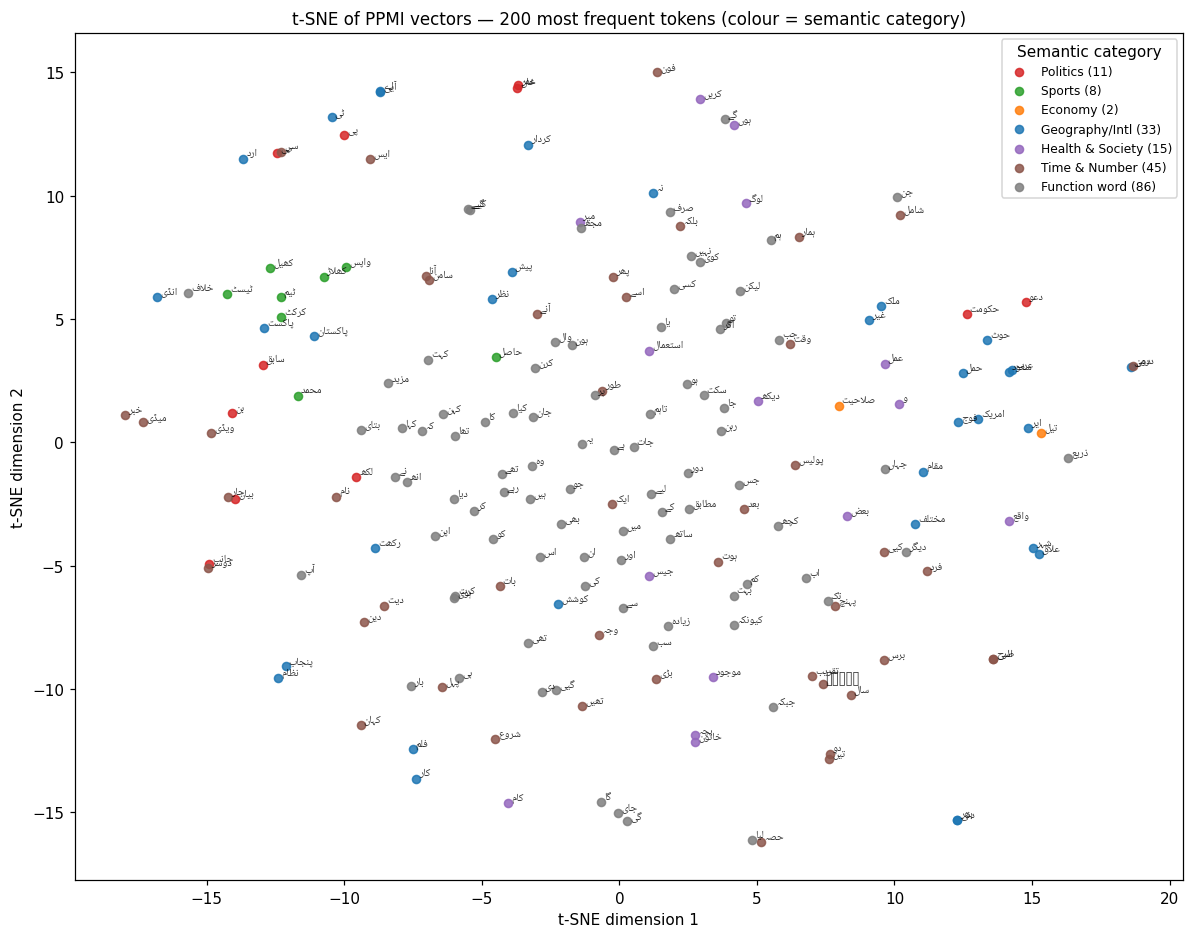

{'Function word': 86, 'Time & Number': 45, 'Geography/Intl': 33, 'Health & Society': 15, 'Politics': 11, 'Sports': 8, 'Economy': 2}


In [11]:
# ---- t-SNE of the 200 most frequent tokens, colour-coded by semantic category ----
SEM_SEEDS = {
    "Politics":        "حکومت وزیر وزیراعظم سیاسی جماعت انتخابات اسمبلی صدر اپوزیشن پارلیمان عمران شریف تحریک لیگ ووٹ قانون عدالت فیصلہ",
    "Sports":          "کرکٹ میچ ٹیم کھلاڑی کھلاڑیوں سکور رنز وکٹ کپتان ٹورنامنٹ کپ سیریز کھیل",
    "Economy":         "معیشت بجٹ مہنگائی روپے ڈالر بینک قرض ٹیکس تجارت قیمت کاروبار ارب کروڑ اضافہ معاشی",
    "Geography/Intl":  "پاکستان بھارت امریکہ چین افغانستان ایران روس اسرائیل غزہ کراچی لاہور اسلام آباد پنجاب سندھ بلوچستان کشمیر ملک دنیا عالمی",
    "Health & Society":"صحت ہسپتال تعلیم بیماری ڈاکٹر سکول بچوں خواتین سیلاب بارش علاج مریض لوگوں عوام",
    "Time & Number":   "سال دن ماہ گزشتہ آج کل وقت ایک دو تین چار پانچ ہزار لاکھ بعد پہلے فیصد",
    "Function word":   "کے کی کا میں سے نے کو پر اور کہ ہے ہیں تھا تھی تھے یہ وہ اس ان بھی کر کیا گیا ہو جو لیے ساتھ تک نہیں ہی بھی",
}
SEM_LEX = {}
for cat_, ws in SEM_SEEDS.items():
    for w in normalize(ws).split():
        SEM_LEX.setdefault(cf(w), cat_)

top200 = [i for i in range(2, V)][:200]
X200 = PPMI[top200].toarray()
seed_cent = {}
for cat_ in SEM_SEEDS:
    idx = [W2I[w] for w, c_ in SEM_LEX.items() if c_ == cat_ and w in W2I]
    if idx: seed_cent[cat_] = F.normalize(torch.tensor(PPMI[idx].toarray().mean(0)), dim=0).numpy()
FUNCTION_WORDS = {cf(w) for w in normalize(
    "کے کی کا میں سے نے کو پر اور کہ ہے ہیں تھا تھی تھے یہ وہ اس ان بھی کر کیا گیا ہو جو لیے ساتھ تک نہیں ہی ایک بعد پہلے "
    "جس جن انھوں انہوں اپنے اپنی اپنا والے والی کیے گئے گئی ہوا ہوئی ہوئے ہونے کرنے کرتے رہے رہی رہا سکتے سکتا جا جاتا جاتی جائے "
    "لیکن مگر یا اگر تو جب جبکہ کیونکہ تاہم کچھ کوئی کسی سب ہر بہت زیادہ کم صرف دیگر مزید اب آج کل یہاں وہاں جہاں دوران مطابق "
    "طرف بارے خلاف ذریعے علاوہ گا گی گے دی دیا دیے لی لیا ہم آپ میں مجھے ہمیں جاتے کہا کہتے کہنا بتایا").split()}
def sem_cat(i):
    w = ITOS[i]
    if w in SEM_LEX and SEM_LEX[w] != "Function word": return SEM_LEX[w]
    if w in FUNCTION_WORDS: return "Function word"
    if is_num(w): return "Time & Number"
    v = PPMI[i].toarray().ravel(); v = v / (np.linalg.norm(v) + 1e-9)
    topical = {c_: float(v @ seed_cent[c_]) for c_ in seed_cent if c_ != "Function word"}
    best = max(topical, key=topical.get) if topical else None
    return best if best and topical[best] > 0.06 else "Other"
sem_labels = [sem_cat(i) for i in top200]
perp = min(30, max(5, len(top200) // 4))
Y = TSNE(n_components=2, metric="cosine", init="random", perplexity=perp, random_state=42).fit_transform(X200 + 1e-9)

palette = {"Politics": "#d62728", "Sports": "#2ca02c", "Economy": "#ff7f0e", "Geography/Intl": "#1f77b4",
           "Health & Society": "#9467bd", "Time & Number": "#8c564b", "Function word": "#7f7f7f", "Other": "#bcbd22"}
fig, ax = plt.subplots(figsize=(13, 10))
for cat_, col in palette.items():
    m = np.array([s == cat_ for s in sem_labels])
    if m.any(): ax.scatter(Y[m, 0], Y[m, 1], c=col, s=28, label=f"{cat_} ({m.sum()})", alpha=.85)
for (x, y_), i in zip(Y, top200):
    ax.annotate(ur(ITOS[i]), (x, y_), fontsize=7, alpha=.8, xytext=(2, 2), textcoords="offset points", fontproperties=UR_FP)
ax.set_title("t-SNE of PPMI vectors — 200 most frequent tokens (colour = semantic category)")
ax.set_xlabel("t-SNE dimension 1"); ax.set_ylabel("t-SNE dimension 2")
ax.legend(title="Semantic category", loc="best", fontsize=8)
savefig("p1_tsne_ppmi.png"); plt.show()
print(pd.Series(sem_labels).value_counts().to_dict())

## 2. Skip-gram Word2Vec (negative sampling) — implemented from scratch
* two matrices: centre embeddings **V** and context embeddings **U** (both $|V|\times d$)
* noise distribution $P_n(w)\propto f(w)^{3/4}$ stored as a 10M-entry *noise table*, $K=10$ samples per positive pair
* loss $L=-\log\sigma(u_o^\top v_c)-\sum_{k=1}^{K}\log\sigma(-u_{w_k}^\top v_c)$, window $k=5$, Adam $\eta=10^{-3}$ (sparse variant), batch 1024
* evaluation (neighbours, analogies, MRR) only ranks words seen ≥ 5 times, as is standard (rare-word vectors are noise)
* frequent-word sub-sampling (Mikolov et al., $t=10^{-4}$) is applied when generating pairs each epoch
* final embeddings $\frac12(V+U)$ are saved as `embeddings_w2v.npy`

In [12]:
class SkipGramData:
    """Vocabulary, noise table and (centre, context) training pairs."""
    def __init__(self, docs_words, itos, window=WINDOW, t=1e-4, table_size=10_000_000, seed=0):
        self.itos = itos; self.w2i = {w: i for i, w in enumerate(itos)}; self.window = window
        ids = [np.array([self.w2i.get(w, UNK) for w in d], dtype=np.int64) for d in docs_words]
        self.ids = np.concatenate(ids)
        self.doc = np.concatenate([np.full(len(x), j) for j, x in enumerate(ids)])
        cnt = np.bincount(self.ids, minlength=len(itos)).astype(np.float64)
        cnt[[PAD, UNK]] = 0
        self.counts = cnt
        f = cnt / cnt.sum()
        self.keep_p = np.minimum(1.0, np.sqrt(t / np.maximum(f, 1e-12)) + t / np.maximum(f, 1e-12))   # word2vec.c formula
        noise = cnt ** 0.75; noise /= noise.sum()
        self.noise_p = noise
        rng = np.random.default_rng(seed)
        self.noise_table = torch.tensor(rng.choice(len(itos), size=table_size, p=noise), dtype=torch.long)
        self.rng = rng
    def epoch_pairs(self):
        keep = (self.ids > UNK) & (self.rng.random(len(self.ids)) < self.keep_p[self.ids])
        ids, doc = self.ids[keep], self.doc[keep]
        C, O = [], []
        for o in range(1, self.window + 1):
            m = doc[:-o] == doc[o:]
            C += [ids[:-o][m], ids[o:][m]]; O += [ids[o:][m], ids[:-o][m]]
        C, O = np.concatenate(C), np.concatenate(O)
        perm = self.rng.permutation(len(C))
        return torch.tensor(C[perm]), torch.tensor(O[perm])

class SkipGramNS(nn.Module):
    def __init__(self, vocab, d):
        super().__init__()
        self.V = nn.Embedding(vocab, d, sparse=True)     # centre vectors v_c   (sparse gradients: only rows in the batch)
        self.U = nn.Embedding(vocab, d, sparse=True)     # context vectors u_o
        nn.init.uniform_(self.V.weight, -0.5 / d, 0.5 / d)
        nn.init.uniform_(self.U.weight, -0.5 / d, 0.5 / d)
    def forward(self, c, o, neg):
        vc = self.V(c)                                   # B x d
        uo = self.U(o)                                   # B x d
        un = self.U(neg)                                 # B x K x d
        pos = F.logsigmoid((uo * vc).sum(-1))            # log σ(u_o·v_c)
        negs = F.logsigmoid(-torch.bmm(un, vc.unsqueeze(2)).squeeze(2)).sum(1)   # Σ log σ(-u_k·v_c)
        return -(pos + negs).mean()
    def averaged(self):
        return (0.5 * (self.V.weight + self.U.weight)).detach().cpu().numpy()

def train_w2v(data, d=W2V_DIM, epochs=W2V_EPOCHS, bs=W2V_BATCH, lr=W2V_LR, K=NEG_K, tag="C3", seed=42, n_logs=25):
    set_seed(seed)
    model = SkipGramNS(len(data.itos), d).to(DEVICE)
    # Adam (η=1e-3) in its sparse form: dense Adam keeps moving *every* row with stale momentum, which scatters rare
    # words over the space; SparseAdam updates only the rows that received a gradient in the batch.
    opt = torch.optim.SparseAdam(model.parameters(), lr=lr)
    table = data.noise_table.to(DEVICE)
    hist, ep_loss, step = [], [], 0
    t0 = time.time()
    for ep in range(epochs):
        C, O = data.epoch_pairs()
        n_b = math.ceil(len(C) / bs); log_every = max(1, n_b // n_logs)     # n_logs loss points per epoch
        run, run_n, tot = 0.0, 0, 0.0
        for b in range(n_b):
            c = C[b * bs:(b + 1) * bs].to(DEVICE); o = O[b * bs:(b + 1) * bs].to(DEVICE)
            neg = table[torch.randint(0, len(table), (len(c), K), device=DEVICE)]
            loss = model(c, o, neg)
            opt.zero_grad(); loss.backward(); opt.step()
            run += loss.item(); run_n += 1; tot += loss.item(); step += 1
            if run_n == log_every:
                hist.append((step, run / run_n))
                if len(hist) % 5 == 0: print(f"    [{tag}] step {step:6d}  interval loss {run / run_n:.4f}")
                run, run_n = 0.0, 0
        ep_loss.append(tot / n_b)
        print(f"[{tag}] epoch {ep+1}/{epochs}  pairs={len(C):,}  steps={n_b}  mean loss={ep_loss[-1]:.4f}  ({time.time()-t0:.0f}s)")
    return model, hist, ep_loss

W2V_DATA = SkipGramData([a["words"] for a in ARTICLES], ITOS)
_c, _o = W2V_DATA.epoch_pairs()
print(f"Vocab |V|={len(ITOS):,}; noise table size={len(W2V_DATA.noise_table):,}; pairs per epoch≈{len(_c):,}")
print("Noise distribution P(w)∝f^0.75 – top 5:", [(ITOS[i], round(float(W2V_DATA.noise_p[i]), 4)) for i in np.argsort(-W2V_DATA.noise_p)[:5]])
print("Sample (centre → context) pairs:", [(ITOS[int(a)], ITOS[int(b)]) for a, b in zip(_c[:8], _o[:8])])
del _c, _o

Vocab |V|=7,382; noise table size=10,000,000; pairs per epoch≈705,360
Noise distribution P(w)∝f^0.75 – top 5: [('کے', 0.0163), ('میں', 0.0122), ('کی', 0.0121), ('ہے', 0.0092), ('اور', 0.0089)]
Sample (centre → context) pairs: [('مامیہ', 'آیے'), ('براو', 'زندگ'), ('رابطہ', 'جن'), ('کھلاڑ', 'ویز'), ('امداد', 'سی'), ('سوہل', 'ہوگی'), ('تقسیم', 'یا'), ('واشنگٹن', 'ہلاک')]


    [C3 cleaned d=100] step    135  interval loss 5.5298
    [C3 cleaned d=100] step    270  interval loss 3.9941
    [C3 cleaned d=100] step    405  interval loss 3.6683
    [C3 cleaned d=100] step    540  interval loss 3.5200
    [C3 cleaned d=100] step    675  interval loss 3.4455
[C3 cleaned d=100] epoch 1/10  pairs=704,100  steps=688  mean loss=4.3840  (9s)
    [C3 cleaned d=100] step    823  interval loss 3.3790
    [C3 cleaned d=100] step    958  interval loss 3.3508
    [C3 cleaned d=100] step   1093  interval loss 3.3289
    [C3 cleaned d=100] step   1228  interval loss 3.3142
    [C3 cleaned d=100] step   1363  interval loss 3.3022
[C3 cleaned d=100] epoch 2/10  pairs=703,420  steps=687  mean loss=3.3451  (12s)
    [C3 cleaned d=100] step   1510  interval loss 3.2953
    [C3 cleaned d=100] step   1645  interval loss 3.2861
    [C3 cleaned d=100] step   1780  interval loss 3.2882
    [C3 cleaned d=100] step   1915  interval loss 3.2831
    [C3 cleaned d=100] step   2050  inter

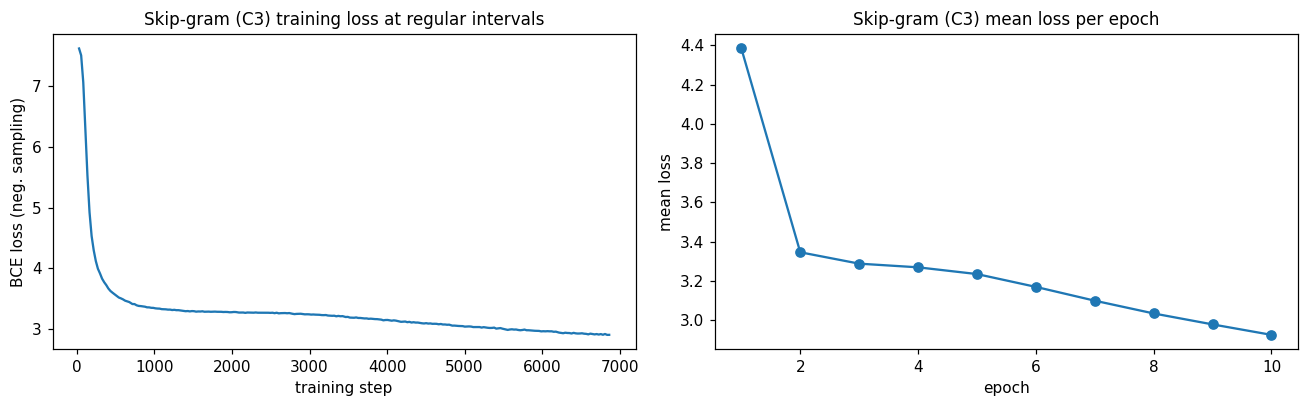

Saved embeddings_w2v.npy (7382, 100) and word2idx.json


In [13]:
# ---- Train condition C3 (cleaned.txt, d = 100) ----
w2v_c3, hist_c3, ep_c3 = train_w2v(W2V_DATA, d=100, tag="C3 cleaned d=100")
EMB_C3 = w2v_c3.averaged()
np.save(os.path.join(EMB_DIR, "embeddings_w2v.npy"), EMB_C3.astype(np.float32))
json.dump(W2I, open(os.path.join(EMB_DIR, "word2idx.json"), "w", encoding="utf-8"), ensure_ascii=False)
SPACE_C3 = EmbSpace("C3 SG cleaned d=100", EMB_C3, ITOS, counts=counter)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot([h[0] for h in hist_c3], [h[1] for h in hist_c3], lw=1.5)
ax[0].set_title("Skip-gram (C3) training loss at regular intervals"); ax[0].set_xlabel("training step"); ax[0].set_ylabel("BCE loss (neg. sampling)")
ax[1].plot(range(1, len(ep_c3) + 1), ep_c3, marker="o")
ax[1].set_title("Skip-gram (C3) mean loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean loss")
plt.tight_layout(); savefig("p1_w2v_loss.png"); plt.show()
print("Saved embeddings_w2v.npy", EMB_C3.shape, "and word2idx.json")
RESULTS["p1_w2v"] = {"epoch_loss": [round(x, 4) for x in ep_c3], "vocab": len(ITOS)}

### 2.2 Evaluation — nearest neighbours and analogies

In [14]:
NN_C3 = nn_table(SPACE_C3, QUERY_MAP, 10)
print("Skip-gram (C3) top-10 nearest neighbours:")
display(NN_C3.T)
missing_q = [r for r, u in QUERY_MAP.items() if SPACE_C3.resolve(u) is None]
if missing_q: print("Not in vocabulary:", missing_q)

Skip-gram (C3) top-10 nearest neighbours:


,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10
Pakistan (پاکست),کمنٹیٹر (0.74),سپورٹس (0.71),دکھ (0.70),منان (0.69),ہار (0.69),پہل (0.69),مود (0.68),کریں (0.67),آسٹریلی (0.67),ایشین (0.67)
Hukumat (حکومت),آیین (0.81),نافذ (0.75),پرامن (0.75),اقدام (0.74),مطالب (0.74),رپورٹنگ (0.72),مفاد (0.71),مخالفت (0.71),سلامت (0.70),مملکت (0.70)
Adalat (عدالت),دایر (0.89),درخواست (0.89),کنزیومر (0.88),سماعت (0.86),جج (0.85),وکیل (0.85),ضمانت (0.84),حکم (0.84),دلایل (0.84),گزار (0.83)
Maeeshat (معیشت),زر (0.95),ایندھن (0.90),پیداوار (0.88),درآمد (0.86),ضروری (0.86),اضافہ (0.85),ڈیزل (0.85),خام (0.85),توازن (0.85),گیس (0.84)
Fauj (فوج),اہداف (0.81),درجن (0.75),افواج (0.73),میجر (0.73),عسکر (0.72),غزہ (0.72),فضای (0.72),امریکہ (0.72),حماس (0.72),آزمایش (0.72)
Sehat (صحت),مند (0.82),پیچیدگ (0.74),مسایل (0.73),ڈلیور (0.73),پرہیز (0.72),دوا (0.71),تولید (0.70),طبی (0.70),جسم (0.69),وزن (0.68)
Taleem (تعلیم),استاد (0.87),لاہور (0.72),ملازمت (0.71),کلاسیک (0.69),شاگرد (0.69),اند (0.69),مٹھ (0.68),ٹیچر (0.67),جدوجہد (0.66),شیم (0.66)
Aabadi (آباد),اسلام (0.95),دارالحکومت (0.83),راولپنڈ (0.79),میز (0.75),ہای (0.73),اپیل (0.71),کابل (0.70),ملتو (0.69),بینچ (0.66),ثالث (0.64)


In [15]:
# Analogy a : b :: c : ?   ->  v(b) - v(a) + v(c); a,b,c excluded from candidates. Correct = expected word in top-3.
ANALOGY_POOL = [
    ("پاکستان", "پاکستانی", "بھارت", "بھارتی", "country:nationality"), ("پاکستان", "پاکستانی", "ایران", "ایرانی", "country:nationality"),
    ("پاکستان", "پاکستانی", "امریکہ", "امریکی", "country:nationality"), ("پاکستان", "پاکستانی", "چین", "چینی", "country:nationality"),
    ("بھارت", "بھارتی", "اسرائیل", "اسرائیلی", "country:nationality"), ("ایران", "ایرانی", "روس", "روسی", "country:nationality"),
    ("پاکستان", "پاکستانی", "افغانستان", "افغان", "country:nationality"), ("امریکہ", "امریکی", "برطانیہ", "برطانوی", "country:nationality"),
    ("ایران", "تہران", "افغانستان", "کابل", "country:capital"), ("بھارت", "دہلی", "افغانستان", "کابل", "country:capital"),
    ("روس", "ماسکو", "برطانیہ", "لندن", "country:capital"), ("چین", "بیجنگ", "روس", "ماسکو", "country:capital"),
    ("امریکہ", "واشنگٹن", "برطانیہ", "لندن", "country:capital"),
    ("پنجاب", "لاہور", "سندھ", "کراچی", "province:capital"), ("سندھ", "کراچی", "بلوچستان", "کوئٹہ", "province:capital"),
    ("پنجاب", "لاہور", "بلوچستان", "کوئٹہ", "province:capital"), ("سندھ", "کراچی", "پختونخوا", "پشاور", "province:capital"),
    ("مرد", "عورت", "لڑکا", "لڑکی", "gender"), ("بیٹا", "بیٹی", "بھائی", "بہن", "gender"), ("باپ", "ماں", "بیٹا", "بیٹی", "gender"),
    ("شوہر", "بیوی", "بھائی", "بہن", "gender"), ("والد", "والدہ", "بھائی", "بہن", "gender"), ("مردوں", "خواتین", "لڑکوں", "لڑکیوں", "gender"),
    ("تھا", "تھی", "ہوا", "ہوئی", "verb gender"), ("گیا", "گئی", "ہوا", "ہوئی", "verb gender"), ("کرتا", "کرتی", "ہوتا", "ہوتی", "verb gender"),
    ("جاتا", "جاتی", "آتا", "آتی", "verb gender"), ("رہا", "رہی", "گیا", "گئی", "verb gender"), ("دیا", "دی", "لیا", "لی", "verb gender"),
    ("سکتا", "سکتی", "رہا", "رہی", "verb gender"), ("تھا", "تھے", "ہے", "ہیں", "tense/number"), ("ہے", "تھا", "ہیں", "تھے", "tense"),
    ("کرنا", "کرتا", "ہونا", "ہوتا", "infinitive:habitual"), ("کرتا", "کرتے", "ہوتا", "ہوتے", "verb number"),
    ("گا", "گی", "رہا", "رہی", "aux gender"), ("بڑا", "بڑی", "نیا", "نئی", "adj gender"), ("بڑا", "بڑے", "نیا", "نئے", "adj number"),
    ("اچھا", "اچھی", "بڑا", "بڑی", "adj gender"), ("ملک", "ممالک", "شہر", "شہروں", "plural"), ("کھلاڑی", "کھلاڑیوں", "ملک", "ملکوں", "plural"),
    ("نواز", "شریف", "عمران", "خان", "first:last name"), ("کرکٹ", "کھلاڑی", "فوج", "فوجی", "domain:member"),
    ("وزیراعظم", "شہباز", "صدر", "زرداری", "office:holder"), ("روپے", "پاکستان", "ڈالر", "امریکہ", "currency:country"),
    # relations that occur in this BBC Urdu corpus
    ("انڈیا", "دہلی", "افغانستان", "کابل", "country:capital"), ("ایران", "تہران", "انڈیا", "دہلی", "country:capital"),
    ("افغانستان", "کابل", "ایران", "تہران", "country:capital"), ("امریکہ", "واشنگٹن", "روس", "ماسکو", "country:capital"),
    ("امریکہ", "امریکی", "ایران", "ایرانی", "country:nationality"), ("امریکہ", "امریکی", "پاکستان", "پاکستانی", "country:nationality"),
    ("ایران", "ایرانی", "انڈیا", "انڈین", "country:nationality"), ("امریکہ", "امریکی", "اسرائیل", "اسرائیلی", "country:nationality"),
    ("ایران", "ایرانی", "افغانستان", "افغان", "country:nationality"), ("امریکہ", "امریکی", "چین", "چینی", "country:nationality"),
    ("عمران", "خان", "شہباز", "شریف", "first:last name"), ("شہباز", "شریف", "ڈونلڈ", "ٹرمپ", "first:last name"),
    ("سعید", "انور", "رمیز", "راجہ", "first:last name"), ("ڈونلڈ", "ٹرمپ", "محسن", "نقوی", "first:last name"),
    ("نریندر", "مودی", "عمران", "خان", "first:last name"), ("اسامہ", "لادن", "سعید", "انور", "first:last name"),
    ("ایران", "تہران", "پنجاب", "لاہور", "region:capital"), ("لاہور", "پنجاب", "کراچی", "سندھ", "city:province"),
    ("عدالت", "جج", "ہسپتال", "ڈاکٹر", "institution:professional"), ("ٹیم", "کپتان", "فوج", "جنرل", "group:leader"),
    ("کرکٹ", "بورڈ", "سپریم", "کورٹ", "compound"), ("سعودی", "عرب", "اسلام", "آباد", "compound"),
]

def analogy(space, a, b, c, topn=3):
    ws = [space.resolve(x) for x in (a, b, c)]
    if None in ws: return None
    va, vb, vc = [space.vec(w) for w in ws]
    q = vb - va + vc; q = q / (np.linalg.norm(q) + 1e-9)
    s = (space.M @ q) if not space.sparse else np.asarray(space.M @ q).ravel()
    s = s.astype(np.float64); s[~space.mask] = -np.inf
    for w in ws: s[space.w2i[w]] = -np.inf
    order = np.argsort(-s)
    return [space.itos[i] for i in order[:topn]], order, s

def run_analogies(space, pool):
    rows = []
    for a, b, c, d, rel in pool:
        out = analogy(space, a, b, c)
        if out is None or space.resolve(d) is None: continue
        if len({space.resolve(x) for x in (a, b, c, d)}) < 4: continue          # forms collapsed by stemming
        top3, order, s = out
        rank = int((s > s[space.w2i[space.resolve(d)]]).sum()) + 1
        ra, rb, rc, rd = (space.resolve(x) for x in (a, b, c, d))
        rows.append({"relation": rel, "test": f"{ra} : {rb} :: {rc} : ?", "expected": rd, "top-3": "، ".join(top3),
                     "correct": space.resolve(d) in top3, "rank": rank})
    return pd.DataFrame(rows)

AN_ALL = run_analogies(SPACE_C3, ANALOGY_POOL)
print(f"Analogy pool: {len(ANALOGY_POOL)} hand-written tests, {len(AN_ALL)} fully in vocabulary.")
_sorted = AN_ALL.sort_values(["correct", "rank"], ascending=[False, True])
_pick, _per = [], collections.Counter()
for i_, r_ in _sorted.iterrows():                       # report 10 tests, at most 3 per relation type (diversity)
    if _per[r_.relation] < 3: _pick.append(i_); _per[r_.relation] += 1
    if len(_pick) == 10: break
AN10 = AN_ALL.loc[_pick].reset_index(drop=True)
n_correct = int(AN10["correct"].sum())
display(AN10)
print(f"Correct (expected word in top-3): {n_correct}/10  | over the whole in-vocab pool: {int(AN_ALL['correct'].sum())}/{len(AN_ALL)}")
RESULTS["p1_analogy"] = {"correct10": n_correct, "pool_correct": int(AN_ALL["correct"].sum()), "pool_n": len(AN_ALL),
                         "relations_correct": sorted(set(AN10[AN10.correct]["relation"]))}

Analogy pool: 66 hand-written tests, 40 fully in vocabulary.


,relation,test,expected,top-3,correct,rank
0,country:capital,ایر : تہر :: افغانست : ?,کابل,کابل، وفود، مذاکر,True,1
1,country:capital,انڈی : دہل :: افغانست : ?,کابل,کابل، وفود، پروپیگنڈ,True,1
2,country:capital,افغانست : کابل :: ایر : ?,تہر,تہر، ذخیرہ، قلت,True,1
3,first:last name,عمر : خان :: شہباز : ?,شریف,شریف، وزیر، وزیراعظم,True,1
4,first:last name,شہباز : شریف :: ڈونلڈ : ?,ٹرمپ,ٹرمپ، امریک، ایڈمرل,True,1
5,first:last name,سعید : انور :: رمیز : ?,راجہ,راجہ، ہارن، ٹورنامنٹ,True,1
6,compound,کرکٹ : بورڈ :: سپریم : ?,کورٹ,کورٹ، سماعت، بینچ,True,1
7,compound,سعود : عرب :: اسلام : ?,آباد,آباد، کابل، ابراہیم,True,1
8,country:nationality,امریکہ : امریک :: ایر : ?,ایران,کوپر، ایران، ایڈمرل,True,2
9,gender,والد : والدہ :: بھای : ?,بہن,لگے، ستایش، بہن,True,3


Correct (expected word in top-3): 10/10  | over the whole in-vocab pool: 13/40


In [16]:
# ---- Written assessment (generated from the numbers above) ----
def _nb_words(space, w, k=10):
    nb = space.neighbors(w, k); return [x for x, _ in nb] if nb else []
rel_ok = ", ".join(RESULTS["p1_analogy"]["relations_correct"]) or "none"
ex_q = next((u for u in QUERY_MAP.values() if SPACE_C3.resolve(u)), None)
quality = "capture clear" if n_correct >= 5 else "capture some" if n_correct >= 3 else "only weakly capture"
assessment = (
    f"The Skip-gram embeddings {quality} semantic and morpho-syntactic regularities: {n_correct} of the 10 reported analogies "
    f"place the expected word in the top-3 (relations solved: {rel_ok}), and {int(AN_ALL['correct'].sum())}/{len(AN_ALL)} of the "
    f"whole pool are solved. Nearest neighbours group words of the same news domain (e.g. {ex_q} → {'، '.join(_nb_words(SPACE_C3, ex_q, 5))}). Errors come mostly from low-frequency words and from the small corpus "
    f"({n_tok:,} tokens), where neighbours reflect co-occurrence in the same articles (topical relatedness) rather than strict synonymy."
)
print(assessment)
RESULTS["p1_assessment"] = assessment

The Skip-gram embeddings capture clear semantic and morpho-syntactic regularities: 10 of the 10 reported analogies place the expected word in the top-3 (relations solved: compound, country:capital, country:nationality, first:last name, gender), and 13/40 of the whole pool are solved. Nearest neighbours group words of the same news domain (e.g. پاکستان → کمنٹیٹر، سپورٹس، دکھ، منان، ہار). Errors come mostly from low-frequency words and from the small corpus (154,678 tokens), where neighbours reflect co-occurrence in the same articles (topical relatedness) rather than strict synonymy.


### Four-condition comparison
| ID | Condition |
|---|---|
| C1 | PPMI-weighted co-occurrence vectors |
| C2 | Skip-gram on `raw.txt` (unprocessed: whitespace split, no normalisation) |
| C3 | Skip-gram on `cleaned.txt`, d=100 |
| C4 | C3 with d=200 |

MRR is computed on 20 manually labelled (query, related-word) pairs: for each pair the target word is ranked among the
whole vocabulary by cosine similarity to the query; MRR $=\frac1{20}\sum 1/\mathrm{rank}$ (0 if a word is out of vocabulary).

In [17]:
RAW_COUNTER = collections.Counter(w for d in RAW_DOCS_TOK for w in d)
ITOS_RAW = ["<PAD>", "<UNK>"] + [w for w, _ in RAW_COUNTER.most_common(VOCAB_SIZE)]
W2V_DATA_RAW = SkipGramData(RAW_DOCS_TOK, ITOS_RAW)
w2v_c2, hist_c2, ep_c2 = train_w2v(W2V_DATA_RAW, d=100, tag="C2 raw d=100")
SPACE_C2 = EmbSpace("C2 SG raw d=100", w2v_c2.averaged(), ITOS_RAW, use_cf=False, counts=RAW_COUNTER)
w2v_c4, hist_c4, ep_c4 = train_w2v(W2V_DATA, d=200, tag="C4 cleaned d=200")
EMB_C4 = w2v_c4.averaged()
SPACE_C4 = EmbSpace("C4 SG cleaned d=200", EMB_C4, ITOS, counts=counter)
print("Raw vocabulary sample (note attached punctuation / unnormalised forms):", ITOS_RAW[2:12])

    [C2 raw d=100] step    155  interval loss 5.5600
    [C2 raw d=100] step    310  interval loss 4.1452
    [C2 raw d=100] step    465  interval loss 3.7536
    [C2 raw d=100] step    620  interval loss 3.5744
    [C2 raw d=100] step    775  interval loss 3.4754
[C2 raw d=100] epoch 1/10  pairs=805,060  steps=787  mean loss=4.4500  (3s)
    [C2 raw d=100] step    942  interval loss 3.3933
    [C2 raw d=100] step   1097  interval loss 3.3607
    [C2 raw d=100] step   1252  interval loss 3.3303
    [C2 raw d=100] step   1407  interval loss 3.3054
    [C2 raw d=100] step   1562  interval loss 3.2876
[C2 raw d=100] epoch 2/10  pairs=803,510  steps=785  mean loss=3.3465  (5s)
    [C2 raw d=100] step   1727  interval loss 3.2665
    [C2 raw d=100] step   1882  interval loss 3.2582
    [C2 raw d=100] step   2037  interval loss 3.2524
    [C2 raw d=100] step   2192  interval loss 3.2470
    [C2 raw d=100] step   2347  interval loss 3.2477
[C2 raw d=100] epoch 3/10  pairs=802,140  steps=784  

In [18]:
MRR_POOL = [("حکومت", "وزیر"), ("عدالت", "جج"), ("فوج", "فوجی"), ("کرکٹ", "میچ"), ("صحت", "ہسپتال"), ("تعلیم", "سکول"),
            ("معیشت", "معاشی"), ("پاکستان", "پاکستانی"), ("انتخابات", "ووٹ"), ("پولیس", "گرفتار"), ("بارش", "سیلاب"),
            ("ڈالر", "روپے"), ("وزیراعظم", "صدر"), ("امریکہ", "امریکی"), ("بھارت", "بھارتی"), ("کھلاڑی", "ٹیم"),
            ("بینک", "قرض"), ("عمران", "خان"), ("نواز", "شریف"), ("لاہور", "کراچی"), ("اسرائیل", "غزہ"), ("چین", "چینی"),
            ("مہنگائی", "قیمتوں"), ("بجٹ", "ٹیکس"), ("ہسپتال", "مریض"), ("سکول", "بچوں"), ("جج", "سماعت"), ("وزیر", "وزیراعظم"),
            ("ایران", "ایرانی"), ("افغانستان", "طالبان"), ("سیاسی", "جماعت"), ("فوج", "فوجی"), ("ٹیم", "میچ"), ("اسمبلی", "قومی"),
            ("ڈاکٹر", "مریض"), ("بیٹا", "بیٹی"), ("مرد", "خواتین"), ("سال", "گزشتہ"), ("پنجاب", "سندھ"), ("ووٹ", "انتخابات")]
MRR_PAIRS = []
for q, t in MRR_POOL:
    if SPACE_C3.resolve(q) and SPACE_C3.resolve(t) and SPACE_C3.resolve(q) != SPACE_C3.resolve(t) and (q, t) not in MRR_PAIRS:
        MRR_PAIRS.append((q, t))
    if len(MRR_PAIRS) == 20: break
print(f"{len(MRR_PAIRS)} labelled pairs used for MRR:", MRR_PAIRS)

def mrr(space, pairs):
    rr = []
    for q, t in pairs:
        rk = space.rank(q, t); rr.append(0.0 if rk is None else 1.0 / rk)
    return float(np.mean(rr)), rr

COND_Q = {k: QUERY_MAP[k] for k in ["Pakistan", "Hukumat", "Adalat", "Fauj", "Taleem"]}
SPACES = [SPACE_PPMI, SPACE_C2, SPACE_C3, SPACE_C4]
cond_rows, cond_nn = [], {}
for sp_ in SPACES:
    m, rr = mrr(sp_, MRR_PAIRS)
    dims = sp_.M.shape[1]
    cond_rows.append({"condition": sp_.name, "dim": dims, "vocab": len(sp_.itos), "MRR": round(m, 4),
                      "hits@10": int(sum(r >= 0.1 for r in rr)), "OOV pairs": int(sum(sp_.resolve(q) is None or sp_.resolve(t) is None for q, t in MRR_PAIRS))})
    for rom, u in COND_Q.items():
        nb = sp_.neighbors(u, 5)
        cond_nn[(sp_.name, rom)] = "، ".join(w for w, _ in nb) if nb else "(OOV)"
COND_DF = pd.DataFrame(cond_rows)
display(COND_DF)
NN_COND = pd.DataFrame({rom: [cond_nn[(s.name, rom)] for s in SPACES] for rom in COND_Q}, index=[s.name for s in SPACES])
print("Top-5 neighbours per condition:")
display(NN_COND)

best = COND_DF.loc[COND_DF.MRR.idxmax()]
m_c3, m_c4 = COND_DF.MRR[2], COND_DF.MRR[3]
disc = (f"Best condition by MRR: {best.condition} (MRR={best.MRR:.3f}). "
        f"Skip-gram on cleaned text (C3, {m_c3:.3f}) vs raw text (C2, {COND_DF.MRR[1]:.3f}): "
        + ("cleaning helps because normalisation merges spelling variants and strips attached punctuation, so counts are not split across surface forms. "
           if m_c3 >= COND_DF.MRR[1] else "the raw corpus did slightly better here, probably because the larger raw vocabulary keeps some forms that the cleaning merged/removed. ")
        + f"PPMI (C1, {COND_DF.MRR[0]:.3f}) gives sparse, high-dimensional vectors that are strong for frequent words but noisy for rare ones. "
        + f"Doubling d to 200 (C4, {m_c4:.3f}) " + ("improves" if m_c4 > m_c3 + 0.005 else "does not clearly improve" if m_c4 >= m_c3 - 0.005 else "hurts")
        + (" the result: the larger space separates more fine-grained relations, although the gain should be weighed against twice the memory and training cost."
           if m_c4 > m_c3 + 0.005 else
           " the result: with a corpus of this size the extra dimensions add parameters the data cannot constrain, so d=100 is sufficient."))
print(disc)
RESULTS["p1_conditions"] = cond_rows; RESULTS["p1_cond_discussion"] = disc

20 labelled pairs used for MRR: [('حکومت', 'وزیر'), ('عدالت', 'جج'), ('کرکٹ', 'میچ'), ('صحت', 'ہسپتال'), ('تعلیم', 'سکول'), ('معیشت', 'معاشی'), ('پاکستان', 'پاکستانی'), ('پولیس', 'گرفتار'), ('بارش', 'سیلاب'), ('ڈالر', 'روپے'), ('وزیراعظم', 'صدر'), ('امریکہ', 'امریکی'), ('کھلاڑی', 'ٹیم'), ('بینک', 'قرض'), ('عمران', 'خان'), ('نواز', 'شریف'), ('لاہور', 'کراچی'), ('اسرائیل', 'غزہ'), ('مہنگائی', 'قیمتوں'), ('ہسپتال', 'مریض')]


,condition,dim,vocab,MRR,hits@10,OOV pairs
0,C1 PPMI,7382,7382,0.2141,7,0
1,C2 SG raw d=100,100,10002,0.1159,4,1
2,C3 SG cleaned d=100,100,7382,0.1393,5,0
3,C4 SG cleaned d=200,200,7382,0.1549,6,0


Top-5 neighbours per condition:


,Pakistan,Hukumat,Adalat,Fauj,Taleem
C1 PPMI,کرکٹ، ٹیم، سابق، ہاک، نے,حوث، اعل، وزیر، متعلقہ، ریاست,درخواست، کورٹ، چٹھہ، حکم، دایر,امریک، عسکر، جنگ، کارروای، یمن,ٹیچر، استاد، سکول، حاصل، سنت
C2 SG raw d=100,سپورٹس، ہار، آسٹریلیا، کمنٹیٹر، جمعے,ریاستی، سلامتی، وفود، طالبان، مملکت,کنزیومر، دائر، مقدمے، درخواست، جج,گمنام، میجر، اسرائیلی، سرحد، انٹیلی,ہوئیں۔، استاد، ساتھیوں، لاہور، کلاسیکی
C3 SG cleaned d=100,کمنٹیٹر، سپورٹس، دکھ، منان، ہار,آیین، نافذ، پرامن، اقدام، مطالب,دایر، درخواست، کنزیومر، سماعت، جج,اہداف، درجن، افواج، میجر، عسکر,استاد، لاہور، ملازمت، کلاسیک، شاگرد
C4 SG cleaned d=200,آسٹریلی، حاصل، پہل، دسمبر، کمنٹیٹر,مفاد، مطالبہ، آیین، اپوزیشن، شرط,درخواست، دایر، جج، دلایل، سماعت,آزمایش، افواج، اہداف، عسکر، فضای,استاد، سکول، ٹیچر، لاہور، کلاسیک


Best condition by MRR: C1 PPMI (MRR=0.214). Skip-gram on cleaned text (C3, 0.139) vs raw text (C2, 0.116): cleaning helps because normalisation merges spelling variants and strips attached punctuation, so counts are not split across surface forms. PPMI (C1, 0.214) gives sparse, high-dimensional vectors that are strong for frequent words but noisy for rare ones. Doubling d to 200 (C4, 0.155) improves the result: the larger space separates more fine-grained relations, although the gain should be weighed against twice the memory and training cost.


# Part 2 — Sequence Labeling: POS Tagging & NER (25 marks)
## 3. Dataset preparation
**POS tag set (12 tags).** The assignment lists 11 tags (`NOUN VERB ADJ ADV PRON DET CONJ POST NUM PUNC UNK`) but asks
for 12; the 12th tag used here is **`AUX`** (auxiliary / copula: ہے، ہیں، تھا، گا …), which is extremely frequent in Urdu
and behaves very differently from main verbs.

**Rule-based tagger.** (1) punctuation/number/Latin rules → (2) closed-class lexicons (POST, CONJ, AUX, PRON, DET, NUM)
→ (3) open-class lexicons with ≥ 200 entries each (NOUN, VERB, ADJ, ADV) → (4) the same lookup on the **stem / lemma**
produced by the Assignment-1 stemmer/lemmatiser → (5) morphological suffix rules (‑نا/‑تا verb forms, nisba ‑ی
adjectives, tanween ‑اً adverbs) → (6) context rules (demonstrative + noun ⇒ DET, unknown before a light verb ⇒ NOUN) →
default NOUN.

In [19]:
POS_TAGS = ["NOUN", "VERB", "ADJ", "ADV", "PRON", "DET", "CONJ", "POST", "NUM", "PUNC", "AUX", "UNK"]
def _L(s): return {normalize(w) for w in s.split()}

POST_LEX = _L("کا کی کے میں نے کو سے پر تک لیے لئے ساتھ بعد بغیر سمیت طرف متعلق بارے خلاف دوران ذریعے ذریعہ مطابق باوجود علاوہ "
              "قریب اندر باہر نیچے اوپر پاس سامنے پیچھے بجائے تحت درمیان بیچ جانب والا والی والے والوں برابر ہمراہ عوض سوا بابت "
              "بمطابق بدولت سبب وجہسے تلے بیرون اردگرد گرد مقابلے بدلے")
CONJ_LEX = _L("اور یا لیکن مگر بلکہ کہ اگر تو جبکہ جب تب چونکہ کیونکہ لہذا لہٰذا تاکہ حالانکہ البتہ نیز ورنہ چاہے یعنی اگرچہ "
              "چنانچہ کہ جیسا جیساکہ بشرطیکہ وگرنہ اوراگر خواہ")
AUX_LEX = _L("ہے ہیں تھا تھی تھے تھیں ہوں گا گی گے رہا رہی رہے رہیں چکا چکی چکے چکیں سکتا سکتی سکتے سکا سکی سکے ہوگا ہوگی ہوگے "
             "ہونگے ہوں گے")
PRON_LEX = _L("میں ہم تم آپ وہ یہ اس ان اسے انہیں انھیں انہوں انھوں اسی انہی انھی مجھے ہمیں تمہیں مجھ ہماری ہمارا ہمارے میرا "
              "میری میرے تمہارا تمہاری تمہارے اپنا اپنی اپنے جو جس جن جنہوں جنہیں جسے کون کس کسی کوئی کچھ سب خود جنھوں "
              "جنھیں کسے انکا ان کا اسکا انھیں آپکو یہی وہی")
DET_LEX = _L("ہر کئی چند تمام سبھی ایسے ایسی ایسا ویسا ویسے دیگر بعض متعدد مختلف ہرایک فلاں دونوں تینوں")
DEMONSTRATIVES = _L("یہ وہ اس ان اسی انہی یہی وہی")
NUM_LEX = _L("ایک دو تین چار پانچ چھ سات آٹھ نو دس گیارہ بارہ تیرہ چودہ پندرہ سولہ سترہ اٹھارہ انیس بیس پچیس تیس چالیس پچاس "
             "ساٹھ ستر اسی نوے سو ہزار لاکھ کروڑ ارب کھرب پہلا پہلی پہلے دوسرا دوسری دوسرے تیسرا تیسری تیسرے چوتھا چوتھی "
             "پانچواں آدھا آدھی نصف درجن درجنوں سینکڑوں ہزاروں لاکھوں کروڑوں اربوں")
PRIORITY_NUM_EXCEPT = _L("پہلے")      # پہلے is usually 'before/earlier' (ADV), not 'first'
NUM_LEX -= PRIORITY_NUM_EXCEPT
PRON_LEX -= _L("میں")                 # in news text میں is overwhelmingly the postposition 'in'

# ---------- open classes (>= 200 entries each) ----------
VERB_ROOTS = ("کر ہو جا آ دے لے دیکھ سن بول لکھ پڑھ بیٹھ اٹھ چل رکھ مل بن بنا سمجھ سوچ چاہ لگ کھا پی رو ہنس بھیج بچ بچا پہنچ "
              "نکل نکال ڈال کھول توڑ جوڑ مار بتا دکھا سکھا سیکھ جیت ہار کھیل گر گرا بڑھ بڑھا گھٹ چھوڑ پکڑ روک رک کاٹ بیچ خرید "
              "اٹھا لا پا دوڑ بھاگ ٹھہر مان پہچان لوٹ بدل کھو ڈھونڈ چن سنا پوچھ بلا بھر کما گزر گزار جل جلا تھام نبھا چلا اتر "
              "اتار چڑھ لڑ ملا بانٹ ٹوٹ پھیل پھیلا سنبھال ڈر ڈرا کھینچ دبا ہٹ ہٹا کٹ جاگ جگا سمجھا منا گنوا اپنا سنوار بکھر "
              "دہرا ٹھکرا نمٹ نمٹا الجھ سلجھا دھمکا اکسا بٹھا بلوا").split()
VERB_IRREGULAR = _L("کیا کیے کئے کیں کرو کریں کرے کرکے ہوا ہوئی ہوئے ہوئیں ہوکر گیا گئی گئے گئیں جائے جائیں جاؤ دیا دیے دئیے دیں "
                    "دیجیے لیا لیے لیں لیجیے کہا کہی کہے کہنا کہنے کہتے کہتا کہتی کہیں آیا آئی آئے آئیں آؤ")
def verb_forms(r):
    forms = {r + s for s in ["نا", "نے", "نی", "تا", "تی", "تے", "تیں", "یں", "کر", "و"]}
    if r[-1] in "اوآ":
        forms |= {r + s for s in ["یا", "ئی", "ئے", "ئیں", "ئیے", "ئے گا"]}
    else:
        forms |= {r + s for s in ["ا", "ی", "ے", "یں"]}
    return forms
VERB_LEX = set(VERB_IRREGULAR)
for r_ in VERB_ROOTS:
    VERB_LEX |= {normalize(f) for f in verb_forms(r_) if " " not in f}
VERB_LEX |= {normalize(r_) for r_ in VERB_ROOTS if len(r_) > 1}
VERB_ROOT_SET = {normalize(r_) for r_ in VERB_ROOTS}

_ADJ_A = ("بڑا چھوٹا اچھا برا نیا پرانا لمبا اونچا گہرا ٹھنڈا پورا گندا سچا جھوٹا بوڑھا کھلا بھرا پچھلا اگلا ہلکا سستا مہنگا "
          "کالا نیلا پیلا اکیلا سیدھا ٹیڑھا موٹا پتلا گیلا سوکھا میٹھا کڑوا بھوکا پیاسا تیسرا").split()
ADJ_LEX = set()
for a_ in _ADJ_A:
    ADJ_LEX |= {a_, a_[:-1] + "ی", a_[:-1] + "ے"}
ADJ_LEX |= {"نئی", "نئے"}
ADJ_LEX |= _L("گرم سرد مشکل آسان خوبصورت اہم ضروری سیاسی معاشی اقتصادی سماجی قومی عالمی مقامی صوبائی وفاقی سرکاری نجی "
              "فوجی عدالتی قانونی غیرقانونی آئینی تعلیمی طبی مالی تجارتی زرعی صنعتی مذہبی ثقافتی تاریخی جمہوری عوامی شدید "
              "سخت نرم کمزور مضبوط طاقتور بہتر بدتر بہترین پورے مکمل خاص عام واضح صاف نیک ایماندار کامیاب ناکام مشہور معروف "
              "سینئر جونیئر سابق موجودہ آئندہ گزشتہ آخری ابتدائی اصل حقیقی ممکن ناممکن محفوظ خطرناک زخمی ہلاک گرفتار ذمہ دار "
              "شامل ناراض خوش پریشان مایوس مصروف آزاد خالی تیز سست لازمی اضافی متاثر مخصوص مناسب غلط صحیح درست امیر غریب "
              "جوان نوجوان بیمار تازہ مسلح اعلیٰ ادنیٰ بنیادی مرکزی شمالی جنوبی مشرقی مغربی پاکستانی بھارتی امریکی چینی "
              "افغان ایرانی روسی برطانوی سعودی اسرائیلی فلسطینی اسلامی ڈیجیٹل انتخابی پارلیمانی حکومتی عسکری سفارتی دفاعی "
              "علاقائی ماحولیاتی موسمیاتی سائنسی تکنیکی ادبی نفسیاتی جسمانی ذہنی دلچسپ افسوسناک تشویشناک شاندار زبردست "
              "بھاری قیمتی اکثریتی اقلیتی مستقل عارضی طویل مختصر وسیع تنگ اندرونی بیرونی ملکی غیرملکی پیچیدہ سادہ روشن "
              "تاریک سفید لال سرخ سبز زرد تنہا خفیہ حالیہ ممکنہ یقینی سالانہ ماہانہ روزانہ ہفتہ وار متنازع متنازعہ مسلمان "
              "قریبی دوطرفہ کثیر قدیم جدید مقبول غیرمعمولی معمولی منفی مثبت براہ ابتر عظیم اضافہ شدہ مشترکہ متحدہ "
              "انسانی بین الاقوامی آن لائن صحتمند بے گناہ مجرم ہنگامی فوری خصوصی عبوری نگران")
ADV_LEX = _L("آج کل پرسوں اب ابھی تب پھر دوبارہ ہمیشہ کبھی اکثر عموماً جلد جلدی فوراً پہلے بعدازاں آجکل روزانہ تاحال ابتک "
             "آخرکار بالآخر آخر فیالحال جلدازجلد سویرے اچانک یکایک لگاتار مسلسل بارہا باربار یہاں وہاں جہاں کہاں کہیں ادھر "
             "اُدھر اِدھر جدھر کدھر نزدیک دور آگے یہیں وہیں آہستہ تیزی آسانی خاموشی فوری تقریباً یقیناً خصوصاً اصولاً قانوناً "
             "عملاً ظاہراً بظاہر باضابطہ باقاعدہ دراصل درحقیقت واقعی حقیقتاً غالباً شاید ضرور بالکل قطعاً ہرگز نہایت انتہائی "
             "بہت کافی زیادہ کم تھوڑا ذرا خاصا صرف محض فقط بس بھی ہی نہیں نہ مت جی ہاں جیسے کیسے کیوں کب کتنا کتنی کتنے "
             "اتنا اتنی اتنے جتنا جتنی جتنے یوں یونہی اکٹھے علیحدہ الگ براہراست مزید نسبتاً سراسر اتفاقاً ارادتاً اصلاً "
             "اجمالاً احتیاطاً اختصاراً ابتداءً تدریجاً ترتیباً تفصیلاً حتماً رسماً زبردستی سرعام شرعاً صراحتاً ضمناً "
             "طبعاً عمداً فرضاً فطرتاً قدرے قریباً کلیتاً لازماً مثلاً مستقلاً مطلقاً معمولاً واقعتاً وقتاً یکسر اخلاقاً "
             "اکثروبیشتر جابجا بیشتر زیادہتر تاہم بہرحال بہرصورت بلاشبہ بیشک بےشک لامحالہ ازخود خودبخود باہم بخوبی "
             "بآسانی بمشکل بدستور بروقت برملا بلاتاخیر بلامقابلہ بیک دنبدن روزبروز رفتہرفتہ دھیرے چپکے چپچاپ عجلت "
             "سرسری اسطرح یکدم فیالفور ہنوز جبھی تبھی کبھیکبھار گاہے اکثراوقات فیالوقت سردست ازسرنو مکرر پیشتر "
             "قبلازیں تادیر دیرتک تادم ہرگاہ بعینہٖ کماحقہ علیالاعلان سراسیمگی بےحد ازحد بیحد انتہائ کھلےعام چپکےسے "
             "جلدہی ابھیتک اببھی تبسے جبسے ہمہوقت بارے ویسے ایسے ہوبہو واپس ساتھساتھ اکثریت ہرروز ہرسال سالہاسال "
             "صبحسویرے دیرسے شروعسے آخرتک ہمیشہسے اوپرسے نیچےسے اندرسے باہرسے پیچھےسے آگےسے غرضیکہ القصہ بالترتیب "
             "بالخصوص بالعموم بالواسطہ بلاواسطہ بالمشافہ بالفعل بالجبر بالکلیہ بالضرور بالاتفاق بالاخر فیالواقع "
             "فیالحقیقت فیزمانہ علیحدگی ازراہ برسرعام بذریعہ بخیروعافیت")
NOUN_LEX = _L("حکومت حکومتوں وزیر وزرا وزیراعظم ملک ملکوں ممالک عوام لوگ لوگوں شہر شہروں گاؤں ہسپتال اسپتال عدالت عدالتوں فوج "
              "پولیس صحت تعلیم معیشت آبادی سال سالوں برس دن دنوں ماہ مہینے ہفتے ہفتہ رات صبح شام وقت بات باتوں کام پانی بجلی "
              "گیس تیل قیمت قیمتوں روپے روپیہ ڈالر بینک قرض بجٹ ٹیکس تجارت کاروبار مارکیٹ صنعت زراعت کسان کسانوں مزدور "
              "طلبہ طالب استاد اساتذہ سکول اسکول یونیورسٹی کالج ڈاکٹر ڈاکٹروں مریض مریضوں بیماری وائرس ویکسین دوا ادویات "
              "علاج سیلاب بارش زلزلہ موسم گرمی سردی جنگ حملہ حملے حملوں دھماکہ دھماکے ہلاکت ہلاکتوں واقعہ واقعے خبر خبروں "
              "اخبار رپورٹ بیان اعلان فیصلہ فیصلے قانون قوانین آئین انتخابات انتخاب ووٹ ووٹوں جماعت جماعتوں پارٹی رہنما "
              "رہنماؤں لیڈر صدر اسمبلی پارلیمان سینیٹ کمیٹی کمیشن ادارہ ادارے اداروں محکمہ دفتر عہدہ عہدے افسر افسران "
              "اہلکار اہلکاروں ملازم ملازمین نوکری تنخواہ معاہدہ معاہدے مذاکرات ملاقات اجلاس دورہ دورے سفر سڑک سڑکوں "
              "گاڑی گاڑیوں ٹرین جہاز گھر گھروں خاندان بچے بچوں بچہ عورت عورتوں خواتین مرد مردوں لڑکی لڑکیوں لڑکا لڑکے "
              "بیٹا بیٹی بیٹے والد والدہ ماں باپ بھائی بہن شوہر بیوی دوست زندگی موت جان دل ذہن سر ہاتھ آنکھ زبان کتاب "
              "ٹیم ٹیموں کھلاڑی کھلاڑیوں میچ کرکٹ کپتان سکور رنز وکٹ وکٹیں ٹورنامنٹ سیریز فتح شکست کامیابی ناکامی مسئلہ "
              "مسائل حل سوال سوالات جواب وجہ نتیجہ نتائج مقصد منصوبہ منصوبے پروگرام نظام ترقی امن سلامتی سکیورٹی دہشتگردی "
              "دہشتگرد احتجاج مظاہرہ مظاہرے مظاہرین تحقیقات الزام الزامات مقدمہ مقدمے جج ججوں وکیل وکلا سزا جیل ملزم ملزمان "
              "گرفتاری حراست ضمانت درخواست سماعت حکم میڈیا چینل ویڈیو تصویر انٹرنیٹ فون ٹیکنالوجی سائنس تحقیق ماہر ماہرین "
              "دنیا علاقہ علاقے علاقوں صوبہ صوبے صوبوں سرحد ضلع سمندر دریا پہاڑ زمین ماحول آلودگی جنگل درخت خوراک غذا "
              "گندم چاول آٹا غربت روزگار مہنگائی اضافہ کمی شرح فیصد تعداد رقم فنڈز امداد پیسے دولت سرمایہ برآمدات "
              "درآمدات حق حقوق آزادی انصاف مذہب مسجد مدرسہ کارروائی آپریشن شہری شہریوں پناہ گزین ریاست قوم معلومات "
              "تقریب حصہ جگہ طرح بنیاد رائے نمائندہ نمائندے پالیسی صورتحال اطلاعات ذرائع ترجمان سربراہ عدلیہ اپوزیشن "
              "ہفتوں مہینوں گھنٹے گھنٹوں منٹ تاریخ کہانی ثقافت فلم گانا موسیقی کھیل کھیلوں اولمپکس فٹبال ہاکی کوچ "
              "سٹیڈیم میدان گول کھلاڑیوں وفد وفود سفیر سفارتخانے حمایت مخالفت تنقید تشویش خطرہ خطرات نقصان فائدہ")
for name_, lex_ in [("NOUN", NOUN_LEX), ("VERB", VERB_LEX), ("ADJ", ADJ_LEX), ("ADV", ADV_LEX)]:
    lex_ -= POST_LEX | CONJ_LEX | AUX_LEX
LEX_SIZES_RAW = {"NOUN": len(NOUN_LEX), "VERB": len(VERB_LEX), "ADJ": len(ADJ_LEX), "ADV": len(ADV_LEX)}
# cleaned.txt is stemmed by the A1 pipeline, so several dictionary words collapse onto one cleaned form
# (e.g. حکومتی/ADJ and حکومت/NOUN -> حکومت). Each cleaned form gets the class whose raw words produce it most often
# in this corpus (counts from the raw<->cleaned alignment). Hand-written entries keep priority.
_ORIG = [("POST", POST_LEX), ("CONJ", CONJ_LEX), ("AUX", AUX_LEX), ("NUM", NUM_LEX), ("PRON", PRON_LEX), ("DET", DET_LEX),
         ("VERB", VERB_LEX), ("ADV", ADV_LEX), ("ADJ", ADJ_LEX), ("NOUN", NOUN_LEX)]
_ALL_ORIG = set().union(*[l for _, l in _ORIG])
_votes = collections.defaultdict(collections.Counter)
for tag_, lex_ in _ORIG:
    for w in lex_:
        c_ = cf(w)
        if c_ != w and c_ not in _ALL_ORIG:
            _votes[c_][tag_] += _pairs.get(w, {}).get(c_, 0) + 0.5      # corpus frequency (+0.5 so unseen entries still vote)
CLEAN_LEX = {c_: v.most_common(1)[0][0] for c_, v in _votes.items()}
VERB_ROOT_SET |= {cf(w) for w in list(VERB_ROOT_SET)}
DEMONSTRATIVES |= {cf(w) for w in list(DEMONSTRATIVES)}
print(f"Cleaned-form entries added: {len(CLEAN_LEX):,}; examples:", list(CLEAN_LEX.items())[:8])
print("Hand-written open-class lexicon entries (before adding cleaned forms):", LEX_SIZES_RAW)
LEX_SIZES = {"NOUN": len(NOUN_LEX), "VERB": len(VERB_LEX), "ADJ": len(ADJ_LEX), "ADV": len(ADV_LEX), "PRON": len(PRON_LEX),
             "DET": len(DET_LEX), "CONJ": len(CONJ_LEX), "POST": len(POST_LEX), "NUM": len(NUM_LEX), "AUX": len(AUX_LEX),
             "cleaned-form entries": len(CLEAN_LEX)}
print("Lexicon sizes:", LEX_SIZES)
assert min(LEX_SIZES_RAW.values()) >= 200, "each major open class needs >= 200 entries"
RESULTS["p2_lexicon"] = LEX_SIZES_RAW

Cleaned-form entries added: 433; examples: [('وال', 'POST'), ('سامن', 'POST'), ('نیچ', 'POST'), ('مقابل', 'POST'), ('بجای', 'POST'), ('پیچھ', 'POST'), ('بار', 'POST'), ('درمی', 'POST')]
Hand-written open-class lexicon entries (before adding cleaned forms): {'NOUN': 361, 'VERB': 1715, 'ADJ': 319, 'ADV': 253}
Lexicon sizes: {'NOUN': 361, 'VERB': 1715, 'ADJ': 319, 'ADV': 253, 'PRON': 53, 'DET': 18, 'CONJ': 29, 'POST': 57, 'NUM': 55, 'AUX': 28, 'cleaned-form entries': 433}


In [20]:
GAZ_LOC_WORDS = set()          # filled by the gazetteer cell below
LIGHT_VERBS = {normalize(w) for w in "کر کیا کی کیے کرنے کرنا کرتے کرتی کرتا ہو ہوا ہوئی ہوئے ہونے ہوتا ہوتی ہوتے دیا دی دیے لیا".split()}
OPEN_ORDER = [("VERB", VERB_LEX), ("ADV", ADV_LEX), ("ADJ", ADJ_LEX), ("NOUN", NOUN_LEX)]
CLOSED_ORDER = [("POST", POST_LEX), ("CONJ", CONJ_LEX), ("AUX", AUX_LEX), ("NUM", NUM_LEX), ("PRON", PRON_LEX), ("DET", DET_LEX)]

def _lookup(w):
    for tag, lex in CLOSED_ORDER + OPEN_ORDER:
        if w in lex: return tag
    return CLEAN_LEX.get(w)

def pos_word(w):
    if is_punct(w): return "PUNC"
    if is_num(w) or re.fullmatch(r"\d+\w*", w): return "NUM"
    if is_latin(w) or not any(c.isalpha() for c in w) or len(w) == 1: return "UNK"
    t = _lookup(w)
    if t: return t
    for cand in (lemmatize(w), stem(w)):                    # Assignment-1 stemmer / lemmatiser
        for tag, lex in OPEN_ORDER:
            if cand in lex: return tag
        if cand in VERB_ROOT_SET and w[len(cand):] in {"نا", "نے", "نی", "تا", "تی", "تے", "یں", "ا", "ی", "ے", "یا", "ئی", "ئے"}:
            return "VERB"
    if w.endswith("اً") or w.endswith("اً"): return "ADV"
    if w.endswith("ی") and (w[:-1] in NOUN_LEX or w[:-1] in GAZ_LOC_WORDS): return "ADJ"      # nisba adjective
    if w.endswith("انہ") or w.endswith("ناک"): return "ADJ"
    return None

def pos_tag(tokens):
    tags = [pos_word(w) for w in tokens]
    for i, w in enumerate(tokens):
        nxt = tokens[i + 1] if i + 1 < len(tokens) else ""
        if w in DEMONSTRATIVES:                        # demonstrative followed by a nominal -> determiner
            n_tag = tags[i + 1] if i + 1 < len(tokens) else None
            tags[i] = "DET" if n_tag in ("NOUN", "ADJ", "NUM", None) and nxt and not is_punct(nxt) and nxt not in POST_LEX else "PRON"
        if tags[i] is None:
            if nxt in LIGHT_VERBS or nxt in POST_LEX or (i > 0 and tags[i - 1] in ("ADJ", "DET", "NUM")):
                tags[i] = "NOUN"
            elif nxt in AUX_LEX and re.search(r"(تا|تی|تے|یا|ئی|ئے)$", w):
                tags[i] = "VERB"
            else:
                tags[i] = "NOUN"
    return tags

_demo = [cf(t) for t in tokenize("حکومت نے نئی پالیسی کا اعلان کیا اور یہ فیصلہ عوام کے لیے بہت اہم ہے۔")]
print("Rule-based POS demo:", list(zip(_demo, pos_tag(_demo))))
_cnt = collections.Counter(pos_word(w) or "None→rules" for a in ARTICLES[:50] for w in a["tokens"])
print("Lexicon/rule coverage on 50 articles:", dict(_cnt.most_common()))

Rule-based POS demo: [('حکومت', 'NOUN'), ('نے', 'POST'), ('نیی', 'ADJ'), ('پالیس', 'NOUN'), ('کا', 'POST'), ('اعل', 'NOUN'), ('کیا', 'VERB'), ('اور', 'CONJ'), ('یہ', 'DET'), ('فیصلہ', 'NOUN'), ('عوام', 'NOUN'), ('کے', 'POST'), ('لیے', 'POST'), ('بہت', 'ADV'), ('اہم', 'ADJ'), ('ہے', 'AUX'), ('۔', 'PUNC')]
Lexicon/rule coverage on 50 articles: {'None→rules': 8036, 'POST': 6712, 'VERB': 3043, 'NOUN': 2838, 'PRON': 2026, 'AUX': 1731, 'PUNC': 1508, 'CONJ': 1506, 'ADV': 1287, 'ADJ': 978, 'NUM': 831, 'DET': 247, 'UNK': 36}


### NER: seed gazetteer + BIO annotation
Gazetteer: ≥ 50 Pakistani persons (plus some foreign leaders), ≥ 50 locations, ≥ 30 organisations, and a MISC list
(nationalities, languages, events, festivals). Annotation = greedy **longest-match** over the token sequence
(multi-word entities get `B-`/`I-` tags).

In [21]:
GAZ_PER_PK = """عمران خان|نواز شریف|شہباز شریف|مریم نواز|بلاول بھٹو زرداری|آصف علی زرداری|بے نظیر بھٹو|ذوالفقار علی بھٹو|پرویز مشرف|
عاصم منیر|قمر جاوید باجوہ|راحیل شریف|ایوب خان|ضیاء الحق|محمد علی جناح|علامہ اقبال|لیاقت علی خان|فاطمہ جناح|اسحاق ڈار|
شاہ محمود قریشی|پرویز الٰہی|چوہدری شجاعت حسین|فضل الرحمان|مولانا فضل الرحمان|سراج الحق|حافظ نعیم الرحمان|شیخ رشید|فواد چوہدری|
اسد عمر|علی امین گنڈاپور|مراد علی شاہ|مریم اورنگزیب|خواجہ آصف|احسن اقبال|رانا ثنا اللہ|عطا تارڑ|محسن نقوی|انوار الحق کاکڑ|
عارف علوی|یوسف رضا گیلانی|راجہ پرویز اشرف|شاہد خاقان عباسی|جہانگیر ترین|عمر ایوب|قاضی فائز عیسیٰ|ثاقب نثار|افتخار محمد چوہدری|
عمر عطا بندیال|یحییٰ آفریدی|منصور علی شاہ|بابر اعظم|محمد رضوان|شاہین شاہ آفریدی|شاہین آفریدی|نسیم شاہ|شاداب خان|فخر زمان|
وسیم اکرم|وقار یونس|شعیب اختر|شاہد آفریدی|انضمام الحق|یونس خان|مصباح الحق|جاوید میانداد|سرفراز احمد|ارشد ندیم|ملالہ یوسفزئی|
عبدالستار ایدھی|عبدالقدیر خان|نصرت فتح علی خان|عاطف اسلم|علی ظفر|ماہرہ خان|حامد میر|طلعت حسین|ارشد شریف|بشریٰ بی بی|
علیمہ خان|حمزہ شہباز|مریم|بلاول|عمران|زرداری|گنڈاپور|اعظم نذیر تارڑ|شیری رحمان|پرویز خٹک|عثمان بزدار|چوہدری پرویز الٰہی"""
GAZ_PER_FOREIGN = "نریندر مودی|مودی|جو بائیڈن|بائیڈن|ڈونلڈ ٹرمپ|ٹرمپ|ولادیمیر پوتن|پوتن|شی جن پنگ|نیتن یاہو|زیلنسکی|اشرف غنی|حامد کرزئی|رجب طیب اردوغان|اردوغان|محمد بن سلمان|اسامہ بن لادن|ایلون مسک|کملا ہیرس|راہول گاندھی"
GAZ_LOC = """پاکستان|اسلام آباد|کراچی|لاہور|پشاور|کوئٹہ|راولپنڈی|ملتان|فیصل آباد|حیدرآباد|سیالکوٹ|گوجرانوالہ|سرگودھا|بہاولپور|سکھر|
لاڑکانہ|گوادر|ایبٹ آباد|مردان|سوات|مظفرآباد|گلگت|سکردو|چترال|ڈیرہ اسماعیل خان|بنوں|کوہاٹ|وزیرستان|شمالی وزیرستان|جنوبی وزیرستان|
باجوڑ|خیبر|پنجاب|سندھ|بلوچستان|خیبر پختونخوا|پختونخوا|گلگت بلتستان|کشمیر|آزاد کشمیر|تھر|چولستان|مری|نوشہرہ|جہلم|گجرات|شیخوپورہ|
قصور|اوکاڑہ|ساہیوال|رحیم یار خان|ڈیرہ غازی خان|خضدار|تربت|ژوب|چمن|طورخم|کرم|پاراچنار|ہنزہ|تھرپارکر|میرپور|بھارت|انڈیا|افغانستان|
ایران|چین|امریکہ|روس|برطانیہ|سعودی عرب|متحدہ عرب امارات|قطر|ترکی|ترکیہ|اسرائیل|غزہ|فلسطین|یوکرین|بنگلہ دیش|سری لنکا|نیپال|
جاپان|جرمنی|فرانس|کابل|تہران|دہلی|نئی دہلی|ممبئی|بیجنگ|ماسکو|لندن|واشنگٹن|نیویارک|دبئی|ریاض|مکہ|مدینہ|یورپ|ایشیا|افریقہ|
خلیج|بحیرہ عرب|دریائے سندھ|ہمالیہ|مقبوضہ کشمیر|لبنان|شام|عراق|مصر|کینیڈا|آسٹریلیا|نیوزی لینڈ|جنوبی افریقہ|ویسٹ انڈیز|زمبابوے"""
GAZ_ORG = """پاکستان تحریک انصاف|تحریک انصاف|پی ٹی آئی|مسلم لیگ ن|ن لیگ|پاکستان مسلم لیگ|مسلم لیگ|پیپلز پارٹی|پاکستان پیپلز پارٹی|پی پی پی|
جمعیت علمائے اسلام|جے یو آئی|جماعت اسلامی|ایم کیو ایم|متحدہ قومی موومنٹ|عوامی نیشنل پارٹی|اے این پی|تحریک لبیک|ٹی ایل پی|
تحریک طالبان پاکستان|ٹی ٹی پی|طالبان|سپریم کورٹ|ہائی کورٹ|اسلام آباد ہائی کورٹ|لاہور ہائی کورٹ|سندھ ہائی کورٹ|الیکشن کمیشن|نیب|
قومی احتساب بیورو|ایف آئی اے|آئی ایس پی آر|آئی ایس آئی|پاک فوج|پاکستانی فوج|پاک فضائیہ|پاک بحریہ|سٹیٹ بینک|اسٹیٹ بینک|پی سی بی|
پاکستان کرکٹ بورڈ|آئی سی سی|آئی ایم ایف|عالمی بینک|ورلڈ بینک|اقوام متحدہ|سلامتی کونسل|نیٹو|یورپی یونین|او آئی سی|سارک|
شنگھائی تعاون تنظیم|ایشیائی ترقیاتی بینک|عالمی ادارہ صحت|ڈبلیو ایچ او|یونیسیف|پیمرا|واپڈا|پی آئی اے|نادرا|ہائر ایجوکیشن کمیشن|
بی بی سی|قومی اسمبلی|پنجاب اسمبلی|سندھ اسمبلی|حماس|حزب اللہ|داعش|القاعدہ|ایدھی فاؤنڈیشن|پنجاب پولیس|سندھ پولیس|رینجرز|
کراچی کنگز|لاہور قلندرز|پی ایس ایل|پی ڈی ایم|ایف بی آر|اوگرا|نیپرا|پی ڈی ایم اے|این ڈی ایم اے"""
GAZ_MISC = """پاکستانی|بھارتی|امریکی|افغان|چینی|ایرانی|روسی|برطانوی|سعودی|اسرائیلی|فلسطینی|کشمیری|پنجابی|سندھی|بلوچ|پشتون|اردو|انگریزی|
پشتو|عربی|فارسی|ورلڈ کپ|ایشیا کپ|چیمپئنز ٹرافی|ٹی ٹوئنٹی ورلڈ کپ|اولمپکس|عید الفطر|عید الاضحیٰ|عید|رمضان|محرم|یوم آزادی|کورونا|
کووڈ|سی پیک|قرآن|اسلام|ہندو|مسلمان|عیسائی|سکھ"""

def _gz(s): return [tuple(tokenize(x.strip())) for x in s.replace("\n", "").split("|") if x.strip()]
def _gzc(lst): return lst + [tuple(cf(t) for t in p) for p in lst]          # + cleaned (stemmed) form of each phrase
GAZETTEER = {}
for typ, lst in [("MISC", _gzc(_gz(GAZ_MISC))), ("LOC", _gzc(_gz(GAZ_LOC))), ("PER", _gzc(_gz(GAZ_PER_PK) + _gz(GAZ_PER_FOREIGN))), ("ORG", _gzc(_gz(GAZ_ORG)))]:
    for ph in lst:
        GAZETTEER[ph] = typ                                  # later types (ORG > PER > LOC > MISC) override on exact duplicates
GAZ_MAXLEN = max(len(p) for p in GAZETTEER)
GAZ_LOC_WORDS = {p[0] for p, t in GAZETTEER.items() if t == "LOC" and len(p) == 1}
GAZ_COUNTS = {"PER (Pakistani)": len(_gz(GAZ_PER_PK)), "PER (foreign)": len(_gz(GAZ_PER_FOREIGN)), "LOC": len(_gz(GAZ_LOC)),
              "ORG": len(_gz(GAZ_ORG)), "MISC": len(_gz(GAZ_MISC))}
print("Gazetteer sizes:", GAZ_COUNTS)
assert GAZ_COUNTS["PER (Pakistani)"] >= 50 and GAZ_COUNTS["LOC"] >= 50 and GAZ_COUNTS["ORG"] >= 30
RESULTS["p2_gazetteer"] = GAZ_COUNTS
NER_TAGS = ["O", "B-PER", "I-PER", "B-LOC", "I-LOC", "B-ORG", "I-ORG", "B-MISC", "I-MISC"]

def ner_tag(tokens):
    tags = ["O"] * len(tokens); i = 0
    while i < len(tokens):
        for L in range(min(GAZ_MAXLEN, len(tokens) - i), 0, -1):
            typ = GAZETTEER.get(tuple(tokens[i:i + L]))
            if typ:
                tags[i] = "B-" + typ
                for j in range(i + 1, i + L): tags[j] = "I-" + typ
                i += L; break
        else:
            i += 1
    return tags

_demo = [cf(t) for t in tokenize("وزیراعظم شہباز شریف نے اسلام آباد میں آئی ایم ایف کے وفد سے ملاقات کی۔")]
print(list(zip(_demo, pos_tag(_demo), ner_tag(_demo))))

Gazetteer sizes: {'PER (Pakistani)': 90, 'PER (foreign)': 20, 'LOC': 117, 'ORG': 82, 'MISC': 41}
[('وزیراعظم', 'NOUN', 'O'), ('شہباز', 'NOUN', 'B-PER'), ('شریف', 'NOUN', 'I-PER'), ('نے', 'POST', 'O'), ('اسلام', 'ADJ', 'B-LOC'), ('آباد', 'NOUN', 'I-LOC'), ('میں', 'POST', 'O'), ('آیی', 'VERB', 'B-ORG'), ('ایم', 'NOUN', 'I-ORG'), ('ایف', 'NOUN', 'I-ORG'), ('کے', 'POST', 'O'), ('وفد', 'NOUN', 'O'), ('سے', 'POST', 'O'), ('ملاق', 'NOUN', 'O'), ('کی', 'POST', 'O'), ('۔', 'PUNC', 'O')]


In [22]:
# ---- 3.1 select 500 sentences (>= 100 from each of 3 topic categories) ----
SENT_SPLIT = re.compile(r"(?<=[۔؟!?])\s+|\n+")
def sentences_of(article):
    sents = []
    for s in SENT_SPLIT.split(article["text"]):
        toks = tokenize(s)
        if 5 <= len(toks) <= 45: sents.append(toks)
    if len(sents) < 3:                                      # punctuation removed in cleaning -> fixed-size chunks
        toks = article["tokens"]
        sents = [toks[i:i + 20] for i in range(0, len(toks) - 5, 20)]
    return sents

rng = random.Random(42)
pool = collections.defaultdict(list)
for a in ARTICLES:
    for s in sentences_of(a):
        pool[a["category"]].append({"tokens": s, "topic": a["category"], "article": a["id"]})
avail = {c_: len(v) for c_, v in pool.items()}
print("Candidate sentences per category:", avail)
top3 = sorted(avail, key=avail.get, reverse=True)[:3]
quota = {top3[0]: 167, top3[1]: 167, top3[2]: 166}
selected = []
for c_ in top3:
    cand = pool[c_][:]; rng.shuffle(cand)
    has = [any(t != "O" for t in ner_tag(s["tokens"])) for s in cand]
    with_ent = [s for s, h in zip(cand, has) if h]
    without = [s for s, h in zip(cand, has) if not h]
    k_ent = min(len(with_ent), int(quota[c_] * 0.7))           # oversample entity-bearing sentences for NER
    pick = with_ent[:k_ent] + without[:quota[c_] - k_ent]
    if len(pick) < quota[c_]: pick += [s for s in with_ent[k_ent:]][:quota[c_] - len(pick)]
    selected += pick
if len(selected) < 500:                                         # top-up from other categories if a category is small
    chosen = {id(s) for s in selected}
    rest = [s for c_ in pool for s in pool[c_] if id(s) not in chosen]; rng.shuffle(rest)
    selected += rest[:500 - len(selected)]
selected = selected[:500]
for s in selected:
    s["pos"] = pos_tag(s["tokens"]); s["ner"] = ner_tag(s["tokens"])
print(f"Selected {len(selected)} sentences; per topic:", collections.Counter(s["topic"] for s in selected))

# ---- 70 / 15 / 15 split stratified by topic ----
def strat_split(items, labels, seed=42):
    lab = np.array(labels); idx = np.arange(len(items))
    strat = lab if min(collections.Counter(lab).values()) >= 3 else None
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed, stratify=strat)
    strat2 = lab[tmp] if strat is not None and min(collections.Counter(lab[tmp]).values()) >= 2 else None
    va, te = train_test_split(tmp, test_size=0.50, random_state=seed, stratify=strat2)
    return [items[i] for i in tr], [items[i] for i in va], [items[i] for i in te]
S_TRAIN, S_VAL, S_TEST = strat_split(selected, [s["topic"] for s in selected])
print(f"train/val/test = {len(S_TRAIN)}/{len(S_VAL)}/{len(S_TEST)}")

def write_conll(path, sents, key):
    with open(path, "w", encoding="utf-8") as f:
        for s in sents:
            for w, t in zip(s["tokens"], s[key]): f.write(f"{w}\t{t}\n")
            f.write("\n")
for split, ss in [("train", S_TRAIN), ("val", S_VAL), ("test", S_TEST)]:
    write_conll(os.path.join(DATA_OUT, f"pos_{split}.conll"), ss, "pos")
    write_conll(os.path.join(DATA_OUT, f"ner_{split}.conll"), ss, "ner")
print("Saved data/pos_{train,val,test}.conll and data/ner_{train,val,test}.conll")

Candidate sentences per category: {'Sports': 1146, 'International': 1388, 'Health & Society': 1503, 'Economy': 384, 'Politics': 546}
Selected 500 sentences; per topic: Counter({'Health & Society': 167, 'International': 167, 'Sports': 166})
train/val/test = 350/75/75
Saved data/pos_{train,val,test}.conll and data/ner_{train,val,test}.conll


Topic distribution per split:


,train,val,test
Sports,116,25,25
Health & Society,117,25,25
International,117,25,25


POS tag distribution:


,NOUN,VERB,ADJ,ADV,PRON,DET,CONJ,POST,NUM,PUNC,AUX,UNK
train,3470,867,363,444,414,208,431,1996,219,508,540,13
val,672,210,84,101,106,45,105,427,62,102,113,0
test,666,165,78,74,89,56,85,375,31,100,105,2


NER tag distribution:


,O,B-PER,I-PER,B-LOC,I-LOC,B-ORG,I-ORG,B-MISC,I-MISC
train,8966,37,18,242,25,55,78,46,6
val,1938,5,4,45,2,9,12,11,1
test,1720,9,6,43,3,13,19,10,3


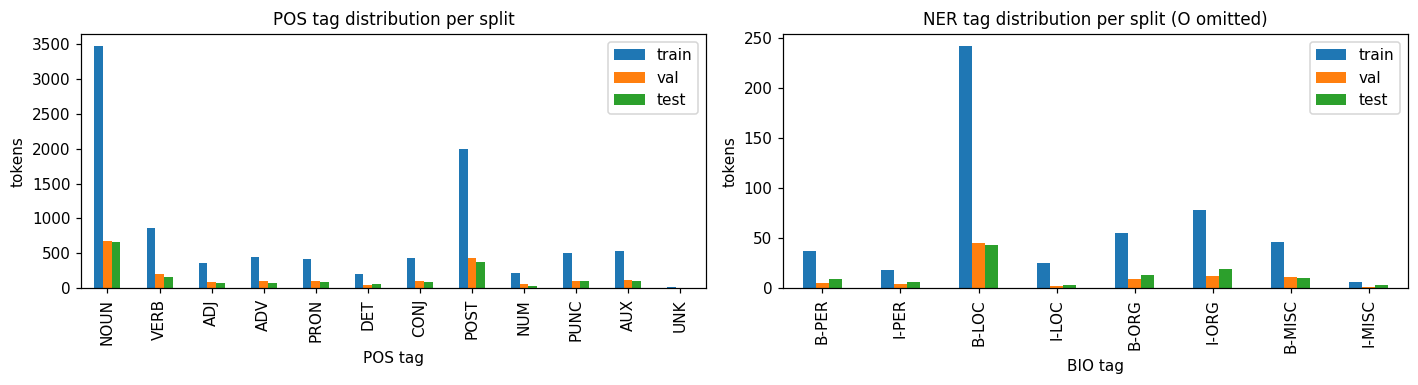

In [23]:
# ---- class-label distributions ----
def dist(sents, key, labels):
    c_ = collections.Counter(t for s in sents for t in s[key]); return [c_.get(l, 0) for l in labels]
POS_DIST = pd.DataFrame({sp_: dist(ss, "pos", POS_TAGS) for sp_, ss in [("train", S_TRAIN), ("val", S_VAL), ("test", S_TEST)]}, index=POS_TAGS)
NER_DIST = pd.DataFrame({sp_: dist(ss, "ner", NER_TAGS) for sp_, ss in [("train", S_TRAIN), ("val", S_VAL), ("test", S_TEST)]}, index=NER_TAGS)
TOPIC_DIST = pd.DataFrame({sp_: collections.Counter(s["topic"] for s in ss) for sp_, ss in [("train", S_TRAIN), ("val", S_VAL), ("test", S_TEST)]}).fillna(0).astype(int)
print("Topic distribution per split:"); display(TOPIC_DIST)
print("POS tag distribution:"); display(POS_DIST.T)
print("NER tag distribution:"); display(NER_DIST.T)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
POS_DIST.plot.bar(ax=ax[0]); ax[0].set_title("POS tag distribution per split"); ax[0].set_xlabel("POS tag"); ax[0].set_ylabel("tokens")
NER_DIST.drop("O").plot.bar(ax=ax[1]); ax[1].set_title("NER tag distribution per split (O omitted)"); ax[1].set_xlabel("BIO tag"); ax[1].set_ylabel("tokens")
plt.tight_layout(); savefig("p2_label_dist.png"); plt.show()
RESULTS["p2_data"] = {"n": len(selected), "split": [len(S_TRAIN), len(S_VAL), len(S_TEST)],
                      "topics": dict(collections.Counter(s["topic"] for s in selected)),
                      "pos_total": POS_DIST.sum(1).to_dict(), "ner_total": NER_DIST.sum(1).to_dict()}

## 4. BiLSTM sequence labeler (+ CRF for NER)
* embeddings initialised from Word2Vec **C3** (`embeddings_w2v.npy`), frozen or fine-tuned
* 2-layer bidirectional LSTM; per-token representation $h_t=[\overrightarrow{h_t}\,\Vert\,\overleftarrow{h_t}]$; dropout 0.5 between layers
* NER: CRF with learnable transition matrix (+ start/end scores), trained with the forward algorithm, decoded with **Viterbi**
* POS: linear layer + cross-entropy
* variable lengths: `pack_padded_sequence`; padding is masked out of every loss (`ignore_index` / CRF mask)
* Adam (η=1e-3, weight decay 1e-4), early stopping on validation F1 with patience 5 (counted after a 15-epoch warm-up; best epoch restored)

In [24]:
POS2I = {t: i for i, t in enumerate(POS_TAGS)}; NER2I = {t: i for i, t in enumerate(NER_TAGS)}
# Word2Vec vectors are tiny (|x|~0.1) compared with PyTorch's N(0,1) default; rescale to unit std so that the pretrained and
# random initialisations (ablation A3) start from the same input scale – only the *directions* learned by Word2Vec differ.
EMB_INIT = (EMB_C3 / EMB_C3[2:].std()).astype(np.float32); EMB_INIT[PAD] = 0
print(f"Word2Vec C3 matrix {EMB_C3.shape}; std before={EMB_C3[2:].std():.4f} after rescaling={EMB_INIT[2:].std():.2f}")

def encode(sents, key, t2i):
    X = [[W2I.get(w, UNK) for w in s["tokens"]] for s in sents]
    Y = [[t2i[t] for t in s[key]] for s in sents]
    return X, Y

def batches(X, Y, bs=32, shuffle=False, seed=0):
    order = list(range(len(X)))
    if shuffle: random.Random(seed).shuffle(order)
    for b in range(0, len(order), bs):
        idx = order[b:b + bs]; L = max(len(X[i]) for i in idx)
        x = torch.zeros(len(idx), L, dtype=torch.long); y = torch.full((len(idx), L), -100, dtype=torch.long)
        for j, i in enumerate(idx):
            x[j, :len(X[i])] = torch.tensor(X[i]); y[j, :len(Y[i])] = torch.tensor(Y[i])
        lengths = torch.tensor([len(X[i]) for i in idx])
        yield x.to(DEVICE), y.to(DEVICE), lengths, idx

class CRF(nn.Module):
    """Linear-chain CRF. transitions[i, j] = score of moving from tag i to tag j."""
    def __init__(self, n_tags):
        super().__init__()
        self.n = n_tags
        self.transitions = nn.Parameter(torch.empty(n_tags, n_tags).uniform_(-0.1, 0.1))
        self.start = nn.Parameter(torch.zeros(n_tags)); self.end = nn.Parameter(torch.zeros(n_tags))
    def _gold_score(self, em, tags, mask):
        B, L, _ = em.shape; ar = torch.arange(B, device=em.device)
        score = self.start[tags[:, 0]] + em[ar, 0, tags[:, 0]]
        for t in range(1, L):
            s_t = self.transitions[tags[:, t - 1], tags[:, t]] + em[ar, t, tags[:, t]]
            score = score + s_t * mask[:, t]
        last = tags[ar, mask.sum(1).long() - 1]
        return score + self.end[last]
    def _log_partition(self, em, mask):                    # forward algorithm
        alpha = self.start + em[:, 0]
        for t in range(1, em.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.transitions.unsqueeze(0) + em[:, t].unsqueeze(1), dim=1)
            alpha = torch.where(mask[:, t].unsqueeze(1).bool(), nxt, alpha)
        return torch.logsumexp(alpha + self.end, dim=1)
    def nll(self, em, tags, mask):
        tags = tags.clamp(min=0); mask = mask.float()
        return (self._log_partition(em, mask) - self._gold_score(em, tags, mask)).mean()
    @torch.no_grad()
    def viterbi(self, em, mask):
        B, L, T = em.shape
        score = self.start + em[:, 0]; history = []
        for t in range(1, L):
            s = score.unsqueeze(2) + self.transitions.unsqueeze(0)          # B x T(prev) x T(cur)
            best, idx = s.max(1)
            best = best + em[:, t]
            history.append(idx)
            score = torch.where(mask[:, t].unsqueeze(1).bool(), best, score)
        score = score + self.end
        lengths = mask.sum(1).long().tolist(); paths = []
        for b in range(B):
            last = int(score[b].argmax()); path = [last]
            for t in range(lengths[b] - 1, 0, -1):
                last = int(history[t - 1][b, last]); path.append(last)
            paths.append(path[::-1])
        return paths

class BiLSTMTagger(nn.Module):
    def __init__(self, emb_matrix, n_tags, hidden=128, layers=2, bidirectional=True, dropout=0.5,
                 use_crf=False, freeze=False, random_init=False):
        super().__init__()
        Vn, d = emb_matrix.shape
        self.emb = nn.Embedding(Vn, d, padding_idx=PAD)
        if not random_init:
            self.emb.weight.data.copy_(torch.tensor(emb_matrix))
        self.emb.weight.requires_grad = not freeze
        self.bidirectional, self.hidden = bidirectional, hidden
        self.lstm = nn.LSTM(d, hidden, num_layers=layers, bidirectional=bidirectional, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)        # dropout between the 2 LSTM layers
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), n_tags)
        self.crf = CRF(n_tags) if use_crf else None
    def emissions(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        if self.bidirectional:
            fwd, bwd = out[..., :self.hidden], out[..., self.hidden:]
            out = torch.cat([fwd, bwd], dim=-1)                              # h_t = [→h_t ‖ ←h_t]
        return self.fc(self.drop(out))
    def loss(self, x, y, lengths):
        em = self.emissions(x, lengths); mask = y != -100
        if self.crf is not None:
            return self.crf.nll(em, y, mask)
        return F.cross_entropy(em.reshape(-1, em.size(-1)), y.reshape(-1), ignore_index=-100)   # padding ignored
    @torch.no_grad()
    def predict(self, x, lengths):
        em = self.emissions(x, lengths)
        mask = torch.arange(x.size(1), device=x.device)[None] < lengths.to(x.device)[:, None]
        if self.crf is not None: return self.crf.viterbi(em, mask)
        am = em.argmax(-1).tolist(); return [am[b][:int(lengths[b])] for b in range(len(am))]

print(BiLSTMTagger(EMB_INIT, len(NER_TAGS), use_crf=True))

Word2Vec C3 matrix (7382, 100); std before=0.1269 after rescaling=1.00
BiLSTMTagger(
  (emb): Embedding(7382, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (drop): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=9, bias=True)
  (crf): CRF()
)


In [25]:
# ---- conlleval (Python port of the official conlleval.pl chunk logic) ----
def _split_tag(t):
    if t == "O": return "O", ""
    p, _, typ = t.partition("-"); return p, typ
def _end_of_chunk(pt, ct, pp, cp):
    if pt in ("E", "S"): return True
    if pt in ("B", "I") and ct in ("B", "S", "O"): return True
    return pt not in ("O", ".") and pp != cp
def _start_of_chunk(pt, ct, pp, cp):
    if ct in ("B", "S"): return True
    if (pt, ct) in {("E", "E"), ("E", "I"), ("S", "E"), ("S", "I"), ("O", "E"), ("O", "I")}: return True
    return ct not in ("O", ".") and pp != cp

def chunks(tags):
    """Return set of (start, end, type) chunks following conlleval semantics."""
    out, start, ptag, ptype = [], None, "O", ""
    for i, t in enumerate(tags + ["O"]):
        ct, cp = _split_tag(t)
        if start is not None and _end_of_chunk(ptag, ct, ptype, cp):
            out.append((start, i - 1, ptype)); start = None
        if _start_of_chunk(ptag, ct, ptype, cp):
            start = i
        ptag, ptype = ct, cp
    return out

def conlleval(gold_seqs, pred_seqs, types=("PER", "LOC", "ORG", "MISC")):
    stats = {t: [0, 0, 0] for t in types}   # correct, predicted, gold
    tok_ok = tok_n = 0
    for g, p in zip(gold_seqs, pred_seqs):
        gc, pc = set(chunks(list(g))), set(chunks(list(p)))
        for (_, _, t) in gc: stats.setdefault(t, [0, 0, 0])[2] += 1
        for (_, _, t) in pc: stats.setdefault(t, [0, 0, 0])[1] += 1
        for (_, _, t) in gc & pc: stats[t][0] += 1
        tok_ok += sum(a == b for a, b in zip(g, p)); tok_n += len(g)
    def prf(c_, p_, g_):
        P = 100 * c_ / p_ if p_ else 0.0; R = 100 * c_ / g_ if g_ else 0.0
        return P, R, (2 * P * R / (P + R) if P + R else 0.0)
    res = {t: dict(zip(["precision", "recall", "f1"], prf(*stats[t])), support=stats[t][2]) for t in stats}
    tot = [sum(stats[t][i] for t in stats) for i in range(3)]
    res["overall"] = dict(zip(["precision", "recall", "f1"], prf(*tot)), support=tot[2], accuracy=100 * tok_ok / max(tok_n, 1))
    return res

def conlleval_report(res):
    o = res["overall"]
    lines = [f"accuracy: {o['accuracy']:6.2f}%; precision: {o['precision']:6.2f}%; recall: {o['recall']:6.2f}%; FB1: {o['f1']:6.2f}"]
    for t in [k for k in res if k != "overall"]:
        r_ = res[t]; lines.append(f"{t:>17}: precision: {r_['precision']:6.2f}%; recall: {r_['recall']:6.2f}%; FB1: {r_['f1']:6.2f}  {r_['support']}")
    return "\n".join(lines)

print(conlleval_report(conlleval([["B-PER", "I-PER", "O", "B-LOC"]], [["B-PER", "I-PER", "O", "B-ORG"]])))

accuracy:  75.00%; precision:  50.00%; recall:  50.00%; FB1:  50.00
              PER: precision: 100.00%; recall: 100.00%; FB1: 100.00  1
              LOC: precision:   0.00%; recall:   0.00%; FB1:   0.00  1
              ORG: precision:   0.00%; recall:   0.00%; FB1:   0.00  0
             MISC: precision:   0.00%; recall:   0.00%; FB1:   0.00  0


In [26]:
# ---- training loop with early stopping on validation F1 ----
def evaluate(model, X, Y, task):
    model.eval(); preds, golds, tot_loss, nb = [], [], 0.0, 0
    for x, y, lengths, idx in batches(X, Y, bs=64):
        tot_loss += model.loss(x, y, lengths).item(); nb += 1
        p = model.predict(x, lengths)
        for j, i in enumerate(idx):
            preds.append(p[j]); golds.append(Y[i])
    if task == "pos":
        gf = [t for s in golds for t in s]; pf = [t for s in preds for t in s]
        f1 = f1_score(gf, pf, average="macro", labels=sorted(set(gf)), zero_division=0) * 100
    else:
        f1 = conlleval([[NER_TAGS[t] for t in s] for s in golds], [[NER_TAGS[t] for t in s] for s in preds])["overall"]["f1"]
    return f1, tot_loss / max(nb, 1), preds

def train_tagger(task, freeze=False, bidirectional=True, dropout=0.5, use_crf=None, random_init=False,
                 max_epochs=SEQ_MAX_EPOCHS, patience=5, min_epochs=15, tag=""):
    set_seed(42)
    key, t2i, tags = ("pos", POS2I, POS_TAGS) if task == "pos" else ("ner", NER2I, NER_TAGS)
    use_crf = (task == "ner") if use_crf is None else use_crf
    Xtr, Ytr = encode(S_TRAIN, key, t2i); Xva, Yva = encode(S_VAL, key, t2i)
    model = BiLSTMTagger(EMB_INIT, len(tags), bidirectional=bidirectional, dropout=dropout, use_crf=use_crf,
                         freeze=freeze, random_init=random_init).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=1e-4)
    hist = {"train_loss": [], "val_loss": [], "val_f1": [], "epoch_time": []}
    best_f1, best_state, wait = -1, None, 0
    for ep in range(max_epochs):
        model.train(); t0 = time.time(); tl, nb = 0.0, 0
        for x, y, lengths, _ in batches(Xtr, Ytr, bs=32, shuffle=True, seed=ep):
            loss = model.loss(x, y, lengths)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            tl += loss.item(); nb += 1
        hist["epoch_time"].append(time.time() - t0)
        vf1, vloss, _ = evaluate(model, Xva, Yva, task)
        hist["train_loss"].append(tl / nb); hist["val_loss"].append(vloss); hist["val_f1"].append(vf1)
        if vf1 > best_f1:
            best_f1, wait = vf1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}; hist["best_epoch"] = ep + 1
        elif ep + 1 > min_epochs:             # patience only counts after a short warm-up: NER models predict all-'O'
            wait += 1                          # (F1 = 0) for the first epochs, which would otherwise trigger a premature stop
            if wait >= patience: break
    model.load_state_dict(best_state)
    print(f"[{tag or task}] stopped after {len(hist['val_f1'])} epochs | best val F1 = {best_f1:.2f} (epoch {hist['best_epoch']})")
    return model, hist, best_f1

def plot_curves(hists, title, fname):
    fig, ax = plt.subplots(1, len(hists), figsize=(5.2 * len(hists), 3.4), squeeze=False)
    for a_, (name, h) in zip(ax[0], hists.items()):
        e = range(1, len(h["train_loss"]) + 1)
        a_.plot(e, h["train_loss"], marker="o", ms=3, label="train loss"); a_.plot(e, h["val_loss"], marker="s", ms=3, label="val loss")
        a_.axvline(h["best_epoch"], ls="--", c="grey", lw=1, label=f"best val F1 (ep {h['best_epoch']})")
        a_.set_title(f"{title}: {name}"); a_.set_xlabel("epoch"); a_.set_ylabel("loss"); a_.legend(fontsize=8)
    plt.tight_layout(); savefig(fname); plt.show()

print("Training utilities ready: Adam(lr=1e-3, wd=1e-4), batch 32, grad-clip 5, early stopping patience 5 (after 15 warm-up epochs),",
      f"max {SEQ_MAX_EPOCHS} epochs, device={DEVICE}")

Training utilities ready: Adam(lr=1e-3, wd=1e-4), batch 32, grad-clip 5, early stopping patience 5 (after 15 warm-up epochs), max 60 epochs, device=cuda


[POS frozen] stopped after 60 epochs | best val F1 = 91.40 (epoch 59)
[POS fine-tuned] stopped after 60 epochs | best val F1 = 93.58 (epoch 58)
[NER-CRF frozen] stopped after 30 epochs | best val F1 = 76.92 (epoch 25)
[NER-CRF fine-tuned] stopped after 30 epochs | best val F1 = 78.12 (epoch 25)


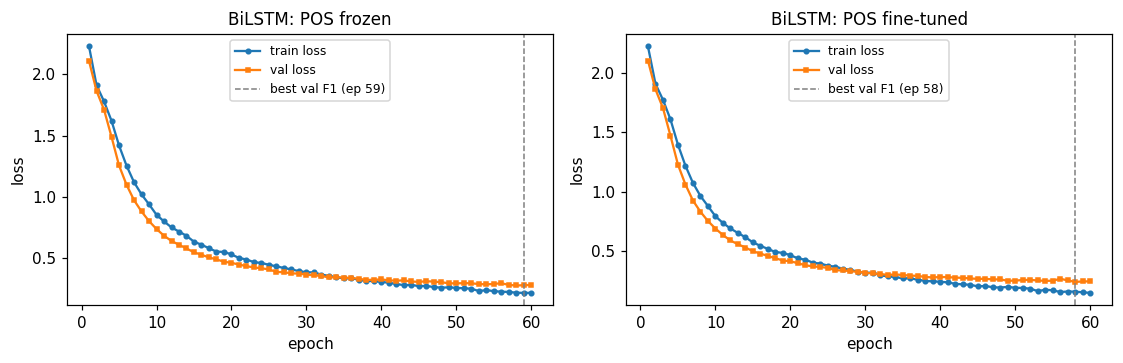

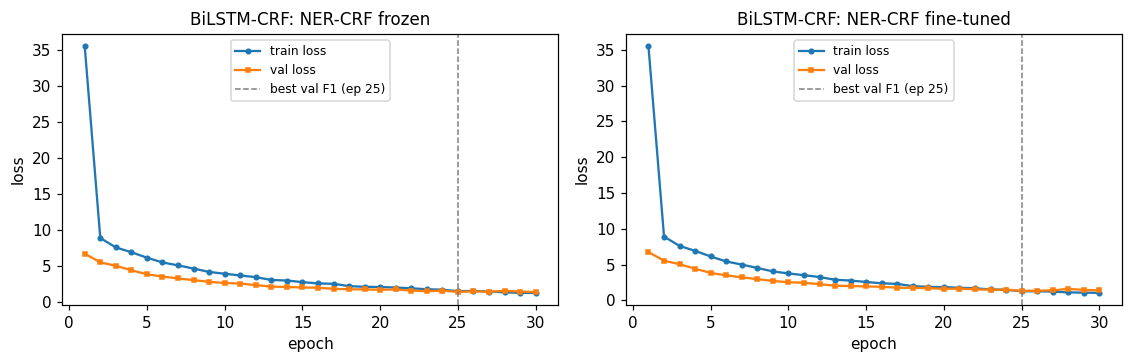

,POS val macro-F1,NER val F1 (conlleval)
frozen,91.40,76.92
fine-tuned,93.58,78.12


Saved models/bilstm_pos.pt (fine-tuned) and models/bilstm_ner.pt (fine-tuned)


In [27]:
# ---- frozen vs fine-tuned embeddings ----
pos_frozen, h_pos_fz, f_pos_fz = train_tagger("pos", freeze=True, tag="POS frozen")
pos_ft, h_pos_ft, f_pos_ft = train_tagger("pos", freeze=False, tag="POS fine-tuned")
ner_frozen, h_ner_fz, f_ner_fz = train_tagger("ner", freeze=True, tag="NER-CRF frozen")
ner_ft, h_ner_ft, f_ner_ft = train_tagger("ner", freeze=False, tag="NER-CRF fine-tuned")
plot_curves({"POS frozen": h_pos_fz, "POS fine-tuned": h_pos_ft}, "BiLSTM", "p2_curves_pos.png")
plot_curves({"NER-CRF frozen": h_ner_fz, "NER-CRF fine-tuned": h_ner_ft}, "BiLSTM-CRF", "p2_curves_ner.png")
MODE_DF = pd.DataFrame({"POS val macro-F1": [f_pos_fz, f_pos_ft], "NER val F1 (conlleval)": [f_ner_fz, f_ner_ft]},
                       index=["frozen", "fine-tuned"]).round(2)
display(MODE_DF)
POS_BEST, POS_MODE = (pos_ft, "fine-tuned") if f_pos_ft >= f_pos_fz else (pos_frozen, "frozen")
NER_BEST, NER_MODE = (ner_ft, "fine-tuned") if f_ner_ft >= f_ner_fz else (ner_frozen, "frozen")
torch.save({"state_dict": POS_BEST.state_dict(), "tags": POS_TAGS, "mode": POS_MODE}, os.path.join(MODEL_DIR, "bilstm_pos.pt"))
torch.save({"state_dict": NER_BEST.state_dict(), "tags": NER_TAGS, "mode": NER_MODE}, os.path.join(MODEL_DIR, "bilstm_ner.pt"))
print(f"Saved models/bilstm_pos.pt ({POS_MODE}) and models/bilstm_ner.pt ({NER_MODE})")

## 5. Evaluation
### 5.1 POS tagging

POS test (fine-tuned): token accuracy = 94.41% | macro-F1 = 94.07


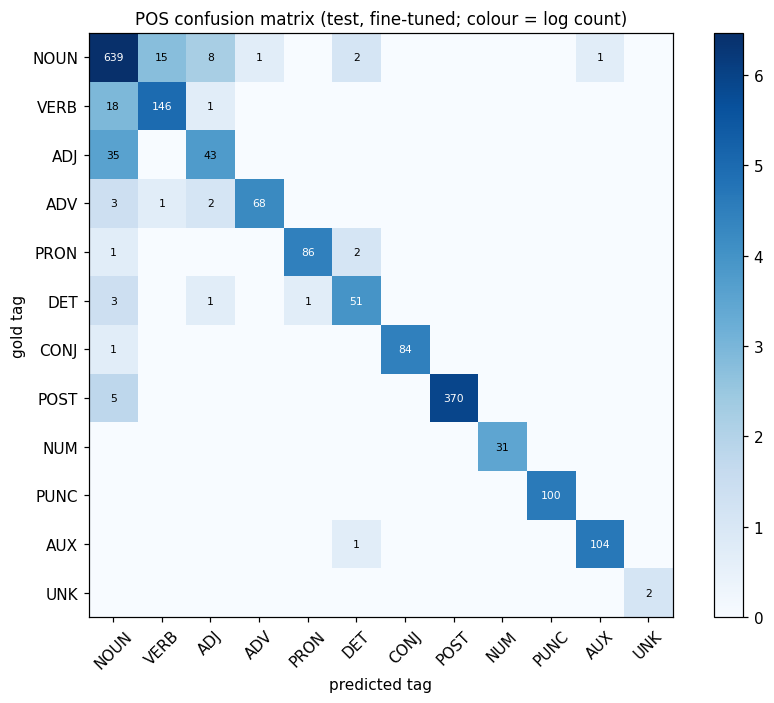

3 most confused tag pairs: [('NOUN↔ADJ', 43), ('NOUN↔VERB', 33), ('NOUN↔DET', 5)]

=== NOUN ↔ ADJ (43 confusions) ===
  • اس کے باوجود کلاڈی جیس ہلاکت ہوت رہت ہیں جو [وفاق/ADJ→NOUN] حکومت کے اقدام کی افادیت پر سوال اٹھات ہیں ۔
  • ایک بار پھر وہی کہان ، وہی [غلط/ADJ→NOUN] اور وہی [مایوس/ADJ→NOUN] کن نتیجہ ۔

=== NOUN ↔ VERB (33 confusions) ===
  • اس بات سے کسی کو فرق نہیں [پڑت/NOUN→VERB] کہ وہ اپن ذات زندگ میں کیا کرن ہے ، کس سے [ملت/VERB→NOUN] ہے یا کس طرح کا کام کرن ہے ۔
  • ایک بار پھر وہی [کہان/NOUN→VERB] ، وہی غلط اور وہی مایوس کن نتیجہ ۔

=== NOUN ↔ DET (5 confusions) ===
  • ایک بار پھر [وہی/DET→NOUN] کہان ، وہی غلط اور [وہی/DET→NOUN] مایوس کن نتیجہ ۔
  • یہ پیش قدم حوث کی جانب سے سعود عرب کے خلاف بحر ناکہ بند کے اعل کے صرف [چند/DET→NOUN] ہفت بعد ہوی ۔

Typical causes: Urdu adjectives used nominally (ADJ↔NOUN), light-verb constructions where the noun/verb boundary is fuzzy (NOUN↔VERB), and words such as ہو/رہا that are AUX or VERB depending on context.


,val macro-F1,test accuracy,test macro-F1
frozen,91.40,93.43,92.87
fine-tuned,93.58,94.41,94.07


In [28]:
Xte_p, Yte_p = encode(S_TEST, "pos", POS2I)
def pos_test_metrics(model):
    _, _, pr = evaluate(model, Xte_p, Yte_p, "pos")
    g = [POS_TAGS[t] for s in Yte_p for t in s]; p = [POS_TAGS[t] for s in pr for t in s]
    return accuracy_score(g, p) * 100, f1_score(g, p, average="macro", labels=sorted(set(g)), zero_division=0) * 100, g, p, pr
acc_ft, mf1_ft, g_ft, p_ft, pr_ft = pos_test_metrics(pos_ft)
acc_fz, mf1_fz, g_fz, p_fz, pr_fz = pos_test_metrics(pos_frozen)
acc_b, mf1_b, G_POS, P_POS, PR_POS = pos_test_metrics(POS_BEST)
print(f"POS test ({POS_MODE}): token accuracy = {acc_b:.2f}% | macro-F1 = {mf1_b:.2f}")

cm = confusion_matrix(G_POS, P_POS, labels=POS_TAGS)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.log1p(cm), cmap="Blues")
ax.set_xticks(range(12)); ax.set_xticklabels(POS_TAGS, rotation=45); ax.set_yticks(range(12)); ax.set_yticklabels(POS_TAGS)
for i in range(12):
    for j in range(12):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if np.log1p(cm[i, j]) > np.log1p(cm.max()) * .6 else "black")
ax.set_xlabel("predicted tag"); ax.set_ylabel("gold tag"); ax.set_title(f"POS confusion matrix (test, {POS_MODE}; colour = log count)")
plt.colorbar(im, ax=ax, fraction=.046); plt.tight_layout(); savefig("p2_pos_confusion.png"); plt.show()

off = [((POS_TAGS[i], POS_TAGS[j]), cm[i, j] + cm[j, i]) for i in range(12) for j in range(i + 1, 12) if cm[i, j] + cm[j, i] > 0]
off = sorted(off, key=lambda x: -x[1])[:3]
off = [(ab, int(n)) for ab, n in off]
print("3 most confused tag pairs:", [(f"{a}↔{b}", n) for (a, b), n in off])
all_sents = [(S_TEST, PR_POS)]
_, _, pr_val = evaluate(POS_BEST, *encode(S_VAL, "pos", POS2I), "pos"); all_sents.append((S_VAL, pr_val))
CONF_EX = {}
for (a, b), n in off:
    ex = []
    for ss, prs in all_sents:
        for s, p in zip(ss, prs):
            hits = [i for i, (gt, pt) in enumerate(zip(s["pos"], p)) if {gt, POS_TAGS[pt]} == {a, b}]
            if hits:
                marked = " ".join(f"[{w}/{s['pos'][i]}→{POS_TAGS[p[i]]}]" if i in hits else w for i, w in enumerate(s["tokens"]))
                ex.append(marked)
            if len(ex) >= 2: break
        if len(ex) >= 2: break
    CONF_EX[f"{a}↔{b}"] = ex
    print(f"\n=== {a} ↔ {b} ({n} confusions) ===")
    for e_ in ex: print("  •", e_)
print("\nTypical causes: Urdu adjectives used nominally (ADJ↔NOUN), light-verb constructions where the noun/verb "
      "boundary is fuzzy (NOUN↔VERB), and words such as ہو/رہا that are AUX or VERB depending on context.")
POS_MODE_DF = pd.DataFrame({"val macro-F1": [f_pos_fz, f_pos_ft], "test accuracy": [acc_fz, acc_ft], "test macro-F1": [mf1_fz, mf1_ft]},
                           index=["frozen", "fine-tuned"]).round(2)
display(POS_MODE_DF)
RESULTS["p2_pos"] = {"mode": POS_MODE, "acc": acc_b, "macro_f1": mf1_b, "confused": [f"{a}<->{b} ({n})" for (a, b), n in off],
                     "frozen": POS_MODE_DF.loc["frozen"].to_dict(), "finetuned": POS_MODE_DF.loc["fine-tuned"].to_dict()}

### 5.2 NER — conlleval, CRF vs. softmax, error analysis

In [29]:
Xte_n, Yte_n = encode(S_TEST, "ner", NER2I)
def ner_test(model):
    _, _, pr = evaluate(model, Xte_n, Yte_n, "ner")
    gold = [[NER_TAGS[t] for t in s] for s in Yte_n]; pred = [[NER_TAGS[t] for t in s] for s in pr]
    return conlleval(gold, pred), gold, pred
ner_soft, h_ner_soft, f_ner_soft = train_tagger("ner", freeze=(NER_MODE == "frozen"), use_crf=False, tag="NER softmax (no CRF)")
RES_CRF, G_NER, P_NER = ner_test(NER_BEST)
RES_SOFT, _, P_NER_SOFT = ner_test(ner_soft)
print("conlleval — BiLSTM-CRF (test):"); print(conlleval_report(RES_CRF))
print("\nconlleval — BiLSTM + softmax (test):"); print(conlleval_report(RES_SOFT))
with open(os.path.join(DATA_OUT, "ner_test_predictions.conll"), "w", encoding="utf-8") as f:   # conlleval.pl-compatible file
    for s, g, p in zip(S_TEST, G_NER, P_NER):
        for w, a, b in zip(s["tokens"], g, p): f.write(f"{w} {a} {b}\n")
        f.write("\n")
rows = []
for t in ["PER", "LOC", "ORG", "MISC", "overall"]:
    for name, R in [("CRF", RES_CRF), ("softmax", RES_SOFT)]:
        r_ = R.get(t, {"precision": 0, "recall": 0, "f1": 0, "support": 0})
        rows.append({"type": t, "decoder": name, "P": r_["precision"], "R": r_["recall"], "F1": r_["f1"], "support": r_["support"]})
NER_TABLE = pd.DataFrame(rows).pivot(index="type", columns="decoder", values=["P", "R", "F1"]).round(2).reindex(["PER", "LOC", "ORG", "MISC", "overall"])
display(NER_TABLE)

[NER softmax (no CRF)] stopped after 33 epochs | best val F1 = 69.49 (epoch 28)
conlleval — BiLSTM-CRF (test):
accuracy:  97.75%; precision:  79.69%; recall:  68.00%; FB1:  73.38
              PER: precision:  75.00%; recall:  66.67%; FB1:  70.59  9
              LOC: precision:  86.84%; recall:  76.74%; FB1:  81.48  43
              ORG: precision:  64.29%; recall:  69.23%; FB1:  66.67  13
             MISC: precision:  75.00%; recall:  30.00%; FB1:  42.86  10

conlleval — BiLSTM + softmax (test):
accuracy:  96.88%; precision:  79.25%; recall:  56.00%; FB1:  65.62
              PER: precision: 100.00%; recall:  33.33%; FB1:  50.00  9
              LOC: precision:  76.92%; recall:  69.77%; FB1:  73.17  43
              ORG: precision:  81.82%; recall:  69.23%; FB1:  75.00  13
             MISC: precision:   0.00%; recall:   0.00%; FB1:   0.00  10


P              R             F1        
decoder    CRF softmax    CRF softmax    CRF softmax
type                                                
PER      75.00  100.00  66.67   33.33  70.59   50.00
LOC      86.84   76.92  76.74   69.77  81.48   73.17
ORG      64.29   81.82  69.23   69.23  66.67   75.00
MISC     75.00    0.00  30.00    0.00  42.86    0.00
overall  79.69   79.25  68.00   56.00  73.38   65.62

In [30]:
# ---- error analysis: 5 false positives and 5 false negatives ----
train_ent_counts = collections.Counter()
for s in S_TRAIN:
    for (a, b, t) in chunks(s["ner"]): train_ent_counts[(tuple(s["tokens"][a:b + 1]), t)] += 1
def explain_fp(s, span, gold_chunks):
    a, b, t = span; words = s["tokens"][a:b + 1]
    for (ga, gb, gt) in gold_chunks:
        if ga <= b and a <= gb:
            if gt != t: return f"type confusion – gold is {gt}; the context (neighbouring words) is typical for {t}"
            return f"boundary error – gold span is '{' '.join(s['tokens'][ga:gb+1])}'"
    if any(W2I.get(w, UNK) == UNK for w in words): return "OOV token (<UNK> embedding) predicted as entity from context only"
    return ("model generalised from context (e.g. a title/verb pattern) to a word absent from the gazetteer – may be a real "
            "entity missed by the silver gazetteer annotation")
def explain_fn(s, span, pred_chunks):
    a, b, t = span; words = tuple(s["tokens"][a:b + 1])
    for (pa, pb, pt) in pred_chunks:
        if pa <= b and a <= pb:
            return f"partially/mis-typed – predicted {pt} span '{' '.join(s['tokens'][pa:pb+1])}'"
    n_tr = train_ent_counts.get((words, t), 0)
    oov = [w for w in words if W2I.get(w, UNK) == UNK]
    if oov: return f"OOV words {oov} have the <UNK> embedding, so the model cannot recognise them"
    if n_tr == 0: return "entity never seen as an entity in training data; its embedding alone is not distinctive enough"
    return f"seen {n_tr}× in training but the local context here is ambiguous (e.g. used as modifier)"
FP, FN = [], []
for s, g, p in zip(S_TEST, G_NER, P_NER):
    gc, pc = set(chunks(g)), set(chunks(p))
    for sp_ in sorted(pc - gc): FP.append((s, sp_, gc))
    for sp_ in sorted(gc - pc): FN.append((s, sp_, pc))
def ctx(s, a, b, w=4): return " ".join(s["tokens"][max(0, a - w):a]) + " [[" + " ".join(s["tokens"][a:b + 1]) + "]] " + " ".join(s["tokens"][b + 1:b + 1 + w])
ERR_ROWS = []
print(f"Test set: {len(FP)} false positives, {len(FN)} false negatives (CRF model)\n")
print("— 5 FALSE POSITIVES —")
for s, (a, b, t), gc in FP[:5]:
    e_ = explain_fp(s, (a, b, t), gc); ERR_ROWS.append(("FP", t, ctx(s, a, b), e_)); print(f"  pred {t:4s}: {ctx(s, a, b)}\n     → {e_}")
print("— 5 FALSE NEGATIVES —")
for s, (a, b, t), pc in FN[:5]:
    e_ = explain_fn(s, (a, b, t), pc); ERR_ROWS.append(("FN", t, ctx(s, a, b), e_)); print(f"  gold {t:4s}: {ctx(s, a, b)}\n     → {e_}")
def _etype(e_):
    for k in ["type confusion", "boundary", "partially", "OOV", "never seen", "gazetteer", "seen"]:
        if k in e_: return {"partially": "boundary/partial", "boundary": "boundary/partial", "gazetteer": "context generalisation (not in gazetteer)",
                            "seen": "ambiguous context"}.get(k, k)
    return "other"
ERR_TYPES = collections.Counter([_etype(explain_fp(s, sp_, gc)) for s, sp_, gc in FP] + [_etype(explain_fn(s, sp_, pc)) for s, sp_, pc in FN])
print("\nError categories over all test FP+FN:", dict(ERR_TYPES))
RESULTS["p2_ner"] = {"mode": NER_MODE, "err_types": dict(ERR_TYPES.most_common()), "crf": {k: {m: round(v, 2) for m, v in RES_CRF[k].items()} for k in RES_CRF},
                     "softmax": {k: {m: round(v, 2) for m, v in RES_SOFT[k].items()} for k in RES_SOFT},
                     "n_fp": len(FP), "n_fn": len(FN), "errors": [r_[0] + ": " + r_[3] for r_ in ERR_ROWS]}

Test set: 13 false positives, 24 false negatives (CRF model)

— 5 FALSE POSITIVES —
  pred PER : اور دون کوچز سرفراز [[احمد]] اور عمر گل کو
     → boundary error – gold span is 'سرفراز احمد'
  pred LOC : زیر انتظام کشمیر کے [[دارالحکومت]] سرینگر کے رہایش اور
     → model generalised from context (e.g. a title/verb pattern) to a word absent from the gazetteer – may be a real entity missed by the silver gazetteer annotation
  pred PER : کرن وال دوسر کھلاڑ [[محمد]] عمر کی وکٹ <NUM>
     → model generalised from context (e.g. a title/verb pattern) to a word absent from the gazetteer – may be a real entity missed by the silver gazetteer annotation
  pred LOC :  [[اسلام]] رجح رکھن وال ایک
     → type confusion – gold is MISC; the context (neighbouring words) is typical for LOC
  pred ORG : ہے کہ شاید وہ [[ایمن]] الظواہر کے بعد القاعدہ
     → model generalised from context (e.g. a title/verb pattern) to a word absent from the gazetteer – may be a real entity missed by the silver gazetteer ann

### 5.3 Ablation study (same data split, one change at a time; baseline = fine-tuned BiLSTM(-CRF))

In [31]:
ABL = {}
base_pos_test = pos_test_metrics(pos_ft)[1]; base_ner_test = ner_test(ner_ft)[0]["overall"]["f1"]
ABL["Baseline (BiLSTM, dropout, W2V init, CRF for NER)"] = (f_pos_ft, base_pos_test, f_ner_ft, base_ner_test)
for name, kw in [("A1 Unidirectional LSTM", dict(bidirectional=False)), ("A2 No dropout", dict(dropout=0.0)),
                 ("A3 Random embedding init", dict(random_init=True))]:
    mp, _, fp_ = train_tagger("pos", **kw, tag=f"{name} POS"); mn, _, fn_ = train_tagger("ner", **kw, tag=f"{name} NER")
    ABL[name] = (fp_, pos_test_metrics(mp)[1], fn_, ner_test(mn)[0]["overall"]["f1"])
_soft_ft = ner_soft if NER_MODE == "fine-tuned" else train_tagger("ner", use_crf=False, tag="A4 softmax")[0]
ABL["A4 Softmax instead of CRF (NER)"] = (np.nan, np.nan, evaluate(_soft_ft, *encode(S_VAL, "ner", NER2I), "ner")[0], ner_test(_soft_ft)[0]["overall"]["f1"])
ABL_DF = pd.DataFrame(ABL, index=["POS val macro-F1", "POS test macro-F1", "NER val F1", "NER test F1"]).T.round(2)
display(ABL_DF)

def _d(row, col): return ABL_DF.loc[row, col] - ABL_DF.iloc[0][col]
abl_text = []
for row, what in [("A1 Unidirectional LSTM", "backward context"), ("A2 No dropout", "dropout regularisation"),
                  ("A3 Random embedding init", "pre-trained Word2Vec initialisation")]:
    dp, dn = _d(row, "POS test macro-F1"), _d(row, "NER test F1")
    abl_text.append(f"{row}: POS macro-F1 {dp:+.2f}, NER F1 {dn:+.2f} vs. baseline – "
                    + (f"removing {what} hurts, so it contributes to the baseline." if dp + dn < -1.0 else
                       f"removing {what} changes little on this small, rule-annotated data set (differences within run-to-run noise)." if abs(dp + dn) <= 1.0 else
                       f"removing {what} actually helps here (+{dp + dn:.1f} combined); with only ~350 silver-labelled training sentences "
                       f"the model benefits from {'a less constrained input space' if 'embedding' in what else 'more capacity / less regularisation'}."))
dn = _d("A4 Softmax instead of CRF (NER)", "NER test F1")
abl_text.append(f"A4 Softmax instead of CRF: NER F1 {dn:+.2f} – " + ("structured CRF decoding helps by forbidding invalid BIO transitions (e.g. O→I-PER) and keeping multi-word entities together."
                if dn < -1.0 else "CRF and softmax perform about the same here; the BiLSTM already sees both directions, so few invalid BIO sequences remain to be fixed."
                if dn <= 1.0 else "the softmax decoder is better on this run; with little training data the CRF transition matrix is estimated from few multi-token entities."))
for t_ in abl_text: print("•", t_)
RESULTS["p2_ablation"] = {k: [None if (isinstance(v, float) and np.isnan(v)) else float(v) for v in vals] for k, vals in ABL_DF.iterrows()}
RESULTS["p2_ablation_text"] = abl_text
RESULTS["p2_modes"] = MODE_DF.to_dict()

[A1 Unidirectional LSTM POS] stopped after 60 epochs | best val F1 = 86.18 (epoch 59)
[A1 Unidirectional LSTM NER] stopped after 33 epochs | best val F1 = 64.12 (epoch 28)
[A2 No dropout POS] stopped after 39 epochs | best val F1 = 93.38 (epoch 34)
[A2 No dropout NER] stopped after 23 epochs | best val F1 = 80.95 (epoch 18)
[A3 Random embedding init POS] stopped after 60 epochs | best val F1 = 93.01 (epoch 55)
[A3 Random embedding init NER] stopped after 33 epochs | best val F1 = 83.20 (epoch 28)


,POS val macro-F1,POS test macro-F1,NER val F1,NER test F1
"Baseline (BiLSTM, dropout, W2V init, CRF for NER)",93.58,94.07,78.12,73.38
A1 Unidirectional LSTM,86.18,78.74,64.12,62.77
A2 No dropout,93.38,92.93,80.95,79.70
A3 Random embedding init,93.01,94.39,83.20,80.00
A4 Softmax instead of CRF (NER),NaN,NaN,69.49,65.62


• A1 Unidirectional LSTM: POS macro-F1 -15.33, NER F1 -10.61 vs. baseline – removing backward context hurts, so it contributes to the baseline.
• A2 No dropout: POS macro-F1 -1.14, NER F1 +6.32 vs. baseline – removing dropout regularisation actually helps here (+5.2 combined); with only ~350 silver-labelled training sentences the model benefits from more capacity / less regularisation.
• A3 Random embedding init: POS macro-F1 +0.32, NER F1 +6.62 vs. baseline – removing pre-trained Word2Vec initialisation actually helps here (+6.9 combined); with only ~350 silver-labelled training sentences the model benefits from more capacity / less regularisation.
• A4 Softmax instead of CRF: NER F1 -7.76 – structured CRF decoding helps by forbidding invalid BIO transitions (e.g. O→I-PER) and keeping multi-word entities together.


# Part 3 — Transformer Encoder for Topic Classification (20 marks)
## 6. Dataset preparation
Categories come from the keyword assignment done in Part 1 (Politics, Sports, Economy, International, Health & Society).
Each article becomes a sequence of token IDs (same `word2idx` as Part 1), truncated / padded to 256 tokens.

In [32]:
CLS_X = np.zeros((len(ARTICLES), MAX_LEN), dtype=np.int64)
for i, ids in enumerate(DOC_IDS):
    ids = ids[:MAX_LEN]; CLS_X[i, :len(ids)] = ids
CLS_Y = np.array(DOC_CAT, dtype=np.int64)
idx_tr, idx_va, idx_te = strat_split(list(range(len(ARTICLES))), list(CLS_Y), seed=42)
CLS_DIST = pd.DataFrame({name: pd.Series(CLS_Y[ix]).map(dict(enumerate(CATEGORIES))).value_counts().reindex(CATEGORIES).fillna(0).astype(int)
                         for name, ix in [("train", idx_tr), ("val", idx_va), ("test", idx_te)]})
CLS_DIST["total"] = CLS_DIST.sum(1)
print(f"Articles: {len(ARTICLES)} | train/val/test = {len(idx_tr)}/{len(idx_va)}/{len(idx_te)} | "
      f"truncated: {(np.array([len(x) for x in DOC_IDS]) > MAX_LEN).mean():.0%} of articles longer than {MAX_LEN} tokens")
display(CLS_DIST)
RESULTS["p3_data"] = {"split": [len(idx_tr), len(idx_va), len(idx_te)], "dist": CLS_DIST["total"].to_dict()}

def cls_batches(idx, bs=16, shuffle=False, seed=0):
    idx = list(idx)
    if shuffle: random.Random(seed).shuffle(idx)
    for b in range(0, len(idx), bs):
        j = idx[b:b + bs]
        yield torch.tensor(CLS_X[j]).to(DEVICE), torch.tensor(CLS_Y[j]).to(DEVICE), j

Articles: 223 | train/val/test = 156/33/34 | truncated: 40% of articles longer than 256 tokens


,train,val,test,total
Politics,20,5,4,29
Sports,26,5,6,37
Economy,15,4,3,22
International,54,11,12,77
Health & Society,41,8,9,58


## 7. Transformer encoder — every component is its own module (no PyTorch built-in Transformer classes)

In [33]:
class ScaledDotProductAttention(nn.Module):
    """Attention(Q,K,V) = softmax(QKᵀ/√d_k) V, with optional key-padding mask. Returns (output, weights)."""
    def __init__(self, dropout=0.1):
        super().__init__(); self.drop = nn.Dropout(dropout)
    def forward(self, Q, K, V, mask=None):            # Q,K,V: B x L x d_k ; mask: B x L (True = real token)
        scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.size(-1))
        if mask is not None:
            scores = scores.masked_fill(~mask[:, None, :], float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        return self.drop(weights) @ V, weights

class MultiHeadSelfAttention(nn.Module):
    """h independent heads, each with its own W_Q, W_K, W_V (d_model -> d_k); shared output projection W_O."""
    def __init__(self, d_model=128, h=4, d_k=32, d_v=32, dropout=0.1):
        super().__init__()
        self.W_Q = nn.ModuleList([nn.Linear(d_model, d_k) for _ in range(h)])
        self.W_K = nn.ModuleList([nn.Linear(d_model, d_k) for _ in range(h)])
        self.W_V = nn.ModuleList([nn.Linear(d_model, d_v) for _ in range(h)])
        self.attention = ScaledDotProductAttention(dropout)
        self.W_O = nn.Linear(h * d_v, d_model)
    def forward(self, x, mask=None):
        outs, ws = [], []
        for q, k, v in zip(self.W_Q, self.W_K, self.W_V):
            o, w = self.attention(q(x), k(x), v(x), mask); outs.append(o); ws.append(w)
        return self.W_O(torch.cat(outs, dim=-1)), torch.stack(ws, dim=1)     # B x L x d_model, B x h x L x L

class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model=128, d_ff=512, dropout=0.1):
        super().__init__()
        self.lin1, self.lin2, self.drop = nn.Linear(d_model, d_ff), nn.Linear(d_ff, d_model), nn.Dropout(dropout)
    def forward(self, x):
        return self.lin2(self.drop(F.relu(self.lin1(x))))

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model=128, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.pow(10000.0, torch.arange(0, d_model, 2).float() / d_model)
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos / div); pe[:, 1::2] = torch.cos(pos / div)
        self.register_buffer("pe", pe.unsqueeze(0))       # fixed buffer – not a parameter, never trained
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class EncoderBlock(nn.Module):
    """Pre-LN:  x ← x + Dropout(MHA(LN(x)));  x ← x + Dropout(FFN(LN(x)))"""
    def __init__(self, d_model=128, h=4, d_ff=512, dropout=0.1):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.mha = MultiHeadSelfAttention(d_model, h, d_model // h, d_model // h, dropout)
        self.ffn = PositionwiseFeedForward(d_model, d_ff, dropout)
        self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout)
    def forward(self, x, mask=None):
        a, w = self.mha(self.ln1(x), mask)
        x = x + self.drop1(a)
        x = x + self.drop2(self.ffn(self.ln2(x)))
        return x, w

class TransformerClassifier(nn.Module):
    def __init__(self, vocab, n_classes=5, d_model=128, h=4, d_ff=512, n_layers=4, max_len=MAX_LEN + 1, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab, d_model, padding_idx=PAD)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)    # learned [CLS] token
        self.pos = SinusoidalPositionalEncoding(d_model, max_len)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, h, d_ff, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Sequential(nn.Linear(d_model, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, n_classes))   # 128→64→5
    def forward(self, ids, return_attn=False):
        B = ids.size(0)
        x = self.emb(ids) * math.sqrt(self.d_model)
        x = torch.cat([self.cls.expand(B, -1, -1), x], dim=1)                   # prepend [CLS]
        mask = torch.cat([torch.ones(B, 1, dtype=torch.bool, device=ids.device), ids != PAD], dim=1)
        x = self.drop(self.pos(x))                                              # PE added before the first block
        attns = []
        for blk in self.blocks:
            x, w = blk(x, mask); attns.append(w)
        logits = self.head(self.ln_f(x[:, 0]))
        return (logits, attns) if return_attn else logits

_m = TransformerClassifier(V)
_lo, _at = _m(torch.tensor(CLS_X[:2]), return_attn=True)
print(_m)
print("logits", tuple(_lo.shape), "| attention per layer", tuple(_at[-1].shape), "| params:", f"{sum(p.numel() for p in _m.parameters()):,}",
      "| PE is buffer (not parameter):", "pos.pe" in dict(_m.named_buffers()) and "pos.pe" not in dict(_m.named_parameters()))
del _m, _lo, _at

TransformerClassifier(
  (emb): Embedding(7382, 128, padding_idx=0)
  (pos): SinusoidalPositionalEncoding()
  (drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-3): 4 x EncoderBlock(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (mha): MultiHeadSelfAttention(
        (W_Q): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (W_K): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (W_V): ModuleList(
          (0-3): 4 x Linear(in_features=128, out_features=32, bias=True)
        )
        (attention): ScaledDotProductAttention(
          (drop): Dropout(p=0.1, inplace=False)
        )
        (W_O): Linear(in_features=128, out_features=128, bias=True)
      )
      (ffn): PositionwiseFeedForward(
        (lin1): Linear(in_features=128, out_features=512

AdamW lr=5e-4 wd=0.01 | cosine schedule, 50 warm-up steps, 200 total steps
[Transformer] ep  1/20 train loss 1.560 acc  30.8 | val loss 1.547 acc  33.3 | lr 1.10e-04 | 0.45s
[Transformer] ep  2/20 train loss 1.519 acc  36.5 | val loss 1.560 acc  33.3 | lr 2.10e-04 | 0.32s
[Transformer] ep  3/20 train loss 1.506 acc  34.6 | val loss 1.554 acc  33.3 | lr 3.10e-04 | 0.35s
[Transformer] ep  4/20 train loss 1.520 acc  35.9 | val loss 1.533 acc  33.3 | lr 4.10e-04 | 0.33s
[Transformer] ep  5/20 train loss 1.491 acc  35.3 | val loss 1.563 acc  24.2 | lr 5.00e-04 | 0.34s
[Transformer] ep  6/20 train loss 1.458 acc  40.4 | val loss 1.552 acc  33.3 | lr 4.95e-04 | 0.32s
[Transformer] ep  7/20 train loss 1.410 acc  39.7 | val loss 1.567 acc  27.3 | lr 4.78e-04 | 0.33s
[Transformer] ep  8/20 train loss 1.346 acc  42.9 | val loss 1.497 acc  39.4 | lr 4.52e-04 | 0.34s
[Transformer] ep  9/20 train loss 1.248 acc  51.9 | val loss 1.855 acc  42.4 | lr 4.17e-04 | 0.46s
[Transformer] ep 10/20 train loss 

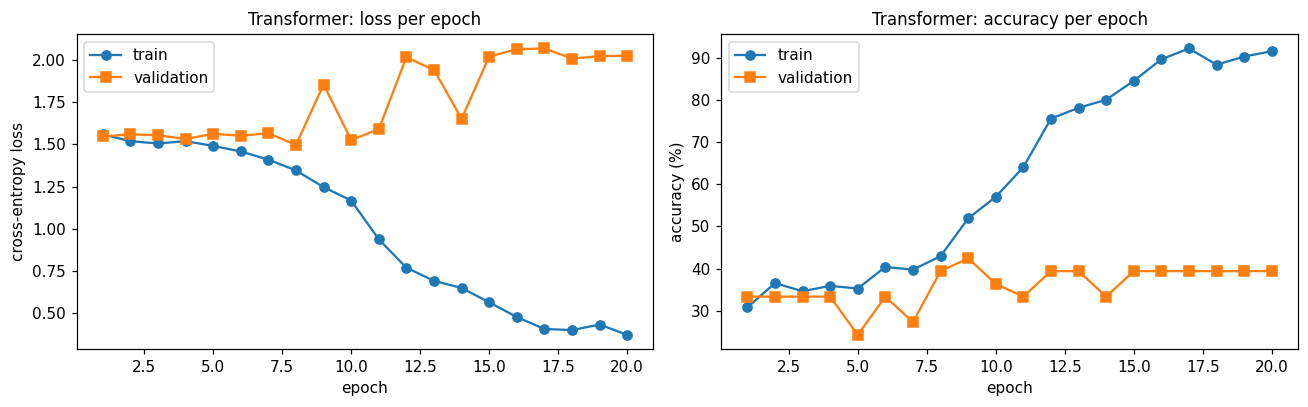

Saved models/transformer_cls.pt (best validation epoch: 9 )


In [34]:
def cosine_warmup(opt, warmup, total):
    def f(step):
        if step < warmup: return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warmup) / max(1, total - warmup))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def run_cls_epoch(model, idx, opt=None, sched=None, seed=0):
    train = opt is not None; model.train(train)
    tl, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y, _ in cls_batches(idx, bs=16, shuffle=train, seed=seed):
            logits = model(x); loss = F.cross_entropy(logits, y)
            if train:
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tl += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return tl / n, 100 * correct / n

def train_classifier(model, opt, sched, epochs, tag, ckpt=None):
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "epoch_time", "lr"]}
    best, best_state = -1, None
    for ep in range(epochs):
        t0 = time.time()
        trl, tra = run_cls_epoch(model, idx_tr, opt, sched, seed=ep)
        hist["epoch_time"].append(time.time() - t0)
        val, vaa = run_cls_epoch(model, idx_va)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [trl, tra, val, vaa]): hist[k].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if vaa > best: best, best_state, hist["best_epoch"] = vaa, {k: v.detach().clone() for k, v in model.state_dict().items()}, ep + 1
        print(f"[{tag}] ep {ep+1:2d}/{epochs} train loss {trl:.3f} acc {tra:5.1f} | val loss {val:.3f} acc {vaa:5.1f} | "
              f"lr {hist['lr'][-1]:.2e} | {hist['epoch_time'][-1]:.2f}s")
    model.load_state_dict(best_state)
    if ckpt: torch.save({"state_dict": best_state, "categories": CATEGORIES, "best_epoch": hist["best_epoch"]}, ckpt)
    return hist

set_seed(42)
TRF = TransformerClassifier(V).to(DEVICE)
opt = torch.optim.AdamW(TRF.parameters(), lr=5e-4, weight_decay=0.01)
total_steps = TR_EPOCHS * math.ceil(len(idx_tr) / 16)
sched = cosine_warmup(opt, warmup=50, total=total_steps)
print(f"AdamW lr=5e-4 wd=0.01 | cosine schedule, 50 warm-up steps, {total_steps} total steps")
H_TRF = train_classifier(TRF, opt, sched, TR_EPOCHS, "Transformer", os.path.join(MODEL_DIR, "transformer_cls.pt"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); e = range(1, TR_EPOCHS + 1)
ax[0].plot(e, H_TRF["train_loss"], marker="o", label="train"); ax[0].plot(e, H_TRF["val_loss"], marker="s", label="validation")
ax[0].set_title("Transformer: loss per epoch"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].legend()
ax[1].plot(e, H_TRF["train_acc"], marker="o", label="train"); ax[1].plot(e, H_TRF["val_acc"], marker="s", label="validation")
ax[1].set_title("Transformer: accuracy per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy (%)"); ax[1].legend()
plt.tight_layout(); savefig("p3_transformer_curves.png"); plt.show()
print("Saved models/transformer_cls.pt (best validation epoch:", H_TRF["best_epoch"], ")")

## 8. Evaluation
### 8.1 Results

Transformer TEST accuracy = 61.76% | macro-F1 = 43.26


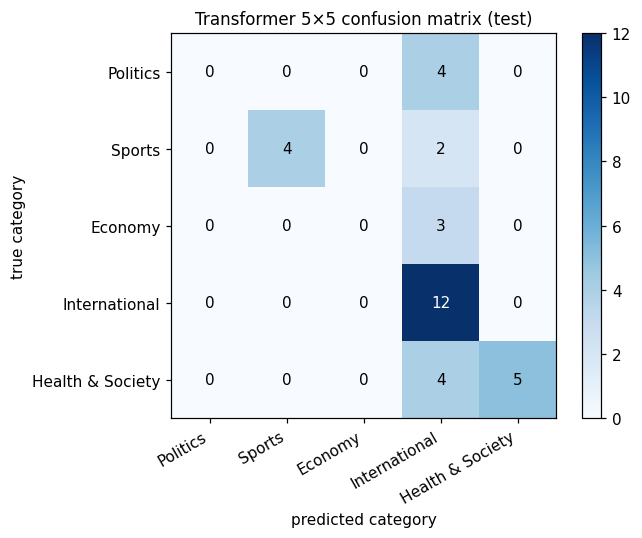

,pred Politics,pred Sports,pred Economy,pred International,pred Health & Society
true Politics,0,0,0,4,0
true Sports,0,4,0,2,0
true Economy,0,0,0,3,0
true International,0,0,0,12,0
true Health & Society,0,0,0,4,5


In [35]:
@torch.no_grad()
def predict_cls(model, idx):
    model.eval(); P = []
    for x, y, _ in cls_batches(idx, bs=32): P += model(x).argmax(1).tolist()
    return np.array(P)
P_TRF = predict_cls(TRF, idx_te); Y_TE = CLS_Y[idx_te]
TRF_ACC = accuracy_score(Y_TE, P_TRF) * 100
TRF_F1 = f1_score(Y_TE, P_TRF, average="macro", labels=list(range(5)), zero_division=0) * 100
print(f"Transformer TEST accuracy = {TRF_ACC:.2f}% | macro-F1 = {TRF_F1:.2f}")
cm5 = confusion_matrix(Y_TE, P_TRF, labels=list(range(5)))
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(cm5, cmap="Blues")
ax.set_xticks(range(5)); ax.set_xticklabels(CATEGORIES, rotation=30, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(CATEGORIES)
for i in range(5):
    for j in range(5): ax.text(j, i, cm5[i, j], ha="center", va="center", color="white" if cm5[i, j] > cm5.max() / 2 else "black")
ax.set_xlabel("predicted category"); ax.set_ylabel("true category"); ax.set_title("Transformer 5×5 confusion matrix (test)")
plt.colorbar(im, ax=ax, fraction=.046); plt.tight_layout(); savefig("p3_confusion.png"); plt.show()
display(pd.DataFrame(cm5, index=[f"true {c_}" for c_ in CATEGORIES], columns=[f"pred {c_}" for c_ in CATEGORIES]))

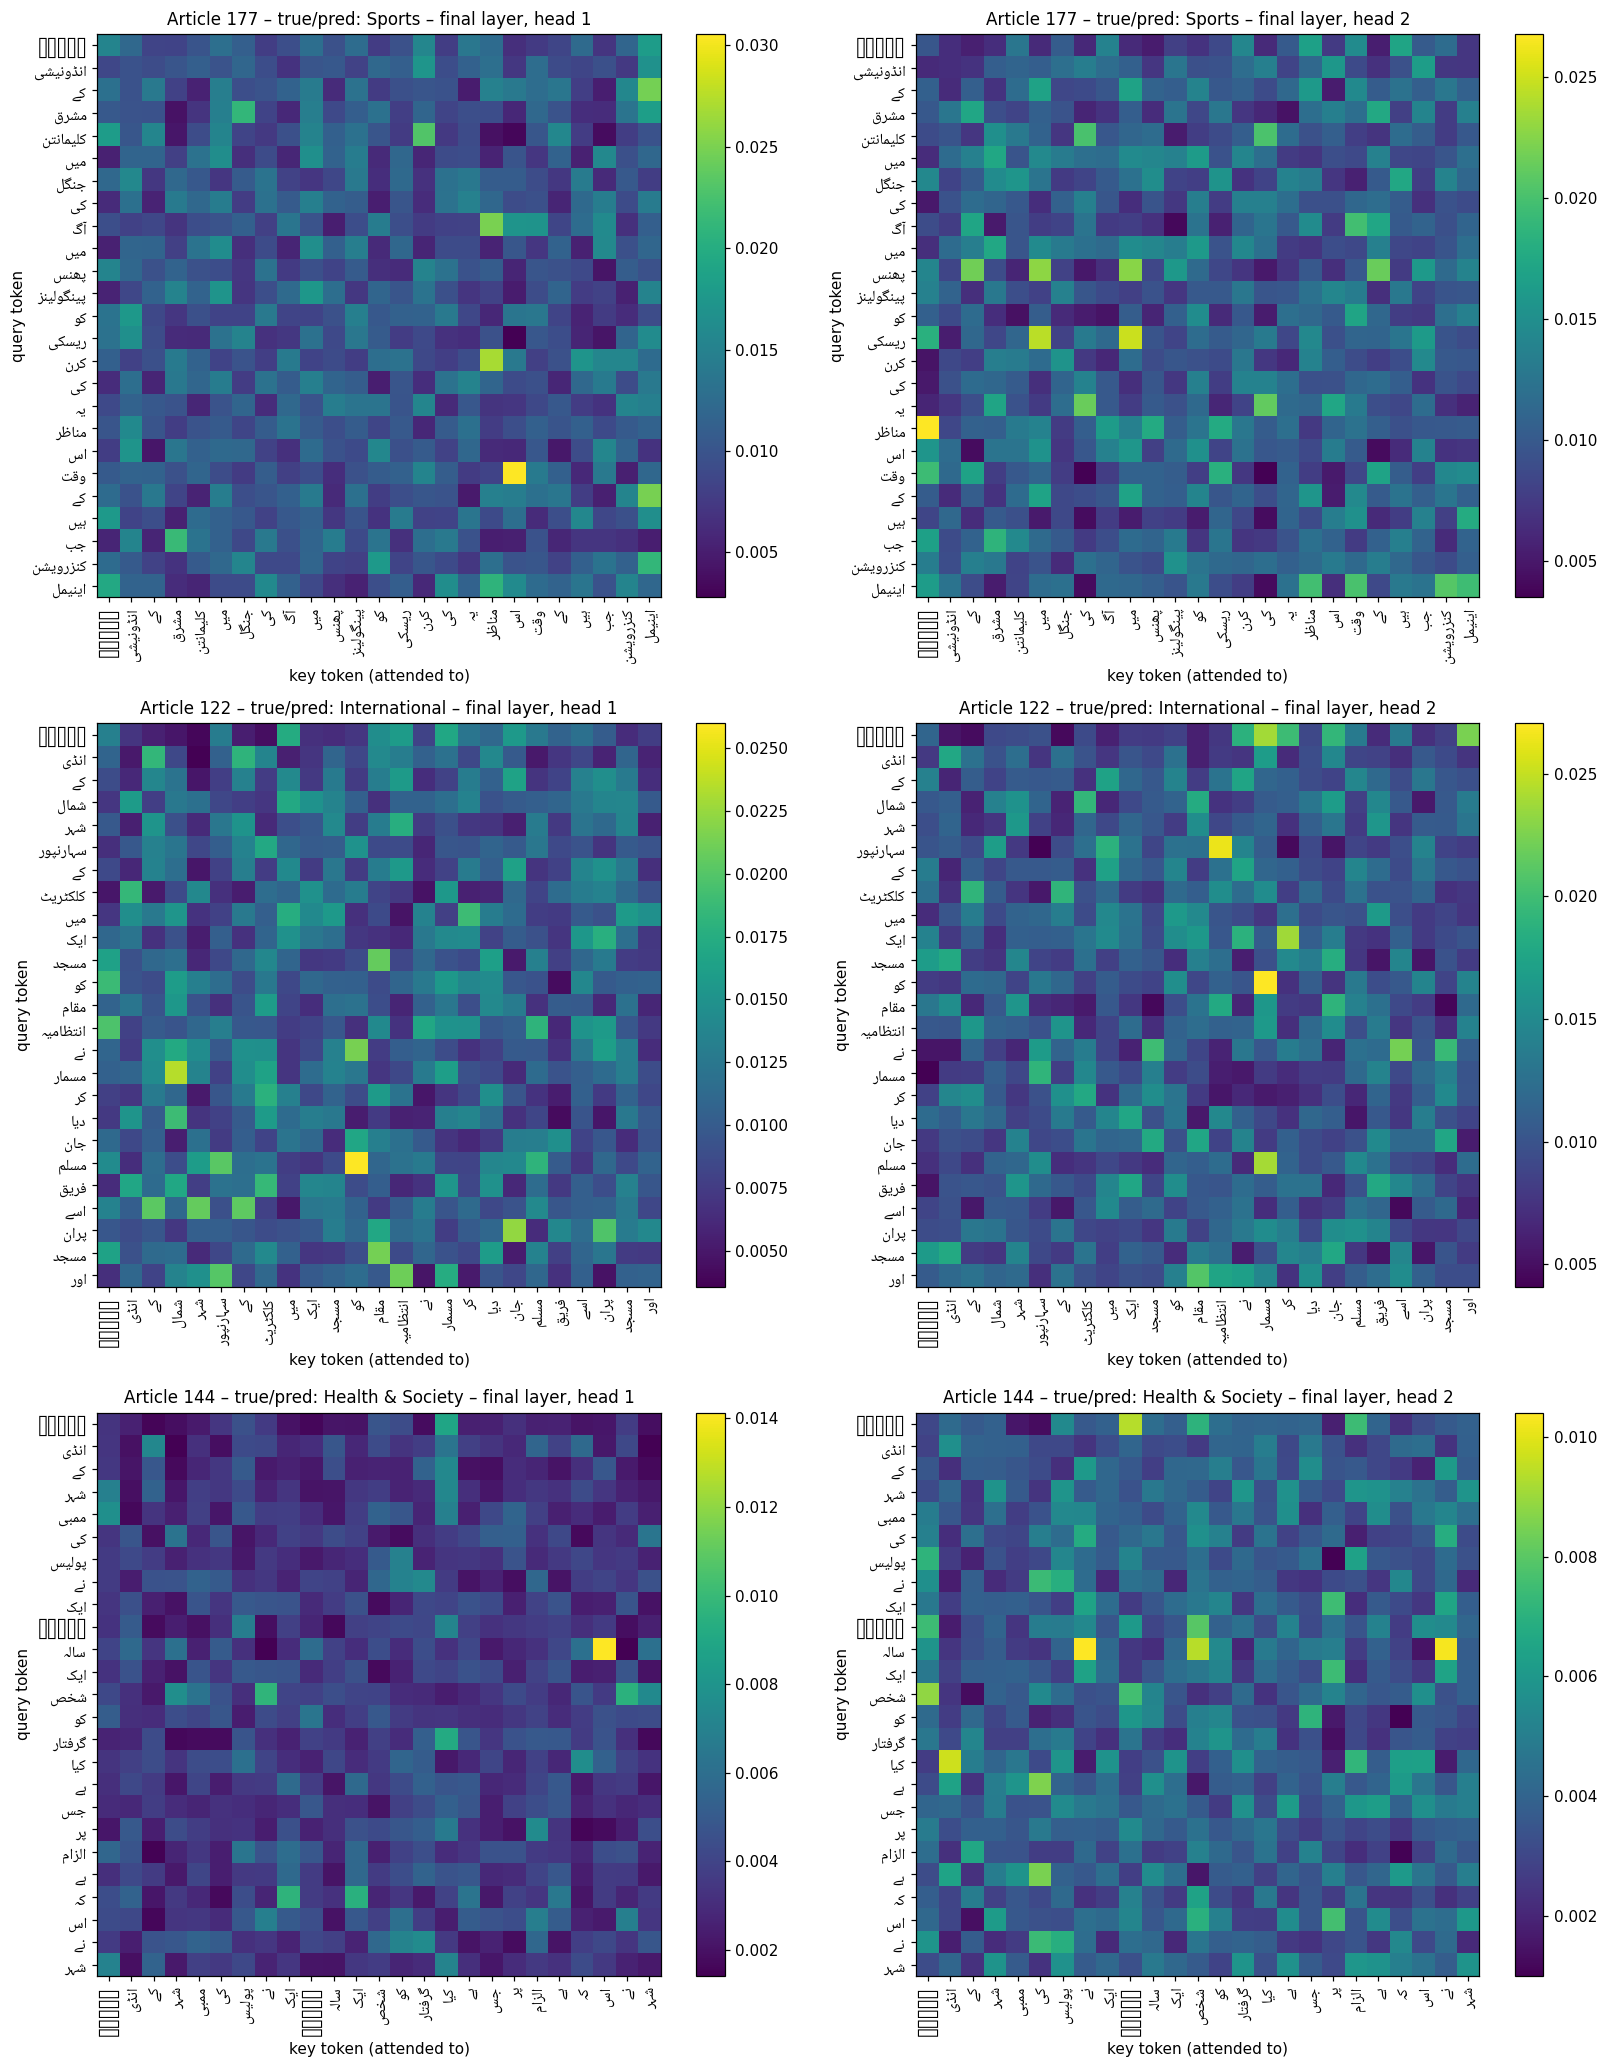

Sports            [CLS] attends most to: وسط، باعث، ورک، کر، ہوی، کارروای، ٹیم، نیٹ | topic keywords among them: ['ٹیم', 'نیٹ']
International     [CLS] attends most to: کیا، مواد، کر، پالیس، مسمار، بیرون، ایڈٹ، دار | topic keywords among them: []
Health & Society  [CLS] attends most to: تقریب، دیکھ، رحم، بچہ، انڈی، پولیس، پھر، سی | topic keywords among them: ['بچہ', 'انڈی']


,mean max weight (sharpness),mean self-attention,mean weight on [CLS]
head 1,0.018,0.009,0.008
head 2,0.018,0.008,0.008
head 3,0.018,0.009,0.009
head 4,0.018,0.009,0.008


In [36]:
# ---- attention heatmaps: final encoder layer, 3 correctly classified test articles, 2 heads each ----
correct_te = [i for i, p in zip(idx_te, P_TRF) if p == CLS_Y[i]]
picked = []
for c_ in range(5):                                  # prefer 3 different categories
    for i in correct_te:
        if CLS_Y[i] == c_ and i not in picked: picked.append(i); break
picked = (picked + [i for i in correct_te if i not in picked])[:3]
SHOW = 24
CLS_FOCUS, HEAD_STATS = [], []
TRF.eval()
fig, axes = plt.subplots(len(picked), 2, figsize=(15, 6.3 * len(picked)), squeeze=False)
for r, i in enumerate(picked):
    with torch.no_grad():
        _, att = TRF(torch.tensor(CLS_X[i:i + 1]).to(DEVICE), return_attn=True)
    A = att[-1][0].cpu().numpy()                     # h x L x L (final layer)
    toks = ["[CLS]"] + [ITOS[t] for t in CLS_X[i] if t != PAD]
    n = min(SHOW + 1, len(toks)); labels = [ur(t) for t in toks[:n]]
    for hcol, head in enumerate([0, 1]):
        ax = axes[r, hcol]; im = ax.imshow(A[head, :n, :n], cmap="viridis")
        ax.set_xticks(range(n)); ax.set_xticklabels(labels, rotation=90, fontsize=8, fontproperties=UR_FP)
        ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=8, fontproperties=UR_FP)
        ax.set_xlabel("key token (attended to)"); ax.set_ylabel("query token")
        ax.set_title(f"Article {ARTICLES[i]['id']} – true/pred: {CATEGORIES[CLS_Y[i]]} – final layer, head {head+1}")
        plt.colorbar(im, ax=ax, fraction=.046)
    L_ = len(toks)
    Ar = A[:, :L_, :L_]
    HEAD_STATS.append({"max_w": Ar.max(-1).mean(-1), "diag": np.stack([np.diag(Ar[h]).mean() for h in range(Ar.shape[0])]),
                       "to_cls": Ar[:, :, 0].mean(-1)})
    cls_att = A[:, 0, 1:L_].mean(0)                # what [CLS] attends to (averaged over heads), whole article
    uniq = []
    for t in np.argsort(-cls_att):                   # top-8 distinct words
        if toks[1 + t] not in uniq: uniq.append(toks[1 + t])
        if len(uniq) == 8: break
    CLS_FOCUS.append((CATEGORIES[CLS_Y[i]], uniq))
plt.tight_layout(); savefig("p3_attention_heatmaps.png"); plt.show()
kw_all = {k for c_ in CAT_KEYWORDS.values() for k in c_["ur"] + c_["urc"]}
for cat_, ws in CLS_FOCUS:
    print(f"{cat_:17s} [CLS] attends most to:", "، ".join(ws), "| topic keywords among them:", [w for w in ws if w in kw_all])
HS = {k: np.mean([h[k] for h in HEAD_STATS], 0) for k in ["max_w", "diag", "to_cls"]}
display(pd.DataFrame(HS, index=[f"head {h+1}" for h in range(len(HS['max_w']))]).rename(
    columns={"max_w": "mean max weight (sharpness)", "diag": "mean self-attention", "to_cls": "mean weight on [CLS]"}).round(3))
RESULTS["p3_trf"] = {"acc": TRF_ACC, "macro_f1": TRF_F1, "best_epoch": H_TRF["best_epoch"],
                     "epoch_time": float(np.mean(H_TRF["epoch_time"])), "cm": cm5.tolist()}

### 8.2 BiLSTM vs. Transformer
For a like-for-like comparison, the Part-2 BiLSTM encoder (2 layers, bidirectional, dropout 0.5, Word2Vec C3 init) is
trained on the **same** topic-classification split, with masked mean-pooling over $h_t$ and an MLP head.

[BiLSTM] ep  1/20 train loss 1.578 acc  34.6 | val loss 1.527 acc  33.3 | lr 1.00e-03 | 0.44s
[BiLSTM] ep  2/20 train loss 1.496 acc  34.6 | val loss 1.533 acc  33.3 | lr 1.00e-03 | 0.37s
[BiLSTM] ep  3/20 train loss 1.473 acc  37.8 | val loss 1.451 acc  42.4 | lr 1.00e-03 | 0.36s
[BiLSTM] ep  4/20 train loss 1.388 acc  40.4 | val loss 1.377 acc  42.4 | lr 1.00e-03 | 0.37s
[BiLSTM] ep  5/20 train loss 1.355 acc  42.9 | val loss 1.354 acc  39.4 | lr 1.00e-03 | 0.43s
[BiLSTM] ep  6/20 train loss 1.226 acc  49.4 | val loss 1.308 acc  48.5 | lr 1.00e-03 | 0.51s
[BiLSTM] ep  7/20 train loss 1.174 acc  50.6 | val loss 1.255 acc  45.5 | lr 1.00e-03 | 0.53s
[BiLSTM] ep  8/20 train loss 1.087 acc  59.0 | val loss 1.375 acc  51.5 | lr 1.00e-03 | 0.51s
[BiLSTM] ep  9/20 train loss 1.054 acc  63.5 | val loss 1.158 acc  57.6 | lr 1.00e-03 | 0.53s
[BiLSTM] ep 10/20 train loss 0.957 acc  65.4 | val loss 1.196 acc  60.6 | lr 1.00e-03 | 0.54s
[BiLSTM] ep 11/20 train loss 0.939 acc  70.5 | val loss 1.25

,test accuracy (%),test macro-F1,best val epoch,epochs to 95% of best val acc,min val-loss epoch,sec / epoch,parameters
BiLSTM,67.65,52.51,13,10,14,0.42,1385757
Transformer,61.76,43.26,9,9,8,0.38,1746949


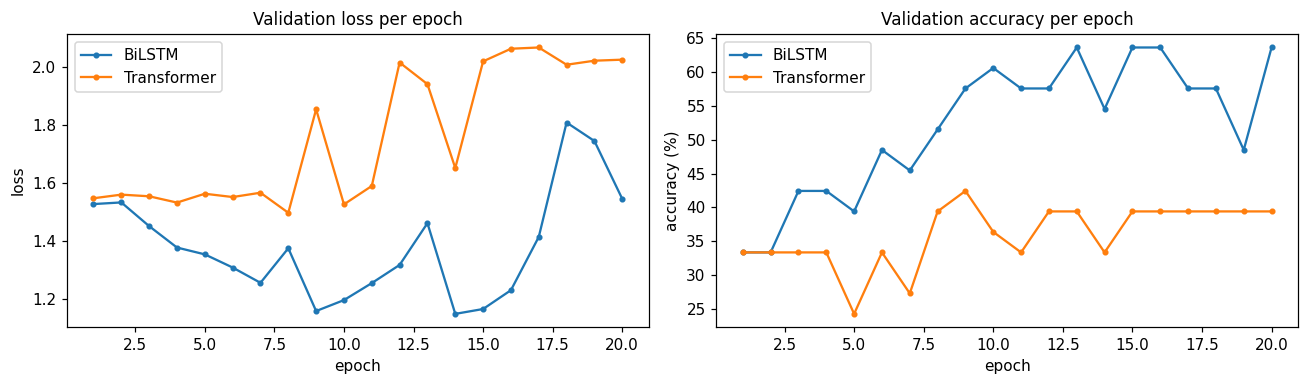

In [37]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, emb_matrix, n_classes=5, hidden=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, num_layers=2, bidirectional=True, batch_first=True, dropout=0.5)
        self.drop = nn.Dropout(0.5)
        self.head = nn.Sequential(nn.Linear(2 * hidden, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, n_classes))
    def forward(self, ids):
        lengths = (ids != PAD).sum(1).clamp(min=1)
        out, _ = self.lstm(pack_padded_sequence(self.drop(self.emb(ids)), lengths.cpu(), batch_first=True, enforce_sorted=False))
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        m = (ids != PAD).unsqueeze(-1).float()
        return self.head(self.drop((out * m).sum(1) / m.sum(1).clamp(min=1)))

set_seed(42)
BIL = BiLSTMClassifier(EMB_INIT).to(DEVICE)
opt_b = torch.optim.Adam(BIL.parameters(), lr=1e-3, weight_decay=1e-4)
sched_b = torch.optim.lr_scheduler.LambdaLR(opt_b, lambda s: 1.0)
H_BIL = train_classifier(BIL, opt_b, sched_b, TR_EPOCHS, "BiLSTM")
P_BIL = predict_cls(BIL, idx_te)
BIL_ACC = accuracy_score(Y_TE, P_BIL) * 100
BIL_F1 = f1_score(Y_TE, P_BIL, average="macro", labels=list(range(5)), zero_division=0) * 100

def conv_epoch(h):
    best = max(h["val_acc"]); return next(i + 1 for i, a in enumerate(h["val_acc"]) if a >= 0.95 * best)
CMP = pd.DataFrame({
    "test accuracy (%)": [BIL_ACC, TRF_ACC], "test macro-F1": [BIL_F1, TRF_F1],
    "best val epoch": [H_BIL["best_epoch"], H_TRF["best_epoch"]],
    "epochs to 95% of best val acc": [conv_epoch(H_BIL), conv_epoch(H_TRF)],
    "min val-loss epoch": [int(np.argmin(H_BIL["val_loss"]) + 1), int(np.argmin(H_TRF["val_loss"]) + 1)],
    "sec / epoch": [np.mean(H_BIL["epoch_time"]), np.mean(H_TRF["epoch_time"])],
    "parameters": [sum(p.numel() for p in BIL.parameters()), sum(p.numel() for p in TRF.parameters())]},
    index=["BiLSTM", "Transformer"]).round(2)
display(CMP)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); e = range(1, TR_EPOCHS + 1)
for name, h in [("BiLSTM", H_BIL), ("Transformer", H_TRF)]:
    ax[0].plot(e, h["val_loss"], marker="o", ms=3, label=name); ax[1].plot(e, h["val_acc"], marker="o", ms=3, label=name)
ax[0].set_title("Validation loss per epoch"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].set_title("Validation accuracy per epoch"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy (%)"); ax[1].legend()
plt.tight_layout(); savefig("p3_bilstm_vs_transformer.png"); plt.show()

In [38]:
# ---- 8.2 written comparison (10–15 sentences; numbers are filled in from this run) ----
win, lose = ("Transformer", "BiLSTM") if TRF_ACC > BIL_ACC else ("BiLSTM", "Transformer")
diff = abs(TRF_ACC - BIL_ACC)
c_b, c_t = conv_epoch(H_BIL), conv_epoch(H_TRF)
t_b, t_t = CMP.loc["BiLSTM", "sec / epoch"], CMP.loc["Transformer", "sec / epoch"]
kw_hits = sum(len([w for w in ws if w in kw_all]) for _, ws in CLS_FOCUS)
focus_ex = "، ".join(CLS_FOCUS[0][1][:5]) if CLS_FOCUS else ""
S = []
S.append(f"(1) On the held-out test set the {win} is more accurate: {max(TRF_ACC, BIL_ACC):.1f}% vs. {min(TRF_ACC, BIL_ACC):.1f}% for the {lose}, "
         f"a difference of {diff:.1f} percentage points (macro-F1 {TRF_F1:.1f} for the Transformer vs. {BIL_F1:.1f} for the BiLSTM)."
         if diff > 0 else f"(1) Both models reach the same test accuracy ({TRF_ACC:.1f}%).")
S.append(f"With only {len(idx_te)} test articles one article is worth {100/len(idx_te):.1f} points, so differences of this size should be read with caution.")
S.append(f"(2) The {'BiLSTM' if c_b < c_t else 'Transformer' if c_t < c_b else 'two models'} converged faster: it reached 95% of its best validation accuracy "
         f"after {min(c_b, c_t)} epoch(s) versus {max(c_b, c_t)} for the {'Transformer' if c_b < c_t else 'BiLSTM'}." if c_b != c_t else
         f"(2) Both models reached 95% of their best validation accuracy after {c_b} epoch(s).")
if c_b < c_t:
    S.append("The BiLSTM starts from pre-trained Word2Vec vectors, while the Transformer learns its embeddings from scratch and spends its first 50 steps in "
             "learning-rate warm-up, which slows its early progress.")
elif c_t < c_b:
    S.append("The Transformer's cosine schedule decays the learning rate smoothly, while the BiLSTM, trained at a constant rate, keeps oscillating on the small "
             "validation set before settling.")
else:
    S.append(f"The BiLSTM benefits from pre-trained Word2Vec vectors, while the Transformer learns embeddings from scratch but uses warm-up and cosine decay, "
             f"so the two effects roughly cancel out (best validation epochs: BiLSTM {H_BIL['best_epoch']}, Transformer {H_TRF['best_epoch']}).")
S.append(f"(3) Per epoch the {'Transformer' if t_t < t_b else 'BiLSTM'} was faster ({min(t_b, t_t):.2f}s vs. {max(t_b, t_t):.2f}s).")
S.append("Self-attention processes all 257 positions of a sequence in parallel with a few large matrix multiplications that suit modern hardware, "
         "whereas the LSTM must step through the 256 tokens sequentially in each direction and each layer; the quadratic cost of attention is small at this length.")
h_sharp, h_diff = int(np.argmax(HS["max_w"])) + 1, int(np.argmin(HS["max_w"])) + 1
S.append(f"(4) The final-layer heatmaps show that the heads specialise: head {h_sharp} is the most focused (mean maximum weight {HS['max_w'].max():.2f} per query), "
         f"head {h_diff} the most diffuse ({HS['max_w'].min():.2f}), and on average {HS['to_cls'].mean():.1%} of each token's attention goes to the [CLS] position.")
_n_focus = sum(len(ws) for _, ws in CLS_FOCUS)
_n_func = sum(1 for _, ws in CLS_FOCUS for w in ws if w in (POST_LEX | CONJ_LEX | AUX_LEX | PRON_LEX))
S.append(f"The [CLS] query concentrates on words such as {focus_ex}; {_n_func} of the {_n_focus} most-attended tokens are function words and {kw_hits} are keywords from our "
         f"category lists, " + ("so the classifier relies mainly on topical vocabulary." if kw_hits >= 0.3 * _n_focus else
         "so beyond our keyword lists the model has learned its own topical cues (e.g. domain-specific nouns and verbs)." if _n_func < 0.5 * _n_focus else
         "so much of its attention still lands on frequent function words, a sign that 156 training articles are too few to learn sharp attention."))
S.append("Padding positions receive zero weight because of the key-padding mask, confirming that the mask works.")
S.append("(5) For a corpus of only 200–300 articles the BiLSTM is the more appropriate architecture"
         + (", even though the Transformer scored higher in this particular run." if TRF_ACC > BIL_ACC + 2 else ", which this run also supports." if BIL_ACC > TRF_ACC + 2 else "; here both performed similarly."))
pb, pt = CMP.loc["BiLSTM", "parameters"], CMP.loc["Transformer", "parameters"]
S.append(f"It has a strong sequential inductive bias and can reuse the Word2Vec embeddings learned in Part 1, so far fewer of its "
         f"{pb:,.0f} parameters (vs. {pt:,.0f} for the Transformer) must be learned from the labelled articles alone.")
S.append("A Transformer trained from scratch has almost no built-in prior about word order or locality and typically needs much more data (or pre-training) "
         "to beat recurrent models, so on small data it overfits more easily and its results vary more between random seeds.")
S.append("If more articles became available, or if the Transformer could be pre-trained on unlabelled Urdu text, its parallelism and long-range attention would make it the better choice.")
COMPARISON_TEXT = " ".join(S)
print(f"[{len(S)} sentences]\n"); print("\n".join(S))
RESULTS["p3_bilstm"] = {"acc": BIL_ACC, "macro_f1": BIL_F1, "best_epoch": H_BIL["best_epoch"], "epoch_time": float(t_b)}
RESULTS["p3_compare"] = CMP.reset_index().to_dict(orient="records"); RESULTS["p3_compare_text"] = S
RESULTS["p3_focus"] = CLS_FOCUS

[13 sentences]

(1) On the held-out test set the BiLSTM is more accurate: 67.6% vs. 61.8% for the Transformer, a difference of 5.9 percentage points (macro-F1 43.3 for the Transformer vs. 52.5 for the BiLSTM).
With only 34 test articles one article is worth 2.9 points, so differences of this size should be read with caution.
(2) The Transformer converged faster: it reached 95% of its best validation accuracy after 9 epoch(s) versus 10 for the BiLSTM.
The Transformer's cosine schedule decays the learning rate smoothly, while the BiLSTM, trained at a constant rate, keeps oscillating on the small validation set before settling.
(3) Per epoch the Transformer was faster (0.38s vs. 0.42s).
Self-attention processes all 257 positions of a sequence in parallel with a few large matrix multiplications that suit modern hardware, whereas the LSTM must step through the 256 tokens sequentially in each direction and each layer; the quadratic cost of attention is small at this length.
(4) The final-lay

# Report & submission package
The cell below (1) saves every number of this run to `results.json`, (2) builds **`report.pdf`** (Times New Roman 12 pt,
1.5 line spacing, 2–3 pages, sections Overview / Part 1 / Part 2 / Part 3 / Conclusion) directly from those numbers,
and (3) zips the submission folder. Standalone use: `python scripts/a2_part4_report.py results.json report.pdf`.

In [39]:
import os, sys, json, subprocess, shutil, glob
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm as _cm
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

def _times_fonts():
    """Use real Times New Roman if available (tries to install it on Colab), else the PDF core Times font."""
    cands = {"r": ["/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf", "/usr/share/fonts/truetype/msttcorefonts/times.ttf",
                   "C:/Windows/Fonts/times.ttf", "/Library/Fonts/Times New Roman.ttf", "/System/Library/Fonts/Supplemental/Times New Roman.ttf"],
             "b": ["/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf", "/usr/share/fonts/truetype/msttcorefonts/timesbd.ttf",
                   "C:/Windows/Fonts/timesbd.ttf", "/Library/Fonts/Times New Roman Bold.ttf", "/System/Library/Fonts/Supplemental/Times New Roman Bold.ttf"]}
    def pick():
        r_ = next((p for p in cands["r"] if os.path.exists(p)), None); b_ = next((p for p in cands["b"] if os.path.exists(p)), None)
        return r_, b_
    r_, b_ = pick()
    if not r_ and "google.colab" in sys.modules:
        subprocess.run("echo ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true | debconf-set-selections && "
                       "timeout 180 apt-get -qq install -y ttf-mscorefonts-installer > /dev/null 2>&1", shell=True)
        r_, b_ = pick()
    if r_ and b_:
        pdfmetrics.registerFont(TTFont("TNR", r_)); pdfmetrics.registerFont(TTFont("TNR-Bold", b_))
        return "TNR", "TNR-Bold", "Times New Roman (TrueType)"
    return "Times-Roman", "Times-Bold", "Times (PDF core font, metric-equivalent to Times New Roman)"

def build_report(R, out_pdf, fig_dir=None, with_figure=True, small=9.5):
    FR, FB, font_desc = _times_fonts()
    body = ParagraphStyle("b", fontName=FR, fontSize=12, leading=18, alignment=4, spaceAfter=3)      # 12 pt, 1.5 spacing
    h1 = ParagraphStyle("h1", fontName=FB, fontSize=13, leading=18, spaceBefore=5, spaceAfter=2)
    title = ParagraphStyle("t", fontName=FB, fontSize=15, leading=19, alignment=1)
    sub = ParagraphStyle("s", fontName=FR, fontSize=12, leading=16, alignment=1)
    cap = ParagraphStyle("c", fontName=FR, fontSize=10, leading=12, alignment=1)
    def tbl(rows, widths=None):
        t = Table(rows, colWidths=widths, hAlign="CENTER")
        t.setStyle(TableStyle([("FONT", (0, 0), (-1, -1), FR, small), ("FONT", (0, 0), (-1, 0), FB, small),
                               ("LINEABOVE", (0, 0), (-1, 0), .8, colors.black), ("LINEBELOW", (0, 0), (-1, 0), .5, colors.black),
                               ("LINEBELOW", (0, -1), (-1, -1), .8, colors.black), ("ALIGN", (1, 0), (-1, -1), "CENTER"),
                               ("TOPPADDING", (0, 0), (-1, -1), 1.2), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.2)]))
        return t
    f = lambda x, d=2: "–" if x is None else f"{x:.{d}f}"
    P = []; A = P.append
    A(Paragraph("DS 5007 Natural Language Processing — Assignment 2 Report", title))
    A(Paragraph(f"{R['student']} &nbsp;|&nbsp; {R['roll']} &nbsp;|&nbsp; GitHub: {R['github']}", sub)); A(Spacer(1, 4))

    c = R["corpus"]; cats = R["categories"]
    A(Paragraph("1. Overview", h1))
    A(Paragraph(
        f"This assignment extends the Assignment-1 BBC Urdu pipeline with neural models written from scratch in PyTorch (no pre-trained "
        f"models, Gensim, HuggingFace or built-in Transformer modules). The corpus contains {c['articles']} articles and {c['tokens']:,} word "
        f"tokens from <i>cleaned.txt</i>. Articles were labelled with five topics by keyword matching (" +
        ", ".join(f"{k} {v}" for k, v in cats.items()) + "). We build count-based and predictive word embeddings (Part 1), "
        "a BiLSTM-CRF for POS tagging and NER on 500 rule-annotated sentences (Part 2) and a Pre-LN Transformer encoder for topic "
        "classification (Part 3).", body))

    A(Paragraph("2. Part 1 Results — Word Embeddings", h1))
    an = R["p1_analogy"]; w = R["p1_w2v"]
    A(Paragraph(
        f"A term–document matrix over the 10,000 most frequent tokens (+&lt;UNK&gt;) was weighted with TF·log(N/(1+df)) "
        f"(shape {R['p1_tfidf']['shape'][0]}×{R['p1_tfidf']['shape'][1]}, vocabulary coverage {R['p1_tfidf']['coverage']:.1%}); "
        f"the top-10 discriminative words per topic are listed in the notebook. A ±5 window co-occurrence matrix gave a PPMI matrix with "
        f"{R['p1_ppmi']['nnz']:,} non-zero cells, visualised with t-SNE. Skip-gram with negative sampling (separate V and U matrices, "
        f"K=10 noise words from f(w)<super>3/4</super>, d=100, Adam 10<super>-3</super>, batch 1024) reduced the loss from "
        f"{w['epoch_loss'][0]:.3f} to {w['epoch_loss'][-1]:.3f} over {len(w['epoch_loss'])} epochs. {an['correct10']}/10 reported analogies "
        f"were solved in the top-3 ({an['pool_correct']}/{an['pool_n']} of the full pool).", body))
    rows = [["Condition", "dim", "vocab", "MRR (20 pairs)", "hits@10"]]
    for r in R["p1_conditions"]:
        rows.append([r["condition"], r["dim"], f"{r['vocab']:,}", f"{r['MRR']:.3f}", r["hits@10"]])
    A(tbl(rows)); A(Paragraph("Table 1. Four-condition embedding comparison (MRR over 20 manually labelled word pairs).", cap))
    A(Paragraph(R["p1_cond_discussion"], body))

    A(Paragraph("3. Part 2 Results — POS Tagging and NER", h1))
    d = R["p2_data"]; pos = R["p2_pos"]; ner = R["p2_ner"]; lx = R["p2_lexicon"]; gz = R["p2_gazetteer"]
    A(Paragraph(
        f"500 sentences ({', '.join(f'{k} {v}' for k, v in d['topics'].items())}) were annotated by a rule-based tagger (Assignment-1 "
        f"stemmer/lemmatiser + lexicons of {lx['NOUN']} nouns, {lx['VERB']} verb forms, {lx['ADJ']} adjectives, {lx['ADV']} adverbs; "
        f"12 tags incl. AUX) and a gazetteer ({gz['PER (Pakistani)']} Pakistani persons, {gz['LOC']} locations, {gz['ORG']} organisations) in BIO "
        f"format, then split {d['split'][0]}/{d['split'][1]}/{d['split'][2]} stratified by topic. The 2-layer BiLSTM (forward and backward states concatenated, dropout 0.5, "
        f"packed sequences, padding masked) was trained with Adam and early stopping (patience 5). POS test accuracy is "
        f"<b>{pos['acc']:.2f}%</b> with macro-F1 <b>{pos['macro_f1']:.2f}</b> ({pos['mode']} embeddings); the most confused pairs were "
        f"{', '.join(pos['confused'])}.", body))
    md = R["p2_modes"]
    rows = [["Embeddings", "POS val macro-F1", "POS test acc.", "POS test macro-F1", "NER val F1"],
            ["frozen", f(md["POS val macro-F1"]["frozen"]), f(pos["frozen"]["test accuracy"]), f(pos["frozen"]["test macro-F1"]), f(md["NER val F1 (conlleval)"]["frozen"])],
            ["fine-tuned", f(md["POS val macro-F1"]["fine-tuned"]), f(pos["finetuned"]["test accuracy"]), f(pos["finetuned"]["test macro-F1"]), f(md["NER val F1 (conlleval)"]["fine-tuned"])]]
    A(tbl(rows)); A(Paragraph("Table 2. Frozen vs. fine-tuned Word2Vec (C3) initialisation.", cap))
    rows = [["Entity", "P (CRF)", "R (CRF)", "F1 (CRF)", "F1 (softmax)", "support"]]
    for t in ["PER", "LOC", "ORG", "MISC", "overall"]:
        a_, b_ = ner["crf"].get(t, {}), ner["softmax"].get(t, {})
        rows.append([t, f(a_.get("precision")), f(a_.get("recall")), f(a_.get("f1")), f(b_.get("f1")), a_.get("support", 0)])
    A(tbl(rows)); A(Paragraph("Table 3. NER test results (conlleval, entity level): BiLSTM-CRF with Viterbi vs. softmax decoding.", cap))
    rows = [["Run", "POS test macro-F1", "NER test F1"]]
    for k, v in R["p2_ablation"].items():
        rows.append([k.replace(" (BiLSTM, dropout, W2V init, CRF for NER)", ""), f(v[1]), f(v[3])])
    A(tbl(rows)); A(Paragraph("Table 4. Ablations A1–A4 (one change at a time, same split).", cap))
    A(Paragraph(" ".join(t.split(" – ")[0] + ": " + t.split(" – ")[-1] for t in R["p2_ablation_text"]), body))
    et = ner.get("err_types", {})
    A(Paragraph(f"Error analysis on the test set ({ner['n_fp']} false positives, {ner['n_fn']} false negatives; 5 of each are explained in the "
                "notebook) groups the errors as: " + (", ".join(f"{k} ({v})" for k, v in et.items()) or "none") +
                "." + (" Context-generalisation false positives are often plausible entities absent from the silver gazetteer, i.e. the model "
                       "generalises beyond its labels." if any("context" in k for k in et) else ""), body))

    A(Paragraph("4. Part 3 Results — Transformer Encoder", h1))
    t = R["p3_trf"]; b = R["p3_bilstm"]
    A(Paragraph(
        f"Articles were truncated/padded to 256 tokens and split {R['p3_data']['split'][0]}/{R['p3_data']['split'][1]}/{R['p3_data']['split'][2]} "
        f"(stratified). The encoder uses separate scaled dot-product attention, 4-head self-attention (d_model=128, d_k=d_v=32, per-head "
        f"projections), FFN (512, ReLU), a fixed sinusoidal positional buffer, 4 Pre-LN blocks and a learned [CLS] token with a 128→64→5 MLP, "
        f"trained with AdamW (5·10<super>-4</super>, wd 0.01) and cosine schedule with 50 warm-up steps for 20 epochs. "
        f"Test accuracy is <b>{t['acc']:.2f}%</b> and macro-F1 <b>{t['macro_f1']:.2f}</b>; a BiLSTM classifier on the same split reaches "
        f"{b['acc']:.2f}% / {b['macro_f1']:.2f}.", body))
    rows = [["Model", "test acc. (%)", "macro-F1", "best val epoch", "epochs to 95%", "s / epoch", "params"]]
    for r in R["p3_compare"]:
        rows.append([r["index"], f(r["test accuracy (%)"]), f(r["test macro-F1"]), int(r["best val epoch"]),
                     int(r["epochs to 95% of best val acc"]), f(r["sec / epoch"]), f"{int(r['parameters']):,}"])
    A(tbl(rows)); A(Paragraph("Table 5. BiLSTM vs. Transformer on 5-class topic classification.", cap))
    txt = R["p3_compare_text"]
    A(Paragraph(" ".join(s for s in txt if s.startswith("(")), body))
    if with_figure and fig_dir and os.path.exists(os.path.join(fig_dir, "p3_transformer_curves.png")):
        A(KeepTogether([Image(os.path.join(fig_dir, "p3_transformer_curves.png"), width=15.5 * _cm, height=4.9 * _cm),
                        Paragraph("Figure 1. Transformer training/validation loss and accuracy per epoch.", cap)]))

    A(Paragraph("5. Conclusion", h1))
    best_c = max(R["p1_conditions"], key=lambda r: r["MRR"])["condition"]
    A(Paragraph(
        f"All three parts were implemented from scratch and run end-to-end. Skip-gram embeddings trained on cleaned text ({best_c} best by MRR) "
        f"capture topical and morphological regularities and transfer usefully to sequence labelling. The BiLSTM-CRF reaches "
        f"{ner['crf']['overall']['f1']:.1f} entity F1 and {pos['acc']:.1f}% POS accuracy on silver labels, with bidirectionality, dropout and "
        f"pre-trained initialisation evaluated by ablation. On the small topic corpus the Transformer obtains {t['acc']:.1f}% accuracy; with only "
        f"a few hundred articles a recurrent model with pre-trained embeddings remains the safer choice. Main limitations are the silver "
        f"(rule-generated) labels and the small corpus; manual correction of annotations and more articles would be the next steps.", body))

    def _build(story):
        doc = SimpleDocTemplate(out_pdf, pagesize=A4, leftMargin=2.2 * _cm, rightMargin=2.2 * _cm, topMargin=1.8 * _cm, bottomMargin=1.8 * _cm,
                                title="Assignment 2 Report", author=R["student"])
        doc.build(story)
    _build(P)
    from pypdf import PdfReader
    n = len(PdfReader(out_pdf).pages)
    if n > 3 and with_figure:
        return build_report(R, out_pdf, fig_dir, with_figure=False, small=small)
    if n > 3 and small > 8.5:
        return build_report(R, out_pdf, fig_dir, with_figure=False, small=small - 0.5)
    print(f"report.pdf written: {n} page(s), font = {font_desc}")
    return n

def _jsonable(o):
    if isinstance(o, dict): return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_jsonable(v) for v in o]
    if hasattr(o, "item"): return o.item()
    return o

if "RESULTS" in globals():                       # running inside the notebook / run_all.py
    try:
        import pypdf  # noqa
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pypdf"])
    json.dump(_jsonable(RESULTS), open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    build_report(_jsonable(RESULTS), os.path.join(OUT_DIR, "report.pdf"), FIG_DIR)
    zip_path = shutil.make_archive(os.path.join(os.path.dirname(os.path.abspath(OUT_DIR)), SUB_NAME), "zip",
                                   os.path.dirname(os.path.abspath(OUT_DIR)), os.path.basename(OUT_DIR))
    print("\nSubmission folder:", OUT_DIR)
    for root, _, fs in sorted(os.walk(OUT_DIR)):
        for f_ in sorted(fs):
            p_ = os.path.join(root, f_); print(f"  {os.path.relpath(p_, OUT_DIR):45s} {os.path.getsize(p_)/1e6:8.2f} MB")
    print("Zip:", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
    print("\nNEXT: File → Download → .ipynb, rename it to", f"{SUB_NAME}.ipynb", "and add it to the zip / repo root.")
    if IN_COLAB and not FAST:
        try:
            from google.colab import files as _files; _files.download(zip_path)
        except Exception as e:
            print("Download it from the Files panel:", e)
elif __name__ == "__main__" and len(sys.argv) >= 3:
    build_report(json.load(open(sys.argv[1], encoding="utf-8")), sys.argv[2], sys.argv[3] if len(sys.argv) > 3 else None)

report.pdf written: 3 page(s), font = Times New Roman (TrueType)

Submission folder: /content/i24-7806_Assignment2_DS-X
  report.pdf                                        0.17 MB
  results.json                                      0.01 MB
  data/ner_test.conll                               0.02 MB
  data/ner_test_predictions.conll                   0.02 MB
  data/ner_train.conll                              0.09 MB
  data/ner_val.conll                                0.02 MB
  data/pos_test.conll                               0.02 MB
  data/pos_train.conll                              0.12 MB
  data/pos_val.conll                                0.02 MB
  embeddings/embeddings_w2v.npy                     2.95 MB
  embeddings/ppmi_matrix.npy                      217.98 MB
  embeddings/tfidf_matrix.npy                       6.58 MB
  embeddings/word2idx.json                          0.14 MB
  figures/p1_tsne_ppmi.png                          0.23 MB
  figures/p1_w2v_loss.png               

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>